<a href="https://colab.research.google.com/github/Daudi-Zacharia/MSc_Data_Science/blob/main/Thesis/Classification/Classification_Custom_CNNs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# INFO

This notebook includes experiments of classification using different customized CNN models, both using the 704 and 4200 datasets


# CONFIGURATION

In [5]:
print('Hello, World!!!')

Hello, World!!!


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# IMPORTS AND INSTALLS

In [ ]:
!pip install torchview

In [ ]:
!pip install grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 30.9 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for grad-cam: filename=grad_cam-1.5.5-py3-none-any.whl size=44286 sha256=88f6bed3b7bb56eac230eb39a7cbee2039a753c9afd3c8cfa65e8062644b1262
  Stored in directory: /root/.cache/pip/wheels/fb/3b/09/2afc520f3d69bc26ae6bd87416759c820a3f7d05c1a077bbf6
Successfully built grad-cam


In [ ]:
import pandas as pd
import numpy as np
import os

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets, transforms

# HELPER FUNCTIONS

## Training Loop

- It has been changed a lot. Newer version includes computing time.
- NB: Saving is not done on state_dict


### saving best (full model)

In [ ]:
def model_train_save(model, train_data_loader, val_data_loader, optimizer, loss_fn, save_path, epochs = 30, device='cpu'):


  model.to(device) # shift the model to GPU

  # Metrics
  history = {'Training': {'Loss': [], 'Accuracy': [], 'Time': []},

             'Validation': {'Loss': [], 'Accuracy': [], 'Time': []}
  }

  best_val_loss = np.inf

  for epoch in range(1, epochs+1):


    # TRAIN
    model.train() # at the start of each epoch.. this is called before training. Meaningful when we have dropout/batch normalization

    time_train_start = time.time()
    train_loss = 0 # initialized at each start of the epoch
    epoch_correct_train = 0

    for batch, target in train_data_loader:
      input = batch.to(device) #moves the input from CPU To GPU
      target = target.to(device)
      output = model(input) #forward pass
      loss = loss_fn(output, target) #compute loss

      optimizer.zero_grad() #clear out any weights to 0s
      loss.backward() #compute gradients using back-prop
      optimizer.step() # update the weights

      train_loss += loss.data.item() #loss

      batch_correct_train = (output.argmax(dim=1) == target).sum().item() #accuracy
      epoch_correct_train += batch_correct_train

    time_train = (time.time() - time_train_start)/60
    train_loss /= len(train_data_loader) #here we average the error summed for all batches
    train_acc = epoch_correct_train/len(train_data_loader.dataset)

    history['Training']['Loss'].append(train_loss)
    history['Training']['Accuracy'].append(train_acc)
    history['Training']['Time'].append(time_train)


    # EVALUATE
    model.eval()
    time_val_start = time.time()

    val_loss = 0
    epoch_correct_val = 0

    with torch.no_grad():
      for batch, targets in val_data_loader:
        input = batch.to(device) #moves the input from CPU To GPU
        targets = targets.to(device)
        output = model(input)
        loss = loss_fn(output, targets)

        val_loss = val_loss + loss.data.item()

        batch_correct_val = (output.argmax(dim=1) == targets).sum().item()
        epoch_correct_val += batch_correct_val

      val_loss = val_loss/len(val_data_loader)
      val_acc = epoch_correct_val/len(val_data_loader.dataset)

      time_val = (time.time() - time_val_start)/60

      history['Validation']['Loss'].append(val_loss)
      history['Validation']['Accuracy'].append(val_acc)
      history['Validation']['Time'].append(time_val)

      if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model, save_path)

    # Report
    print(f"Epoch: [{epoch}/{epochs}]\t Train Loss: {train_loss:.2f}\t\
    Val Loss: {val_loss:.2f}\t Train Acc: {train_acc:.2f}\t Val Acc: {val_acc:.2f}\
    Train Time: {time_train:.2f}\t Val Time: {time_val:.2f}")

  return history

### saving state dict

In [ ]:
def model_train_save_state(model, train_data_loader, val_data_loader, optimizer, loss_fn, save_path, epochs = 30, device='cpu'):


  model.to(device) # shift the model to GPU

  # Metrics
  history = {'Training': {'Loss': [], 'Accuracy': [], 'Time': []},

             'Validation': {'Loss': [], 'Accuracy': [], 'Time': []}
  }

  best_val_loss = np.inf

  for epoch in range(1, epochs+1):


    # TRAIN
    model.train() # at the start of each epoch.. this is called before training. Meaningful when we have dropout/batch normalization

    time_train_start = time.time()
    train_loss = 0 # initialized at each start of the epoch
    epoch_correct_train = 0

    for batch, target in train_data_loader:
      input = batch.to(device) #moves the input from CPU To GPU
      target = target.to(device)
      output = model(input) #forward pass
      loss = loss_fn(output, target) #compute loss

      optimizer.zero_grad() #clear out any weights to 0s
      loss.backward() #compute gradients using back-prop
      optimizer.step() # update the weights

      train_loss += loss.data.item() #loss

      batch_correct_train = (output.argmax(dim=1) == target).sum().item() #accuracy
      epoch_correct_train += batch_correct_train

    time_train = (time.time() - time_train_start)/60
    train_loss /= len(train_data_loader) #here we average the error summed for all batches
    train_acc = epoch_correct_train/len(train_data_loader.dataset)

    history['Training']['Loss'].append(train_loss)
    history['Training']['Accuracy'].append(train_acc)
    history['Training']['Time'].append(time_train)


    # EVALUATE
    model.eval()
    time_val_start = time.time()

    val_loss = 0
    epoch_correct_val = 0

    with torch.no_grad():
      for batch, targets in val_data_loader:
        input = batch.to(device) #moves the input from CPU To GPU
        targets = targets.to(device)
        output = model(input)
        loss = loss_fn(output, targets)

        val_loss = val_loss + loss.data.item()

        batch_correct_val = (output.argmax(dim=1) == targets).sum().item()
        epoch_correct_val += batch_correct_val

      val_loss = val_loss/len(val_data_loader)
      val_acc = epoch_correct_val/len(val_data_loader.dataset)

      time_val = (time.time() - time_val_start)/60

      history['Validation']['Loss'].append(val_loss)
      history['Validation']['Accuracy'].append(val_acc)
      history['Validation']['Time'].append(time_val)

      if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), save_path)

    # Report
    print(f"Epoch: [{epoch}/{epochs}]\t Train Loss: {train_loss:.2f}\t\
    Val Loss: {val_loss:.2f}\t Train Acc: {train_acc:.2f}\t Val Acc: {val_acc:.2f}\
    Train Time: {time_train:.2f}\t Val Time: {time_val:.2f}")

  return history

### using torch.compile

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets, transforms

import numpy as np
import time


def model_train_save_optim(model, train_data_loader, val_data_loader, optimizer, loss_fn, save_path, epochs = 30, device='cpu'):


  model.to(device) # shift the model to GPU
  model = torch.compile(model) #compile

  # Metrics
  history = {'Training': {'Loss': [], 'Accuracy': [], 'Time': []},

             'Validation': {'Loss': [], 'Accuracy': [], 'Time': []}
  }

  best_val_loss = np.inf

  for epoch in range(1, epochs+1):


    # TRAIN
    model.train() # at the start of each epoch.. this is called before training. Meaningful when we have dropout/batch normalization

    time_train_start = time.time()
    train_loss = 0 # initialized at each start of the epoch
    epoch_correct_train = 0

    for batch, target in train_data_loader:
      input = batch.to(device) #moves the input from CPU To GPU
      target = target.to(device)
      output = model(input) #forward pass
      loss = loss_fn(output, target) #compute loss

      optimizer.zero_grad() #clear out any weights to 0s
      loss.backward() #compute gradients using back-prop
      optimizer.step() # update the weights

      train_loss += loss.data.item() #loss

      batch_correct_train = (output.argmax(dim=1) == target).sum().item() #accuracy
      epoch_correct_train += batch_correct_train

    time_train = (time.time() - time_train_start)/60
    train_loss /= len(train_data_loader) #here we average the error summed for all batches
    train_acc = epoch_correct_train/len(train_data_loader.dataset)

    history['Training']['Loss'].append(train_loss)
    history['Training']['Accuracy'].append(train_acc)
    history['Training']['Time'].append(time_train)


    # EVALUATE
    model.eval()
    time_val_start = time.time()

    val_loss = 0
    epoch_correct_val = 0

    with torch.no_grad():
      for batch, targets in val_data_loader:
        input = batch.to(device) #moves the input from CPU To GPU
        targets = targets.to(device)
        output = model(input)
        loss = loss_fn(output, targets)

        val_loss = val_loss + loss.data.item()

        batch_correct_val = (output.argmax(dim=1) == targets).sum().item()
        epoch_correct_val += batch_correct_val

      val_loss = val_loss/len(val_data_loader)
      val_acc = epoch_correct_val/len(val_data_loader.dataset)

      time_val = (time.time() - time_val_start)/60

      history['Validation']['Loss'].append(val_loss)
      history['Validation']['Accuracy'].append(val_acc)
      history['Validation']['Time'].append(time_val)

      if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model, save_path)

    # Report
    print(f"Epoch: [{epoch}/{epochs}]\t Train Loss: {train_loss:.2f}\t\
    Val Loss: {val_loss:.2f}\t Train Acc: {train_acc:.2f}\t Val Acc: {val_acc:.2f}\
    Train Time: {time_train:.2f}\t Val Time: {time_val:.2f}")

  return history

### with early stopping

Initially we were saving the entire model, now we are saving only the state dict.

Saving the state dict was done for many experiments involving 4200 data. However, instantiating the model during prediction is not nice, so for some experiments involving 704 datasets, we will save the model architecture as well.

In [ ]:
# def model_train_save_es(model, train_data_loader, val_data_loader, optimizer, loss_fn, save_path, epochs = 30, patience = 10, device='cpu'):


#   model.to(device) # shift the model to GPU

#   # Metrics
#   history = {'Training': {'Loss': [], 'Accuracy': [], 'Time': []},

#              'Validation': {'Loss': [], 'Accuracy': [], 'Time': []}
#   }

#   best_val_loss = np.inf # for checkpointing best model
#   count = 0 # for early stopping

#   for epoch in range(1, epochs+1):

#     # TRAIN
#     model.train() # at the start of each epoch.. this is called before training. Meaningful when we have dropout/batch normalization

#     time_train_start = time.time()
#     train_loss = 0 # initialized at each start of the epoch
#     epoch_correct_train = 0

#     for batch, target in train_data_loader:
#       input = batch.to(device) #moves the input from CPU To GPU
#       target = target.to(device)
#       output = model(input) #forward pass
#       loss = loss_fn(output, target) #compute loss

#       optimizer.zero_grad() #clear out any weights to 0s
#       loss.backward() #compute gradients using back-prop
#       optimizer.step() # update the weights

#       train_loss += loss.data.item() #loss

#       batch_correct_train = (output.argmax(dim=1) == target).sum().item() #accuracy
#       epoch_correct_train += batch_correct_train

#     time_train = (time.time() - time_train_start)/60
#     train_loss /= len(train_data_loader) #here we average the error summed for all batches
#     train_acc = epoch_correct_train/len(train_data_loader.dataset)

#     history['Training']['Loss'].append(train_loss)
#     history['Training']['Accuracy'].append(train_acc)
#     history['Training']['Time'].append(time_train)


#     # EVALUATE
#     model.eval()
#     time_val_start = time.time()

#     val_loss = 0
#     epoch_correct_val = 0

#     with torch.no_grad():
#       for batch, targets in val_data_loader:
#         input = batch.to(device) #moves the input from CPU To GPU
#         targets = targets.to(device)
#         output = model(input)
#         loss = loss_fn(output, targets)

#         val_loss = val_loss + loss.data.item()

#         batch_correct_val = (output.argmax(dim=1) == targets).sum().item()
#         epoch_correct_val += batch_correct_val

#       val_loss = val_loss/len(val_data_loader)
#       val_acc = epoch_correct_val/len(val_data_loader.dataset)

#       time_val = (time.time() - time_val_start)/60

#       history['Validation']['Loss'].append(val_loss)
#       history['Validation']['Accuracy'].append(val_acc)
#       history['Validation']['Time'].append(time_val)

#     if val_loss < best_val_loss:
#       best_val_loss = val_loss
#       count = 0 # initialize the early stopping counter
#       torch.save(model.state_dict(), save_path)
#       print(f"Early stopping triggered at Epoch: {epoch}")

#     else: count += 1

#     if count >= patience:
#       print(f"Early stopping triggered at Epoch: {epoch}")
#       break

#     # Report
#     print(f"Epoch: [{epoch}/{epochs}]\t Train Loss: {train_loss:.2f}\t\
#     Val Loss: {val_loss:.2f}\t Train Acc: {train_acc:.2f}\t Val Acc: {val_acc:.2f}\
#     Train Time: {time_train:.2f}\t Val Time: {time_val:.2f}")

#   return history

In [ ]:
def model_train_save_es(model, train_data_loader, val_data_loader, optimizer, loss_fn, save_path, epochs = 30, patience = 10, device='cpu'):


  model.to(device) # shift the model to GPU

  # Metrics
  history = {'Training': {'Loss': [], 'Accuracy': [], 'Time': []},

             'Validation': {'Loss': [], 'Accuracy': [], 'Time': []}
  }

  best_val_loss = np.inf # for checkpointing best model
  count = 0 # for early stopping

  for epoch in range(1, epochs+1):

    # TRAIN
    model.train() # at the start of each epoch.. this is called before training. Meaningful when we have dropout/batch normalization

    time_train_start = time.time()
    train_loss = 0 # initialized at each start of the epoch
    epoch_correct_train = 0

    for batch, target in train_data_loader:
      input = batch.to(device) #moves the input from CPU To GPU
      target = target.to(device)
      output = model(input) #forward pass
      loss = loss_fn(output, target) #compute loss

      optimizer.zero_grad() #clear out any weights to 0s
      loss.backward() #compute gradients using back-prop
      optimizer.step() # update the weights

      train_loss += loss.data.item() #loss

      batch_correct_train = (output.argmax(dim=1) == target).sum().item() #accuracy
      epoch_correct_train += batch_correct_train

    time_train = (time.time() - time_train_start)/60
    train_loss /= len(train_data_loader) #here we average the error summed for all batches
    train_acc = epoch_correct_train/len(train_data_loader.dataset)

    history['Training']['Loss'].append(train_loss)
    history['Training']['Accuracy'].append(train_acc)
    history['Training']['Time'].append(time_train)


    # EVALUATE
    model.eval()
    time_val_start = time.time()

    val_loss = 0
    epoch_correct_val = 0

    with torch.no_grad():
      for batch, targets in val_data_loader:
        input = batch.to(device) #moves the input from CPU To GPU
        targets = targets.to(device)
        output = model(input)
        loss = loss_fn(output, targets)

        val_loss = val_loss + loss.data.item()

        batch_correct_val = (output.argmax(dim=1) == targets).sum().item()
        epoch_correct_val += batch_correct_val

      val_loss = val_loss/len(val_data_loader)
      val_acc = epoch_correct_val/len(val_data_loader.dataset)

      time_val = (time.time() - time_val_start)/60

      history['Validation']['Loss'].append(val_loss)
      history['Validation']['Accuracy'].append(val_acc)
      history['Validation']['Time'].append(time_val)

    if val_loss < best_val_loss:
      best_val_loss = val_loss
      count = 0 # initialize the early stopping counter
      torch.save(model, save_path)
      print(f'Best model saved at epoch {epoch}')

    else: count += 1

    if count >= patience:
      print(f"Early stopping triggered at Epoch: {epoch}")
      break

    # Report
    print(f"Epoch: [{epoch}/{epochs}]\t Train Loss: {train_loss:.2f}\t\
    Val Loss: {val_loss:.2f}\t Train Acc: {train_acc:.2f}\t Val Acc: {val_acc:.2f}\
    Train Time: {time_train:.2f}\t Val Time: {time_val:.2f}")

  return history

## Predicting


### with test set

In [ ]:
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt
import torch.nn.functional as F
import time

def model_predict(load_path, test_data_loader, device):

  model = torch.load(load_path, weights_only = False)

  model.to(device)
  model.eval()
  test_time_start = time.time()

  predictions = []
  actual = []
  all_probs = []


  with torch.no_grad():
    for batch, targets in test_data_loader:
      inputs, outputs = batch.to(device), targets.to(device)
      output = model(inputs)

      #predictions and targets
      predictions.append(output.argmax(dim = 1).cpu())
      actual.append(targets.cpu())

      #probabilities
      probs = F.softmax(output, dim = 1) # apply softmax to the batch, along the columns
      pos_probs = probs[:, 1] # fetch the second value, corresponding to class 1
      all_probs.append(pos_probs.cpu())

  test_time = (time.time() - test_time_start)/60

  combo_predictions = torch.cat(predictions, dim = 0)
  combo_targets = torch.cat(actual, dim = 0)
  combo_probs = torch.cat(all_probs, dim = 0)

  correct = (combo_predictions == combo_targets).sum().item()
  accuracy = correct/len(test_data_loader.dataset)

  f1 = f1_score(combo_targets.numpy(), combo_predictions.numpy())
  auc = roc_auc_score(combo_targets.numpy(), combo_probs.numpy())

  print('Prediction Metrics')
  print(f'Confusion Matrix: {confusion_matrix (combo_targets.numpy(), combo_predictions.numpy())}')
  print(f'Test Accuracy: {accuracy:.2f}')
  print(f'Test f1: {f1:.2f}')
  print(f'Test AUC: {auc:.2f}')
  print(f'Time: {test_time:.2f}')

  # Plotting the ROC

  fpr, tpr, thresholds = roc_curve(combo_targets.numpy(), combo_probs.numpy()) # <--- Get FPR and TPR

  plt.figure(figsize=(8, 6))
  plt.plot(fpr, tpr, label=f'Model (AUC = {auc:.4f})') # <--- Plot the ROC curve
  plt.plot([0, 1], [0, 1], 'r--', label='Random Guess') # <--- Plot the diagonal line
  plt.xlabel('False Positive Rate')
  plt.ylabel('True Positive Rate')
  plt.title('ROC Curve')
  plt.legend()
  plt.grid(True)
  plt.show(); # <--- Display the plot


  return combo_predictions, all_probs, combo_targets

### with validation set

I think it is the same code, just different names. The idea was to avoid information leak when running multiple experiment runs

In [ ]:
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, f1_score
import matplotlib.pyplot as plt
import torch.nn.functional as F
import time

def model_predict_val(load_path, val_data_loader, device):

  model = torch.load(load_path, weights_only = False)

  model.to(device)
  model.eval()
  test_time_start = time.time()

  predictions = []
  actual = []
  all_probs = []


  with torch.no_grad():
    for batch, targets in val_data_loader:
      inputs, outputs = batch.to(device), targets.to(device)
      output = model(inputs)

      #predictions and targets
      predictions.append(output.argmax(dim = 1).cpu())
      actual.append(targets.cpu())

      #probabilities
      probs = F.softmax(output, dim = 1) # apply softmax to the batch, along the columns
      pos_probs = probs[:, 1] # fetch the second value, corresponding to class 1
      all_probs.append(pos_probs.cpu())

  test_time = (time.time() - test_time_start)/60

  combo_predictions = torch.cat(predictions, dim = 0)
  combo_targets = torch.cat(actual, dim = 0)
  combo_probs = torch.cat(all_probs, dim = 0)

  correct = (combo_predictions == combo_targets).sum().item()
  accuracy = correct/len(val_data_loader.dataset)

  f1 = f1_score(combo_targets.numpy(), combo_predictions.numpy())
  auc = roc_auc_score(combo_targets.numpy(), combo_probs.numpy())


  print('Prediction Metrics')
  print(f'Confusion Matrix: {confusion_matrix (combo_targets.numpy(), combo_predictions.numpy())}')
  print(f'Accuracy: {accuracy:.2f}')
  print(f'f1: {f1:.2f}')
  print(f'AUC: {auc:.2f}')
  print(f'Time: {test_time:.2f}')

  # Plotting the ROC

  fpr, tpr, thresholds = roc_curve(combo_targets.numpy(), combo_probs.numpy()) # <--- Get FPR and TPR

  plt.figure(figsize=(8, 6))
  plt.plot(fpr, tpr, label=f'Model (AUC = {auc:.4f})') # <--- Plot the ROC curve
  plt.plot([0, 1], [0, 1], 'r--', label='Random Guess') # <--- Plot the diagonal line
  plt.xlabel('False Positive Rate')
  plt.ylabel('True Positive Rate')
  plt.title('ROC Curve')
  plt.legend()
  plt.grid(True)
  plt.show(); # <--- Display the plot


  return combo_predictions, all_probs, combo_targets

### with model loaded

Use this if the model is already loaded

In [ ]:
# from sklearn.metrics import roc_auc_score
# from sklearn.metrics import roc_curve, recall_score, confusion_matrix, f1_score, precision_score
# import matplotlib.pyplot as plt
# import torch.nn.functional as F
# import time

# def model_predict_new(model, test_data_loader, device):

#   model.to(device)
#   model.eval()
#   test_time_start = time.time()

#   predictions = []
#   actual = []
#   all_probs = []


#   with torch.no_grad():
#     for batch, targets in test_data_loader:
#       inputs, outputs = batch.to(device), targets.to(device)
#       output = model(inputs)

#       #predictions and targets
#       predictions.append(output.argmax(dim = 1).cpu())
#       actual.append(targets.cpu())

#       #probabilities
#       probs = F.softmax(output, dim = 1) # apply softmax to the batch, along the columns
#       pos_probs = probs[:, 1] # fetch the second value, corresponding to class 1
#       all_probs.append(pos_probs.cpu())

#   test_time = (time.time() - test_time_start)/60

#   combo_predictions = torch.cat(predictions, dim = 0)
#   combo_targets = torch.cat(actual, dim = 0)
#   combo_probs = torch.cat(all_probs, dim = 0)

#   correct = (combo_predictions == combo_targets).sum().item()
#   accuracy = correct/len(test_data_loader.dataset)

#   f1 = f1_score(combo_targets.numpy(), combo_predictions.numpy())
#   sens = recall_score(combo_targets.numpy(), combo_predictions.numpy())
#   prec = precision_score(combo_targets.numpy(), combo_predictions.numpy())
#   spec = recall_score(combo_targets.numpy(), combo_predictions.numpy(), pos_label = 0)
#   auc = roc_auc_score(combo_targets.numpy(), combo_probs.numpy())

#   print('Prediction Metrics')
#   print(f'Confusion Matrix: {confusion_matrix (combo_targets.numpy(), combo_predictions.numpy())}')
#   print(f'Test Accuracy: {accuracy:.2f}')
#   print(f'Test f1: {f1:.2f}')
#   print(f'Test Sensitivity: {sens:.2f}')
#   print(f'Test Precision: {prec:.2f}')
#   print(f'Test Specificity: {spec:.2f}')
#   print(f'Test AUC: {auc:.2f}')
#   print(f'Time: {test_time:.2f}')

#   # Plotting the ROC

#   fpr, tpr, thresholds = roc_curve(combo_targets.numpy(), combo_probs.numpy()) # <--- Get FPR and TPR

#   plt.figure(figsize=(8, 6))
#   plt.plot(fpr, tpr, label=f'Model (AUC = {auc:.4f})') # <--- Plot the ROC curve
#   plt.plot([0, 1], [0, 1], 'r--', label='Random Guess') # <--- Plot the diagonal line
#   plt.xlabel('False Positive Rate')
#   plt.ylabel('True Positive Rate')
#   plt.title('ROC Curve')
#   plt.legend()
#   plt.grid(True)
#   plt.show(); # <--- Display the plot


#   return combo_predictions, all_probs, combo_targets

In [2]:
# new version with confusion matrix

import seaborn as sns # Added for the heatmap
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import torch.nn.functional as F
import time
import torch

def model_predict_new(model, test_data_loader, device):
    model.to(device)
    model.eval()
    test_time_start = time.time()

    predictions = []
    actual = []
    all_probs = []

    with torch.no_grad():
        for batch, targets in test_data_loader:
            inputs, outputs = batch.to(device), targets.to(device)
            output = model(inputs)

            predictions.append(output.argmax(dim=1).cpu())
            actual.append(targets.cpu())

            probs = F.softmax(output, dim=1)
            pos_probs = probs[:, 1]
            all_probs.append(pos_probs.cpu())

    test_time = (time.time() - test_time_start) / 60

    combo_predictions = torch.cat(predictions, dim=0)
    combo_targets = torch.cat(actual, dim=0)
    combo_probs = torch.cat(all_probs, dim=0)

    # --- Metrics Calculations ---
    cm = confusion_matrix(combo_targets.numpy(), combo_predictions.numpy())
    accuracy = (combo_predictions == combo_targets).sum().item() / len(test_data_loader.dataset)
    f1 = f1_score(combo_targets.numpy(), combo_predictions.numpy())
    sens = recall_score(combo_targets.numpy(), combo_predictions.numpy())
    prec = precision_score(combo_targets.numpy(), combo_predictions.numpy())
    spec = recall_score(combo_targets.numpy(), combo_predictions.numpy(), pos_label=0)
    auc = roc_auc_score(combo_targets.numpy(), combo_probs.numpy())

    print('Prediction Metrics')
    print(f'Test Accuracy: {accuracy:.4f} | f1: {f1:.4f} | AUC: {auc:.4f}')
    print(f'Sensitivity: {sens:.4f} | Specificity: {spec:.4f}')
    print(f'Precision: {prec:.4f}| Test Time: {test_time:.4f}')

    # --- 1. Confusion Matrix Heatmap ---
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Normal', 'TB'],
                yticklabels=['Normal', 'TB'],
                cbar=False, annot_kws={"size": 16, "weight": "bold"})

    plt.xlabel('Predicted Class', fontsize=12)
    plt.ylabel('True Class', fontsize=12)
    plt.title('Confusion Matrix', fontsize=15, pad=20)
    plt.show()

    # --- 2. ROC Curve ---
    fpr, tpr, _ = roc_curve(combo_targets.numpy(), combo_probs.numpy())
    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc:.4f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate (1 - Specificity)')
    plt.ylabel('True Positive Rate (Sensitivity)')
    plt.title('Receiver Operating Characteristic (ROC)')
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.show()

    return combo_predictions, all_probs, combo_targets

## Plotting

In [ ]:
import matplotlib.pyplot as plt

def plot_results_new(history:dict):

  x = range(1, len(history['Training']['Loss'])+1)
  plt.plot(x, history['Training']['Loss'], label = 'Training Loss')
  plt.plot(x, history['Validation']['Loss'], label = 'Validation Loss')
  plt.legend()
  plt.xlabel('Epochs')
  plt.ylabel('Loss')
  plt.title('Training and Validation Loss')
  plt.show();

  plt.plot(x, history['Training']['Accuracy'], label = 'Training Accuracy')
  plt.plot(x, history['Validation']['Accuracy'], label = 'Validation Accuracy')
  plt.legend()
  plt.xlabel('Epochs')
  plt.ylabel('Accuracy')
  plt.title('Training and Validation Accuracy')
  plt.show();


# DATA (704)

#### Notes for section:

__On exploration of metadata__

- Looks like we have 704 images, the id column of the metadata should have a correspondence with the naming of the images (not confirmed, but more likely)

- Every image seems to have its segmentation masks, since we have 704 segmentation masks.

- The age column is pretty messed up. We have a combination of strings integers and texts with integers. The gender column is also pretty messed up.

- The distribution of positive and negative classes is balanced.

### Dataset Downloading

In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("iamtapendu/chest-x-ray-lungs-segmentation")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'chest-x-ray-lungs-segmentation' dataset.
Path to dataset files: /kaggle/input/chest-x-ray-lungs-segmentation


### Structure and exploration

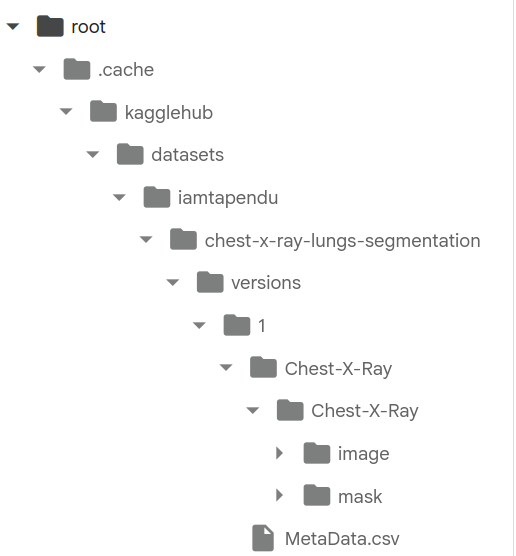

In [ ]:
import os

os.listdir(path)

['MetaData.csv', 'Chest-X-Ray']

In [ ]:
os.listdir(os.path.join(path, 'Chest-X-Ray'))

['Chest-X-Ray']

In [ ]:
os.listdir(os.path.join(path, 'Chest-X-Ray', 'Chest-X-Ray'))

['image', 'mask']

In [ ]:
list_images = os.listdir(os.path.join(path, 'Chest-X-Ray', 'Chest-X-Ray', 'image'))

In [ ]:
len(list_images)

704

In [ ]:
list_masks = os.listdir(os.path.join(path, 'Chest-X-Ray', 'Chest-X-Ray', 'mask'))

In [ ]:
len(list_masks)

704

In [ ]:
import pandas as pd
import os

metadata = pd.read_csv(os.path.join(path, 'MetaData.csv'))
display(metadata.head())

,id,gender,age,county,ptb,remarks
0,1000,male,31,Shenxhen,0,normal
1,1001,male,64,Shenxhen,0,normal
2,1002,male,35,Shenxhen,0,normal
3,1003,male,32,Shenxhen,1,"STB,ATB,tuberculosis pleuritis"
4,1004,male,2,Shenxhen,1,secondary PTB in the bilateral upper field


In [ ]:
metadata.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 704 entries, 0 to 703
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   id       704 non-null    int64 
 1   gender   704 non-null    object
 2   age      704 non-null    object
 3   county   704 non-null    object
 4   ptb      704 non-null    int64 
 5   remarks  699 non-null    object
dtypes: int64(2), object(4)
memory usage: 33.1+ KB


In [ ]:
metadata['ptb'].value_counts(normalize=True)

,proportion
ptb,
0,0.509943
1,0.490057


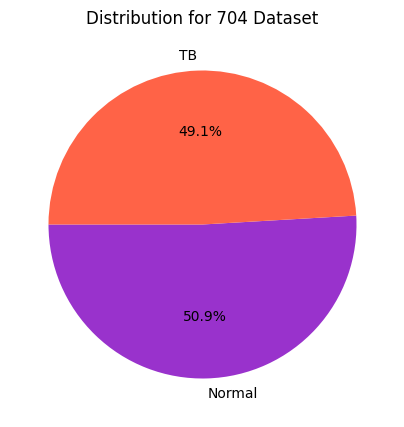

In [ ]:
import matplotlib.pyplot as plt

counts_704 = metadata['ptb'].value_counts()

labels = ['Normal', 'TB']

plt.figure(figsize=(5, 5))
plt.pie(counts_704, labels=labels, autopct='%1.1f%%', startangle=180, colors=['darkorchid', 'tomato'])
plt.title('Class Distribution for 704 Dataset')
plt.show()

In [ ]:
metadata['county'].value_counts()

,count
county,
Shenxhen,566
Montgomery,138


In [ ]:
metadata['id'].max()

1703

#### Gender analysis

In [ ]:
metadata['gender'].value_counts()

,count
gender,
male,358
female,176
F,74
M,63
Male,12
"Male,",6
"Female,",5
femal,3
Female,3


,count
gender,
male,441
female,262


ptb,0,1
gender,,
female,149,113
male,209,232


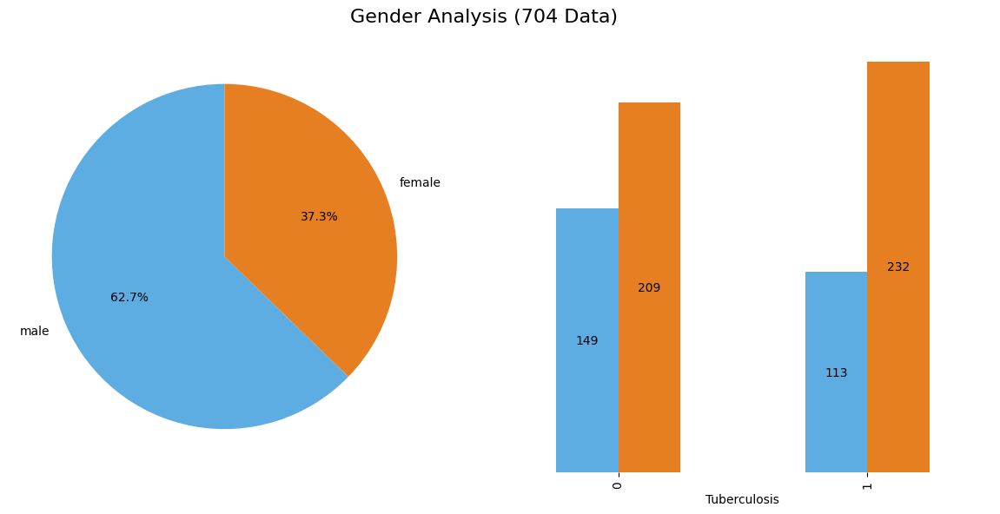

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Step 1: Normalize gender strings (lowercase)
metadata['gender'] = metadata['gender'].str.lower()

# Step 2: Drop the unknown 'o' entry (as requested)
metadata = metadata[metadata['gender'] != 'o']

# Step 3: Define mapping for all observed lowercase variants
gender_mapping = {
    'male': 'male',          # already male
    'm': 'male',             # 'M' becomes 'm'
    'male,': 'male',         # 'Male,' becomes 'male,'
    'male35yrs': 'male',     # 'male35yrs'
    'female': 'female',      # already female
    'f': 'female',           # 'F' becomes 'f'
    'femal': 'female',       # 'femal'
    'female,': 'female',     # 'Female,' becomes 'female,'
    'female24yrs': 'female'  # 'female24yrs'
}

# Step 4: Apply mapping
metadata['gender'] = metadata['gender'].replace(gender_mapping)

# Step 5: Verify that only 'male' and 'female' remain (optional)
display(metadata['gender'].value_counts())

# Step 6: Create visualizations
agg_data = metadata['gender'].value_counts()           # counts for pie/bar
ct = pd.crosstab(metadata['gender'], metadata['ptb'])  # gender vs. ptb
display(ct)

plt.figure(figsize=(12, 6))

# Pie chart
plt.subplot(121)
plt.pie(agg_data, labels=agg_data.index, autopct='%1.1f%%',
        startangle=90, colors=['#5DADE2', '#E67E22'])

# Bar chart of counts
# plt.subplot(132)
# bars = plt.bar(agg_data.index, agg_data, color=['#5DADE2', '#E67E22'])
# plt.bar_label(bars, labels=[str(h) for h in agg_data], label_type='center')
# plt.yticks([])
# plt.box(False)

# Grouped bar chart for gender vs. tuberculosis (ptb)
plt.subplot(122)
ct.T.plot(kind='bar', color=['#5DADE2', '#E67E22'], ax=plt.gca(),legend = False)
bars = plt.gca().containers
for bar_container in bars:
    plt.bar_label(bar_container, label_type='center')
plt.xlabel('Tuberculosis')
plt.yticks([])
plt.box(False)

plt.suptitle('Gender Analysis (704 Data)', fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
plt.bar_label?

In [ ]:
metadata['gender'].value_counts(normalize = True)

,proportion
gender,
male,0.508523
female,0.250000
F,0.105114
M,0.089489
Male,0.017045
"Male,",0.008523
"Female,",0.007102
femal,0.004261
Female,0.004261


In [ ]:
metadata['age'].head(10)

,age
0,31
1,64
2,35
3,32
4,2
5,17
6,25
7,30
8,27
9,31


In [ ]:
metadata['age'].unique()

array(['31', '64', '35', '32', '2', '17', '25', '30', '27', '37', '26',
       '46', '57', '23', '33', '45', '74', '48', '20', '56', '39', '43',
       '38', '65', '28', '47', '60', '29', '34', '5', '22', '24', '68',
       '42', '18', '1', '78', '53', '21', '59', '8', '63', '75', '19',
       '36', '51', '40', '69', '61', '41', '15', '49', '52', '62', '85',
       '50', '44', '71', '10', '58', '55', '1yr', '6', '76', '7', '54',
       '39yr', '16month', '3', '67', '81', 'male35', '70', 'female24',
       '14', '82', '89', '035', '032', '061', '046', '077', '049', '053',
       '043', '039', '030', '024', '037', '028', '009', '011', '063',
       '031', '067', '021', '052', '038', '044', '054', '088', '014',
       '047', '042', '020', '008', '033', '034', '051', '005', '015',
       '025', '016', '045', '048', '069', '065', '036', '050', '056',
       '089', '017', '041', '027', '023', '026', '029', '070', '018',
       '040', '010', '019', '004', '084', '085', '068', '059', '073'],
 

#### Age Analysis

In [ ]:
metadata['ptb'].value_counts()

,count
ptb,
0,358
1,345


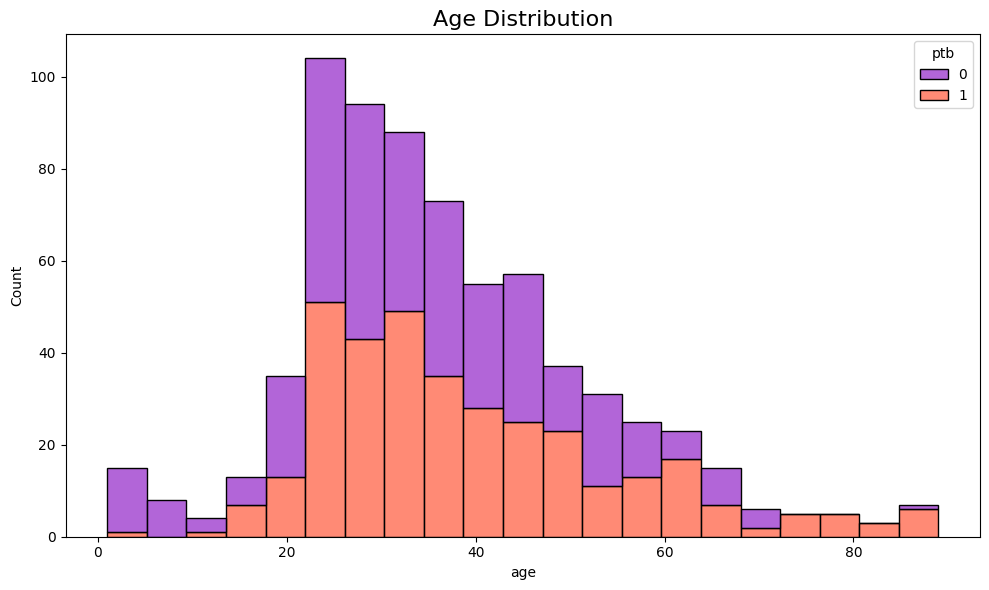

In [ ]:
import seaborn as sns

metadata.age = (metadata.age
                .replace({'16month':'1','39yr':'39','1yr':'1','male35':'35','female24':'24'})
                .astype(int))

custom_palette = ['darkorchid','tomato']

plt.figure(figsize=(10,6))

# plt.subplot(122)
sns.histplot(data=metadata, x='age', hue='ptb', palette=custom_palette, multiple='stack')

plt.title('Age Distribution',fontsize=16)
plt.tight_layout()
plt.show()

## SET UP OF THE DATABASE

In [4]:
def create_split_folders(path):

  import os
  import pandas as pd

  # load the metadata
  metadata = pd.read_csv(os.path.join(path, 'MetaData.csv'))
  display (metadata.head())

  # Get the ids of the images corr to TB and no-TB
  img_id1 = list (metadata['id'][metadata['ptb'] == 1])
  img_id0 = list(metadata['id'][metadata['ptb'] == 0])

  print()
  print(f'# of TB images: {len(img_id1)}')
  print(f'# of Normal images: {len(img_id0)}')
  print(f'Total: {len(img_id1) + len(img_id0)}')

  # We will split train, validation and test set using 70%, 20% and 10%.
  # We will consider these ratios at the class level since we want every set
  # have a balanced number of images wrt the classes.

  train_ratio = 0.7
  val_ratio = 0.2
  test_ratio = 0.1

  # int uses floor, so the test set will have a couple more images than intended
  train_no_1 = int(train_ratio * len(img_id1))
  train_no_0 = int(train_ratio * len(img_id0))
  print(f'Train: {train_no_1} + {train_no_0} = {train_no_1 + train_no_0}')

  val_no_1 = int(val_ratio * len(img_id1))
  val_no_0 = int(val_ratio * len(img_id0))
  print(f'Validation: {val_no_1} + {val_no_0} = {val_no_1 + val_no_0}')

  test_no_1 = int(test_ratio * len(img_id1))
  test_no_0 = int(test_ratio * len(img_id0))
  print(f'Test: {test_no_1} + {test_no_0} = {test_no_1 + test_no_0}')

  # split
  train_1 = img_id1[:train_no_1]
  train_0 = img_id0[:train_no_0]
  train = train_1 + train_0
  print(f'Train set #: {len(train)}')

  val_1 = img_id1[train_no_1:train_no_1 + val_no_1]
  val_0 = img_id0[train_no_0:train_no_0 + val_no_0]
  val = val_1 + val_0
  print(f'Validation set #: {len(val)}')

  test_1 = img_id1[train_no_1 + val_no_1:]
  test_0 = img_id0[train_no_0 + val_no_0:]
  test = test_1 + test_0
  print(f'Test set #: {len(test)}')

  print(f'Total: {len(train) + len(val) + len(test)}')
  print()


  # Setup directories
  import os
  import shutil

  sets = ['train', 'val', 'test']
  klases = ['tb', 'no_tb']

  # get current directory
  current_path = os.getcwd()

  for st in sets:
    for klas in klases:
        if not os.path.exists(os.path.join(current_path, st, klas)):
          os.makedirs(os.path.join(current_path, st, klas))

  # path to the images
  path_images = os.path.join(path, 'Chest-X-Ray/Chest-X-Ray/image')

  #train
  for i in train_1:
    str_i = str(i) + '.png' #convert id into image id string
    shutil.copy(src = os.path.join(path_images,str_i), dst = os.path.join(current_path,'train/tb'))

  for i in train_0:
    str_i = str(i) + '.png' #convert id into image id string
    shutil.copy(src = os.path.join(path_images,str_i), dst = os.path.join(current_path,'train/no_tb'))

  # val
  for i in val_1:
    str_i = str(i) + '.png' #convert id into image id string
    shutil.copy(src = os.path.join(path_images,str_i), dst = os.path.join(current_path,'val/tb'))

  for i in val_0:
    str_i = str(i) + '.png' #convert id into image id string
    shutil.copy(src = os.path.join(path_images,str_i), dst = os.path.join(current_path,'val/no_tb'))

  #test
  for i in test_1:
    str_i = str(i) + '.png' #convert id into image id string
    shutil.copy(src = os.path.join(path_images,str_i), dst = os.path.join(current_path,'test/tb'))

  for i in test_0:
    str_i = str(i) + '.png' #convert id into image id string
    shutil.copy(src = os.path.join(path_images,str_i), dst = os.path.join(current_path,'test/no_tb'))

  print (f'Successfuly created Images Directory')

  sets = ['train', 'val', 'test']
  klases = ['tb', 'no_tb']


  print ('Confirm the number of images is valid')
  for st in sets:
    for klas in klases:
      ls = os.listdir(os.path.join(current_path, st, klas))
      print (f'{st}/{klas}: {len(ls)}')


  return img_id1, img_id0

# Apply function
img_id1, img_id0 = create_split_folders(path)

,id,gender,age,county,ptb,remarks
0,1000,male,31,Shenxhen,0,normal
1,1001,male,64,Shenxhen,0,normal
2,1002,male,35,Shenxhen,0,normal
3,1003,male,32,Shenxhen,1,"STB,ATB,tuberculosis pleuritis"
4,1004,male,2,Shenxhen,1,secondary PTB in the bilateral upper field



# of TB images: 345
# of Normal images: 359
Total: 704
Train: 241 + 251 = 492
Validation: 69 + 71 = 140
Test: 34 + 35 = 69
Train set #: 492
Validation set #: 140
Test set #: 72
Total: 704

Successfuly created Images Directory
Confirm the number of images is valid
train/tb: 241
train/no_tb: 251
val/tb: 69
val/no_tb: 71
test/tb: 35
test/no_tb: 37


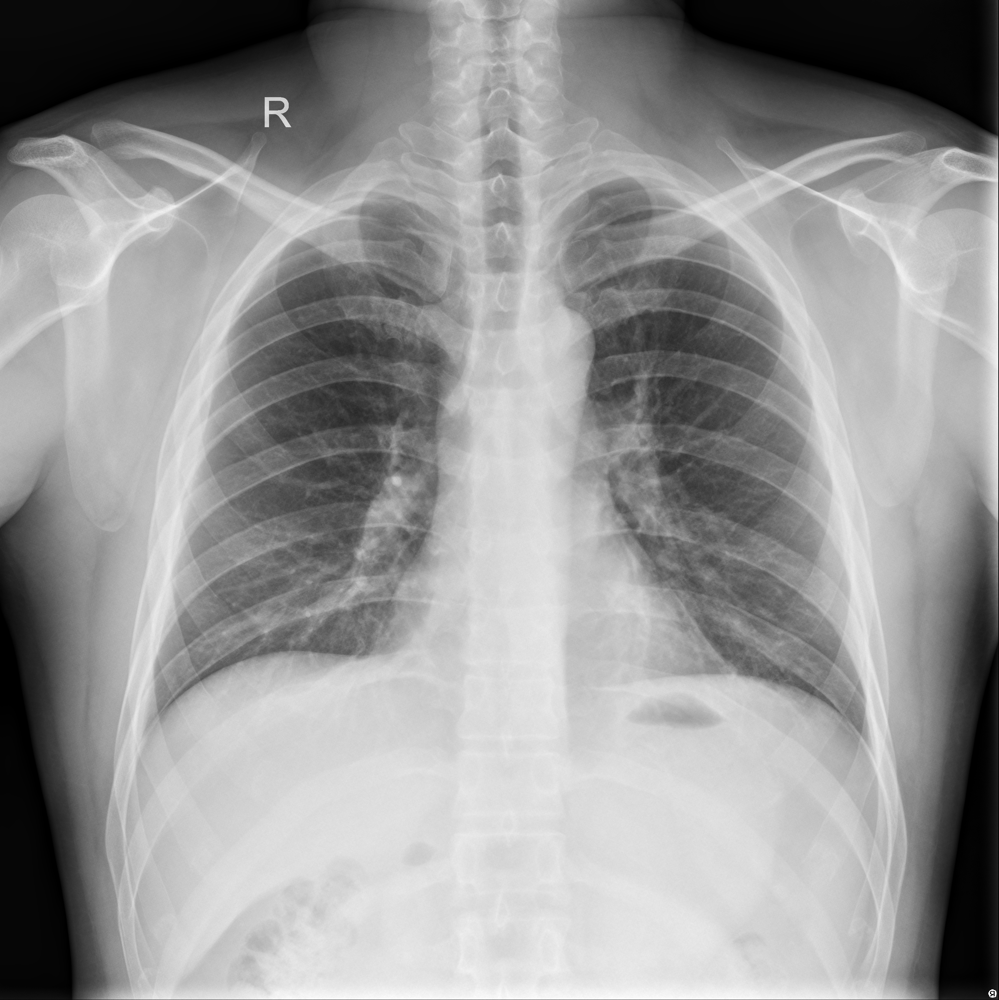

In [ ]:
# show sample image

import PIL

path_image = './train/no_tb/1000.png'
PIL.Image.open(path_image)

## EXPERIMENT 1 (without augmentation)

Key observations

- Regularization improves the performance on the test set.
- Dropout is observed to be better than augmentation or batch norm.
- A simple CONV net with 2 layers showed the best performance than more deeper ones.

### Data Pipeline

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torch.optim as optim


from torchvision import transforms as T
from torchvision.datasets import ImageFolder

import matplotlib.pyplot as plt

from torchview import draw_graph
# from utils import model_train_save, model_predict, plot_results_new

# TRANSFORMS

transforms = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor()
])

# TENSOR DATASETS
train_td = ImageFolder(root = './train', transform = transforms)
val_td = ImageFolder(root = './val', transform = transforms)
test_td = ImageFolder(root = './test', transform = transforms)

print(train_td[0][0])

# TO BATCHES
train_dl = DataLoader(train_td, batch_size = 32, shuffle = True)
val_dl = DataLoader(val_td, batch_size = 32)
test_dl = DataLoader(test_td, batch_size = 32)

tensor([[[0.0353, 0.0353, 0.0353,  ..., 0.0706, 0.1059, 0.1529],
         [0.0353, 0.0353, 0.0353,  ..., 0.0667, 0.1020, 0.1490],
         [0.0353, 0.0353, 0.0353,  ..., 0.0667, 0.1020, 0.1490],
         ...,
         [0.0275, 0.0275, 0.0275,  ..., 0.0941, 0.2863, 0.1765],
         [0.0471, 0.0471, 0.0431,  ..., 0.2745, 0.6000, 0.4157],
         [0.0588, 0.0588, 0.0588,  ..., 0.1647, 0.4039, 0.2588]],

        [[0.0353, 0.0353, 0.0353,  ..., 0.0706, 0.1059, 0.1529],
         [0.0353, 0.0353, 0.0353,  ..., 0.0667, 0.1020, 0.1490],
         [0.0353, 0.0353, 0.0353,  ..., 0.0667, 0.1020, 0.1490],
         ...,
         [0.0275, 0.0275, 0.0275,  ..., 0.0941, 0.2863, 0.1765],
         [0.0471, 0.0471, 0.0431,  ..., 0.2745, 0.6000, 0.4157],
         [0.0588, 0.0588, 0.0588,  ..., 0.1647, 0.4039, 0.2588]],

        [[0.0353, 0.0353, 0.0353,  ..., 0.0706, 0.1059, 0.1529],
         [0.0353, 0.0353, 0.0353,  ..., 0.0667, 0.1020, 0.1490],
         [0.0353, 0.0353, 0.0353,  ..., 0.0667, 0.1020, 0.

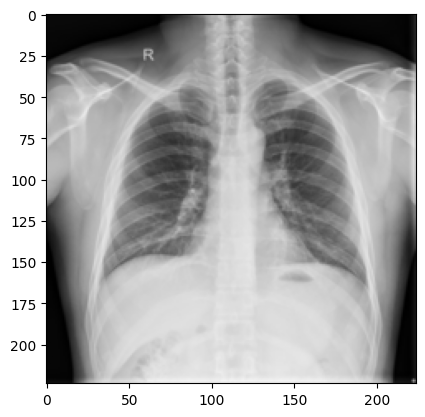

In [ ]:
plt.imshow(train_td[0][0].permute(1, 2, 0));

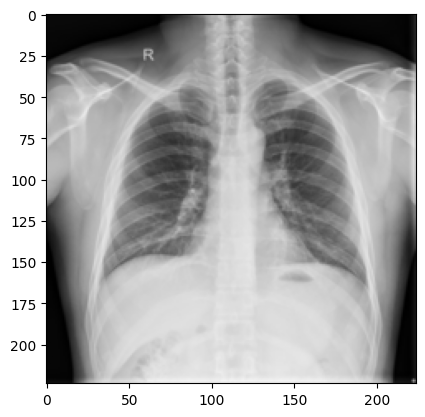

In [ ]:
plt.imshow(train_td[0][0].permute(1, 2, 0), cmap = 'gray');

### run 1 (complex without regu)

setup
- 4 CONV blocks, increasing filters (32-256)
- 1 Dense layer

results
- model trains to about 90% accuracy
- validation accuracy does not exceed 61%
- test set acc is just 49%, worse than guessing

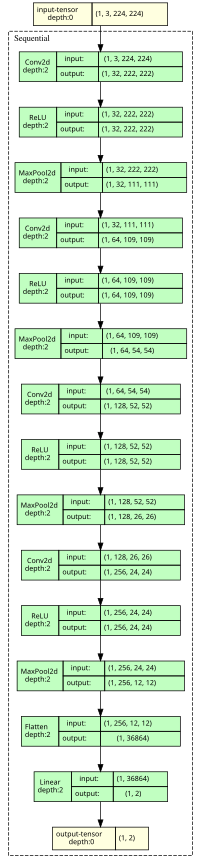

In [ ]:
class CNN(nn.Module):

  def __init__(self, n_classes = 2):
    super().__init__()

    self.layers = nn.Sequential (
        nn.Conv2d(in_channels=3, out_channels = 32, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2),

        nn.Conv2d(32, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),

        nn.Conv2d(64, 128, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),

        nn.Conv2d(128, 256, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),

        nn.Flatten(),
        nn.Linear(36864, 2)
    )

  def forward(self, x):
    return self.layers(x)

model = CNN()

model_graph = draw_graph(model, input_size=(1, 3, 224, 224),
                         expand_nested=True,
                         hide_inner_tensors=True,
                         hide_module_functions=True
                         )

model_graph.visual_graph

Epoch: [1/30]	 Train Loss: 0.72	 Val Loss: 0.69	 Val Acc = 0.50
Epoch: [2/30]	 Train Loss: 0.65	 Val Loss: 0.78	 Val Acc = 0.49
Epoch: [3/30]	 Train Loss: 0.55	 Val Loss: 0.86	 Val Acc = 0.54
Epoch: [4/30]	 Train Loss: 0.54	 Val Loss: 0.85	 Val Acc = 0.60
Epoch: [5/30]	 Train Loss: 0.48	 Val Loss: 1.25	 Val Acc = 0.57
Epoch: [6/30]	 Train Loss: 0.50	 Val Loss: 1.20	 Val Acc = 0.57
Epoch: [7/30]	 Train Loss: 0.47	 Val Loss: 0.95	 Val Acc = 0.60
Epoch: [8/30]	 Train Loss: 0.45	 Val Loss: 1.22	 Val Acc = 0.55
Epoch: [9/30]	 Train Loss: 0.46	 Val Loss: 1.15	 Val Acc = 0.56
Epoch: [10/30]	 Train Loss: 0.43	 Val Loss: 1.60	 Val Acc = 0.55
Epoch: [11/30]	 Train Loss: 0.46	 Val Loss: 1.47	 Val Acc = 0.53
Epoch: [12/30]	 Train Loss: 0.43	 Val Loss: 1.38	 Val Acc = 0.59
Epoch: [13/30]	 Train Loss: 0.41	 Val Loss: 2.43	 Val Acc = 0.56
Epoch: [14/30]	 Train Loss: 0.45	 Val Loss: 1.35	 Val Acc = 0.56
Epoch: [15/30]	 Train Loss: 0.45	 Val Loss: 1.63	 Val Acc = 0.59
Epoch: [16/30]	 Train Loss: 0.40	 

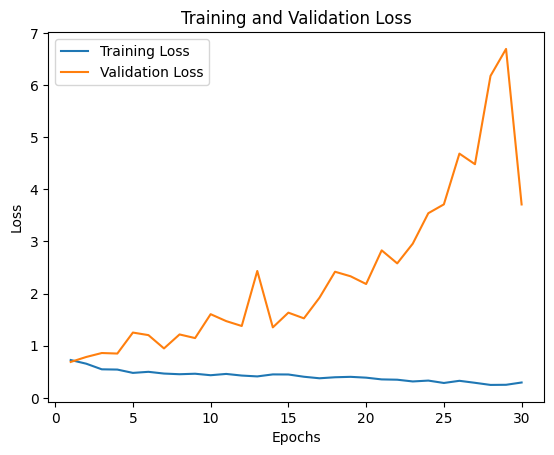

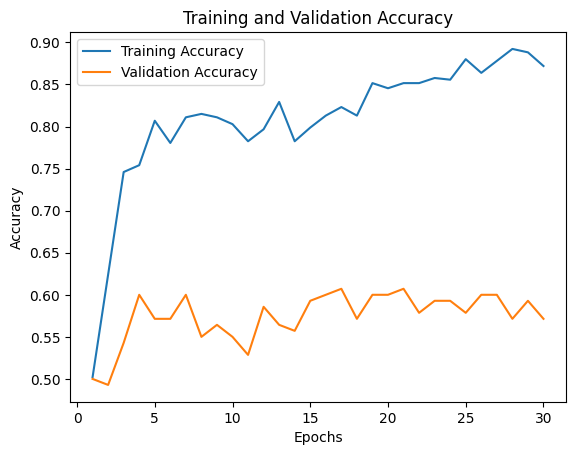

Test set accuracy: 0.49


In [ ]:
# device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# optimizer
optimizer = optim.Adam(model.parameters(), lr = 0.001)

#loss function
loss_fn = nn.CrossEntropyLoss()

# save path
save_path = './ex1_run1.pt'

history = model_train_save(model, train_dl, val_dl,
             optimizer, loss_fn, save_path, epochs = 30, device = device
)

#plot
plot_results_new(history)

#predict
predictions, labels = model_predict(save_path, test_dl, device)

### run 2 (+model complexity, dropout)

setup ( I am not very sure coz the class definition is not present)
- Still 4 CONV layers, but more filters (64-512)
- More dense layers
- Dropout


results
- few epochs are used, so trend is not clear
- training acc reduces, so model does not memorize
- validation acc reaches 67%
- test acc incr to 61%

Epoch: [1/10]	 Train Loss: 2.56	 Val Loss: 0.72	 Val Acc = 0.49
Epoch: [2/10]	 Train Loss: 0.69	 Val Loss: 0.69	 Val Acc = 0.54
Epoch: [3/10]	 Train Loss: 0.69	 Val Loss: 0.70	 Val Acc = 0.51
Epoch: [4/10]	 Train Loss: 0.67	 Val Loss: 0.69	 Val Acc = 0.57
Epoch: [5/10]	 Train Loss: 0.63	 Val Loss: 0.67	 Val Acc = 0.67
Epoch: [6/10]	 Train Loss: 0.55	 Val Loss: 0.76	 Val Acc = 0.56
Epoch: [7/10]	 Train Loss: 0.51	 Val Loss: 0.88	 Val Acc = 0.57
Epoch: [8/10]	 Train Loss: 0.50	 Val Loss: 0.84	 Val Acc = 0.58
Epoch: [9/10]	 Train Loss: 0.50	 Val Loss: 0.85	 Val Acc = 0.55
Epoch: [10/10]	 Train Loss: 0.49	 Val Loss: 1.13	 Val Acc = 0.59


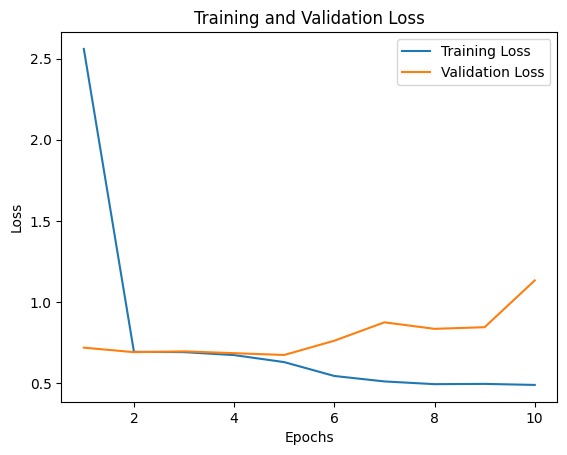

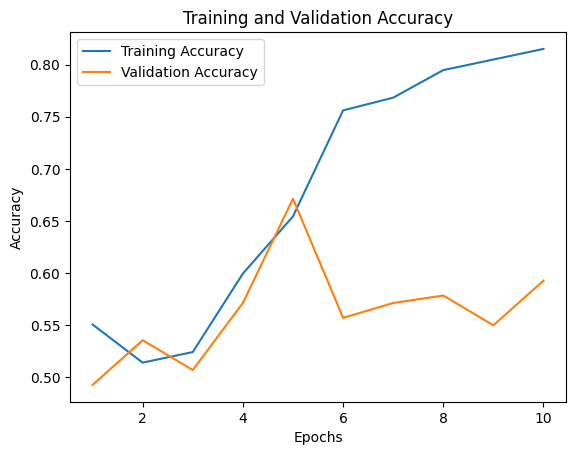

Test set accuracy: 0.61


In [ ]:
# device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# optimizer
optimizer = optim.Adam(model.parameters(), lr = 0.001)

#loss function
loss_fn = nn.CrossEntropyLoss()

# save path
save_path = './ex1_run1.pt'

history = model_train_save(model, train_dl, val_dl,
             optimizer, loss_fn, save_path, epochs = 10, device = device
)

#plot
plot_results_new(history)

#predict
predictions, labels = model_predict(save_path, test_dl, device)

### run 3

setup
- same as run 2 (which makes me doubt run 2)

results
- bad. few epochs contributed to it

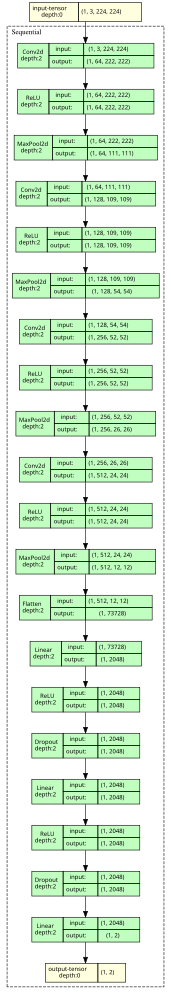

In [ ]:
class CNN(nn.Module):

  def __init__(self, n_classes = 2):
    super().__init__()

    self.layers = nn.Sequential (
        nn.Conv2d(in_channels=3, out_channels = 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2),

        nn.Conv2d(64, 128, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),

        nn.Conv2d(128, 256, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),

        nn.Conv2d(256, 512, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),

        nn.Flatten(),
        nn.Linear(73728, 2048),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(2048, 2048),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(2048, 2)
    )

  def forward(self, x):
    return self.layers(x)

model = CNN()

model_graph = draw_graph(model, input_size=(1, 3, 224, 224),
                         expand_nested=True,
                         hide_inner_tensors=True,
                         hide_module_functions=True
                         )

model_graph.visual_graph

Epoch: [1/10]	 Train Loss: 1.13	 Val Loss: 0.69	 Val Acc = 0.49
Epoch: [2/10]	 Train Loss: 0.69	 Val Loss: 0.69	 Val Acc = 0.49
Epoch: [3/10]	 Train Loss: 0.69	 Val Loss: 0.69	 Val Acc = 0.51
Epoch: [4/10]	 Train Loss: 0.69	 Val Loss: 0.69	 Val Acc = 0.53
Epoch: [5/10]	 Train Loss: 0.63	 Val Loss: 0.97	 Val Acc = 0.51
Epoch: [6/10]	 Train Loss: 0.52	 Val Loss: 1.19	 Val Acc = 0.59
Epoch: [7/10]	 Train Loss: 0.53	 Val Loss: 0.82	 Val Acc = 0.57
Epoch: [8/10]	 Train Loss: 0.48	 Val Loss: 1.08	 Val Acc = 0.55
Epoch: [9/10]	 Train Loss: 0.47	 Val Loss: 1.25	 Val Acc = 0.56
Epoch: [10/10]	 Train Loss: 0.47	 Val Loss: 1.11	 Val Acc = 0.55


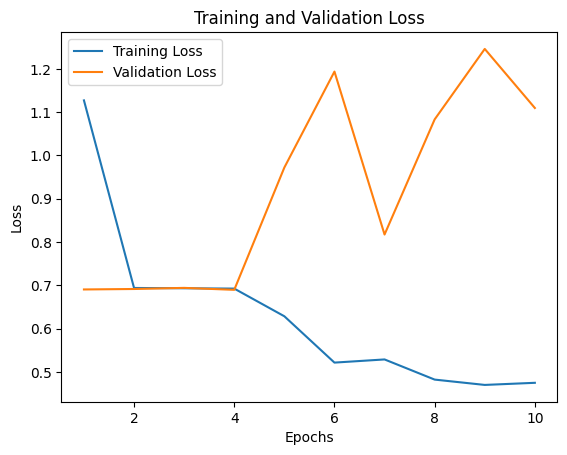

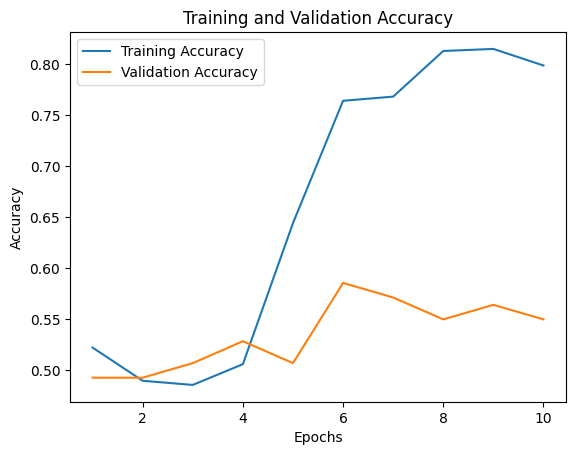

Test set accuracy: 0.49


In [ ]:
# device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# optimizer
optimizer = optim.Adam(model.parameters(), lr = 0.001)

#loss function
loss_fn = nn.CrossEntropyLoss()

# save path
save_path = './ex1_run1.pt'

history = model_train_save(model, train_dl, val_dl,
             optimizer, loss_fn, save_path, epochs = 10, device = device
)

#plot
plot_results_new(history)

#predict
predictions, labels = model_predict(save_path, test_dl, device)

### run 4

setup
- 3 CONV layers, reducing fliters (123, 64, 64)
- 2 dense layers
- Dropout in CONV and deep (0.3, 0.5, 0.5, 0.2)

results
- few epochs are used, so trend is not clear
- training acc goes to 80 max, so model does not memorize
- validation acc reaches 61%
- test acc incr to 60%. not sure this will be robust though, coz i don't see a good trend in training

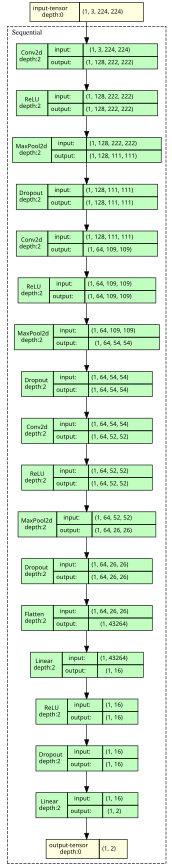

In [ ]:
class CNN(nn.Module):

  def __init__(self, n_classes = 2):
    super().__init__()

    self.layers = nn.Sequential (
        nn.Conv2d(in_channels=3, out_channels = 128, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2),
        nn.Dropout(0.3),

        nn.Conv2d(128, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.5),

        nn.Conv2d(64, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.5),

        nn.Flatten(),
        nn.Linear(43264, 16),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(16, 2),
    )

  def forward(self, x):
    return self.layers(x)

model = CNN()

model_graph = draw_graph(model, input_size=(1, 3, 224, 224),
                         expand_nested=True,
                         hide_inner_tensors=True,
                         hide_module_functions=True
                         )

model_graph.visual_graph

Epoch: [1/10]	 Train Loss: 0.71	 Val Loss: 0.69	 Val Acc = 0.44
Epoch: [2/10]	 Train Loss: 0.68	 Val Loss: 0.69	 Val Acc = 0.53
Epoch: [3/10]	 Train Loss: 0.64	 Val Loss: 0.68	 Val Acc = 0.61
Epoch: [4/10]	 Train Loss: 0.61	 Val Loss: 0.67	 Val Acc = 0.58
Epoch: [5/10]	 Train Loss: 0.60	 Val Loss: 0.67	 Val Acc = 0.60
Epoch: [6/10]	 Train Loss: 0.61	 Val Loss: 0.68	 Val Acc = 0.54
Epoch: [7/10]	 Train Loss: 0.67	 Val Loss: 0.75	 Val Acc = 0.53
Epoch: [8/10]	 Train Loss: 0.56	 Val Loss: 1.34	 Val Acc = 0.55
Epoch: [9/10]	 Train Loss: 0.51	 Val Loss: 1.46	 Val Acc = 0.54
Epoch: [10/10]	 Train Loss: 0.50	 Val Loss: 1.22	 Val Acc = 0.59


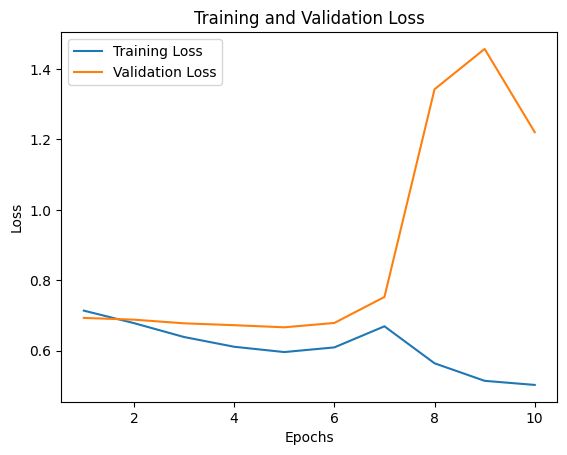

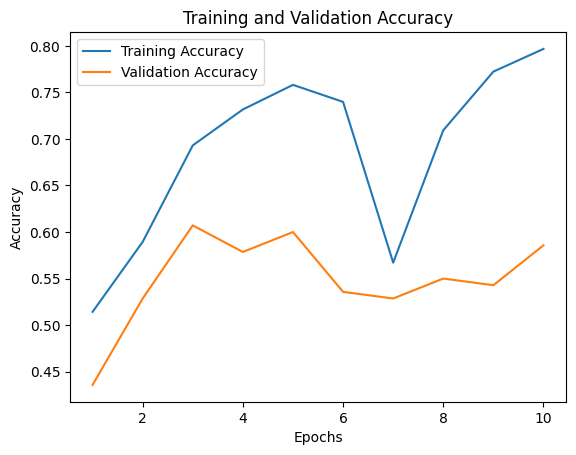

Test set accuracy: 0.60


In [ ]:
# device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# optimizer
optimizer = optim.Adam(model.parameters(), lr = 0.001)

#loss function
loss_fn = nn.CrossEntropyLoss()

# save path
save_path = './ex1_run1.pt'

history = model_train_save(model, train_dl, val_dl,
             optimizer, loss_fn, save_path, epochs = 10, device = device
)

#plot
plot_results_new(history)

#predict
predictions, labels = model_predict(save_path, test_dl, device)

### run 5 (small CONV).. BEST!

setup
- just 2 CONV (32, 64).. dropout (0.25, 0.25)
- 2 dense.. dropout (0.25)


results
- 25 epochs are used.. better view..
- training acc shoots to 90%
- validation acc goes to 73%
- test acc incr to 64%

obs
- this is somewhat weird considering how less complex the model is. Maybe the # of epochs helped, but considering initially we had 30 epochs but had bad results with and without dropout.. the answer for this dataset may be a less complex model is better.. the fact that it does well on the training set even with dropout is good, that means without dropout it may have done better on the training set.

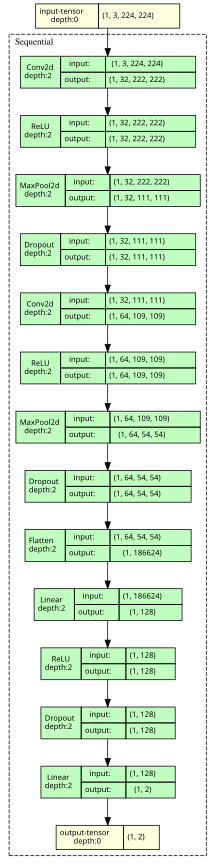

In [ ]:
class CNN(nn.Module):

  def __init__(self, n_classes = 2):
    super().__init__()

    self.layers = nn.Sequential (
        nn.Conv2d(in_channels=3, out_channels = 32, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2),
        nn.Dropout(0.25),

        nn.Conv2d(32, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.25),

        nn.Flatten(),
        nn.Linear(186624, 128),
        nn.ReLU(),
        nn.Dropout(0.25),
        nn.Linear(128, 2),
    )

  def forward(self, x):
    return self.layers(x)

model = CNN()

model_graph = draw_graph(model, input_size=(1, 3, 224, 224),
                         expand_nested=True,
                         hide_inner_tensors=True,
                         hide_module_functions=True
                         )

model_graph.visual_graph

Epoch: [1/25]	 Train Loss: 2.18	 Val Loss: 0.69	 Val Acc = 0.51
Epoch: [2/25]	 Train Loss: 0.69	 Val Loss: 0.69	 Val Acc = 0.40
Epoch: [3/25]	 Train Loss: 0.67	 Val Loss: 0.67	 Val Acc = 0.63
Epoch: [4/25]	 Train Loss: 0.59	 Val Loss: 0.65	 Val Acc = 0.63
Epoch: [5/25]	 Train Loss: 0.57	 Val Loss: 0.67	 Val Acc = 0.59
Epoch: [6/25]	 Train Loss: 0.49	 Val Loss: 0.74	 Val Acc = 0.57
Epoch: [7/25]	 Train Loss: 0.49	 Val Loss: 0.83	 Val Acc = 0.62
Epoch: [8/25]	 Train Loss: 0.50	 Val Loss: 0.74	 Val Acc = 0.66
Epoch: [9/25]	 Train Loss: 0.56	 Val Loss: 0.91	 Val Acc = 0.60
Epoch: [10/25]	 Train Loss: 0.47	 Val Loss: 1.02	 Val Acc = 0.66
Epoch: [11/25]	 Train Loss: 0.42	 Val Loss: 1.09	 Val Acc = 0.65
Epoch: [12/25]	 Train Loss: 0.42	 Val Loss: 1.13	 Val Acc = 0.68
Epoch: [13/25]	 Train Loss: 0.40	 Val Loss: 1.08	 Val Acc = 0.66
Epoch: [14/25]	 Train Loss: 0.37	 Val Loss: 1.17	 Val Acc = 0.69
Epoch: [15/25]	 Train Loss: 0.38	 Val Loss: 1.31	 Val Acc = 0.69
Epoch: [16/25]	 Train Loss: 0.34	 

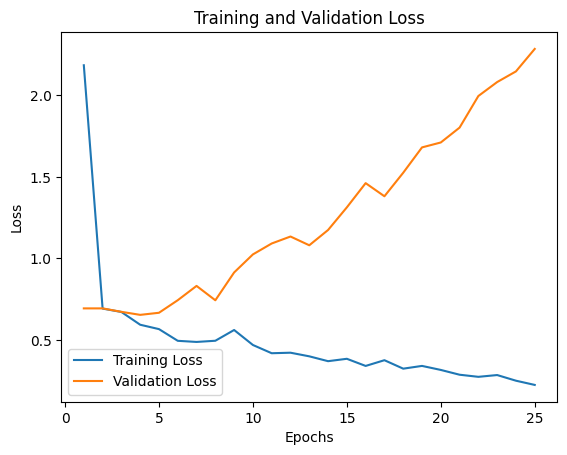

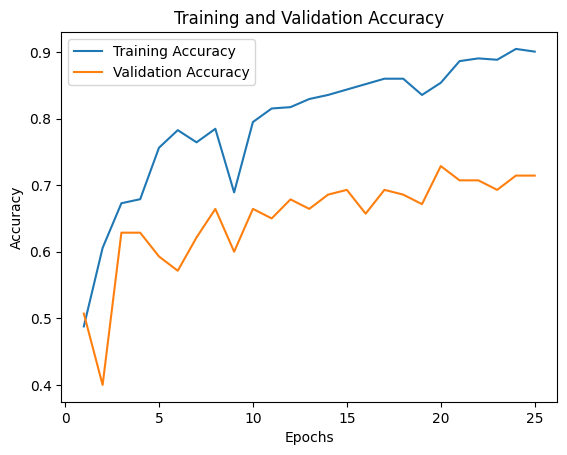

Test set accuracy: 0.64


In [ ]:
# device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# optimizer
optimizer = optim.Adam(model.parameters(), lr = 0.001)

#loss function
loss_fn = nn.CrossEntropyLoss()

# save path
save_path = './ex1_run1.pt'

history = model_train_save(model, train_dl, val_dl,
             optimizer, loss_fn, save_path, epochs = 25, device = device
)

#plot
plot_results_new(history)

#predict
predictions, labels = model_predict(save_path, test_dl, device)

### run 5 b (without dropout)

results
- train error goes to 0, acc to 100
- val error declines, then rises until 5.4 with acc incr then decr
- test set acc is 49%.. very bad

obs
- significant overfit starts from the beginning
- even a simple model as this overfits when no regularization is used

W1031 13:42:50.153000 2020 torch/_inductor/utils.py:1436] [0/0] Not enough SMs to use max_autotune_gemm mode


Epoch: [1/25]	 Train Loss: 1.69	 Val Loss: 0.70	 Val Acc = 0.51
Epoch: [2/25]	 Train Loss: 0.67	 Val Loss: 0.69	 Val Acc = 0.51
Epoch: [3/25]	 Train Loss: 0.57	 Val Loss: 0.96	 Val Acc = 0.51
Epoch: [4/25]	 Train Loss: 0.52	 Val Loss: 1.16	 Val Acc = 0.69
Epoch: [5/25]	 Train Loss: 0.48	 Val Loss: 1.12	 Val Acc = 0.69
Epoch: [6/25]	 Train Loss: 0.42	 Val Loss: 1.43	 Val Acc = 0.73
Epoch: [7/25]	 Train Loss: 0.39	 Val Loss: 1.51	 Val Acc = 0.72
Epoch: [8/25]	 Train Loss: 0.34	 Val Loss: 1.80	 Val Acc = 0.72
Epoch: [9/25]	 Train Loss: 0.31	 Val Loss: 1.61	 Val Acc = 0.70
Epoch: [10/25]	 Train Loss: 0.27	 Val Loss: 2.38	 Val Acc = 0.69
Epoch: [11/25]	 Train Loss: 0.23	 Val Loss: 1.96	 Val Acc = 0.68
Epoch: [12/25]	 Train Loss: 0.19	 Val Loss: 3.01	 Val Acc = 0.71
Epoch: [13/25]	 Train Loss: 0.15	 Val Loss: 2.53	 Val Acc = 0.66
Epoch: [14/25]	 Train Loss: 0.11	 Val Loss: 4.08	 Val Acc = 0.62
Epoch: [15/25]	 Train Loss: 0.16	 Val Loss: 2.04	 Val Acc = 0.65
Epoch: [16/25]	 Train Loss: 0.11	 

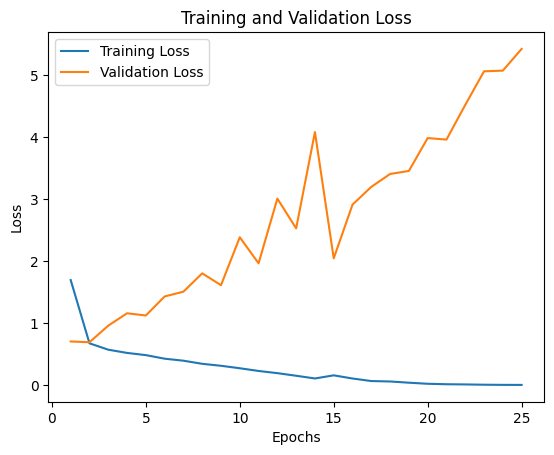

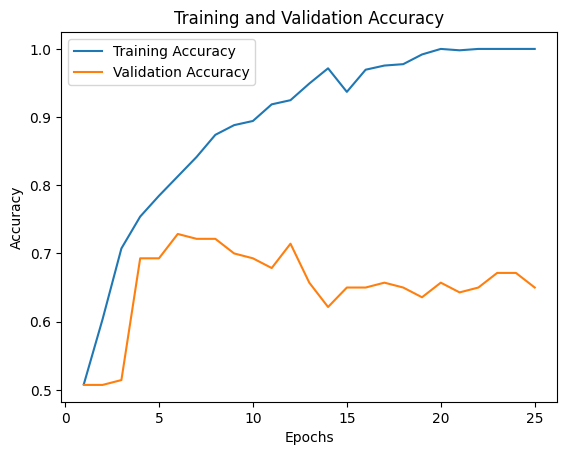

Test set accuracy: 0.49


In [ ]:
# ARCHITECTURE

class CNN(nn.Module):

  def __init__(self, n_classes = 2):
    super().__init__()

    self.layers = nn.Sequential (
        nn.Conv2d(in_channels=3, out_channels = 32, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2),

        nn.Conv2d(32, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),

        nn.Flatten(),
        nn.Linear(186624, 128),
        nn.ReLU(),
        nn.Linear(128, 2),
    )

  def forward(self, x):
    return self.layers(x)

model = CNN()

model_graph = draw_graph(model, input_size=(1, 3, 224, 224),
                         expand_nested=True,
                         hide_inner_tensors=True,
                         hide_module_functions=True
                         )

model_graph.visual_graph


# TRAINING

# device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# optimizer
optimizer = optim.Adam(model.parameters(), lr = 0.001)

#loss function
loss_fn = nn.CrossEntropyLoss()

# save path
save_path = './ex1_run1.pt'

history = model_train_save_optim(model, train_dl, val_dl,
             optimizer, loss_fn, save_path, epochs = 25, device = device
)

#plot
plot_results_new(history)


# PREDICT
predictions, labels = model_predict(save_path, test_dl, device)

### run 5c (batch_norm)

setup

- same as run 5 but with Batch norm in the CONV layers
- used 15 epochs

results
- reduction in performance across all metrics.. even comparing with the first 15 epochs of run 5

obs
- this is weird coz i have always had the sense that batch norm should improve performance

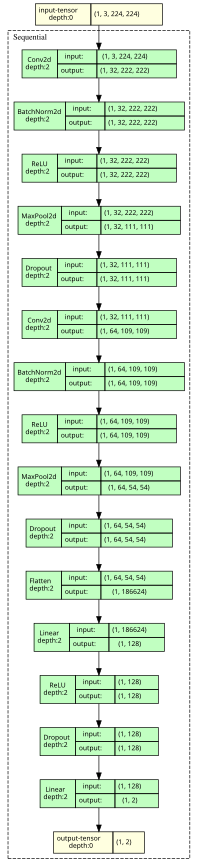

In [ ]:
class CNN(nn.Module):

  def __init__(self, n_classes = 2):
    super().__init__()

    self.layers = nn.Sequential (
        nn.Conv2d(in_channels=3, out_channels = 32, kernel_size = 3),
        nn.BatchNorm2d(32),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2),
        nn.Dropout(0.25),

        nn.Conv2d(32, 64, kernel_size = 3),
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.25),

        nn.Flatten(),
        nn.Linear(186624, 128),
        nn.ReLU(),
        nn.Dropout(0.5),
        nn.Linear(128, 2),
    )

  def forward(self, x):
    return self.layers(x)

model = CNN()

model_graph = draw_graph(model, input_size=(1, 3, 224, 224),
                         expand_nested=True,
                         hide_inner_tensors=True,
                         hide_module_functions=True
                         )

model_graph.visual_graph

Epoch: [1/15]	 Train Loss: 12.89	 Val Loss: 5.21	 Val Acc = 0.46
Epoch: [2/15]	 Train Loss: 2.59	 Val Loss: 1.50	 Val Acc = 0.56
Epoch: [3/15]	 Train Loss: 0.58	 Val Loss: 1.64	 Val Acc = 0.53
Epoch: [4/15]	 Train Loss: 0.55	 Val Loss: 1.72	 Val Acc = 0.57
Epoch: [5/15]	 Train Loss: 0.52	 Val Loss: 2.52	 Val Acc = 0.56
Epoch: [6/15]	 Train Loss: 0.54	 Val Loss: 2.26	 Val Acc = 0.56
Epoch: [7/15]	 Train Loss: 0.51	 Val Loss: 2.28	 Val Acc = 0.57
Epoch: [8/15]	 Train Loss: 0.51	 Val Loss: 2.34	 Val Acc = 0.57
Epoch: [9/15]	 Train Loss: 0.51	 Val Loss: 2.26	 Val Acc = 0.57
Epoch: [10/15]	 Train Loss: 0.48	 Val Loss: 2.16	 Val Acc = 0.56
Epoch: [11/15]	 Train Loss: 0.47	 Val Loss: 2.36	 Val Acc = 0.56
Epoch: [12/15]	 Train Loss: 0.53	 Val Loss: 2.74	 Val Acc = 0.54
Epoch: [13/15]	 Train Loss: 0.51	 Val Loss: 1.80	 Val Acc = 0.59
Epoch: [14/15]	 Train Loss: 0.52	 Val Loss: 2.37	 Val Acc = 0.56
Epoch: [15/15]	 Train Loss: 0.51	 Val Loss: 2.11	 Val Acc = 0.56


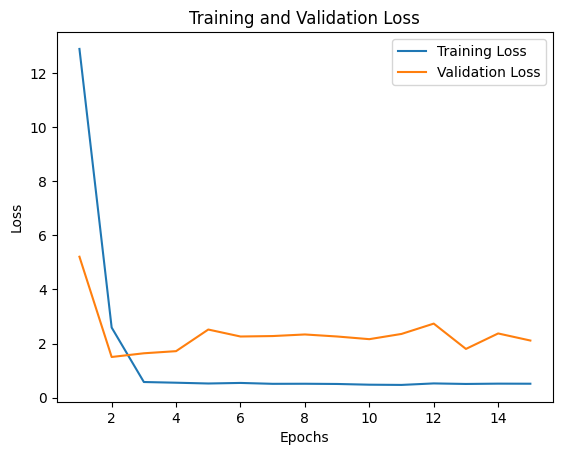

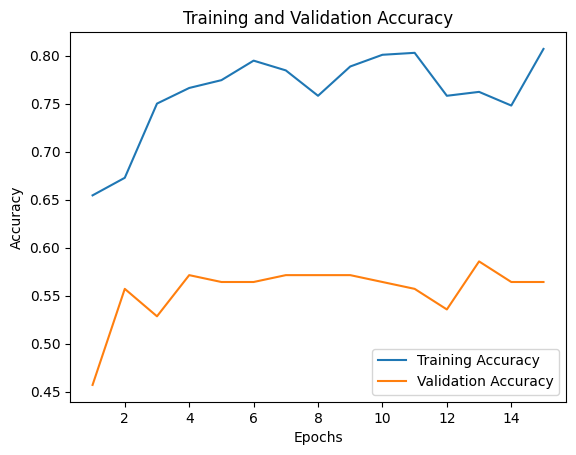

Test set accuracy: 0.53


In [ ]:
# device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# optimizer
optimizer = optim.Adam(model.parameters(), lr = 0.001)

#loss function
loss_fn = nn.CrossEntropyLoss()

# save path
save_path = './ex1_run1.pt'

history = model_train_save(model, train_dl, val_dl,
             optimizer, loss_fn, save_path, epochs = 15, device = device
)

#plot
plot_results_new(history)

#predict
predictions, labels = model_predict(save_path, test_dl, device)

### run 5d (more complex)

We double the features being learnt in the 2 layers

## EXPERIMENT 2 (with augmentation)

### Data Pipeline

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torch.optim as optim

from torchvision import transforms as T
from torchvision.datasets import ImageFolder

import matplotlib.pyplot as plt

from torchview import draw_graph

transforms = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor()
])

train_td = ImageFolder(root = './train', transform = T.Compose([
    T.Resize((224, 224)),
    T.RandomHorizontalFlip(p = 0.5),
    T.ToTensor()
]))

val_td = ImageFolder(root = './val', transform = transforms)
test_td = ImageFolder(root = './test', transform = transforms)

train_dl = DataLoader(train_td, batch_size = 32, shuffle = True)
val_dl = DataLoader(val_td, batch_size = 32)
test_dl = DataLoader(test_td, batch_size = 32)

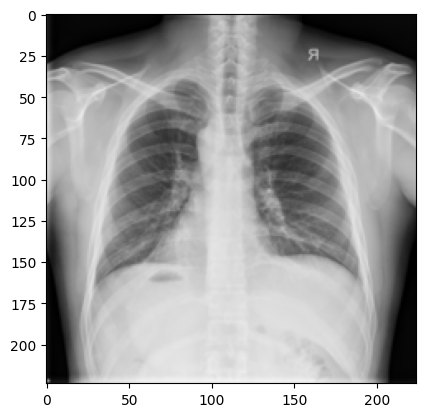

In [ ]:
plt.imshow(train_td[0][0].permute(1, 2, 0));

### run 1 (with horizontal flip)

setup

- same setup as the best model in Experiment 1
- here we introduce random horizontal flip

results
- train error does not go to 0 and acc peaks at 80
- drop in val error, but drop in val acc as well, with peak at 64
- test acc is 56 with auc of 64

obs
- it looks like augmentation is not the best overfit strategy for this model, since the performance on the train, val and test set was better in the dropout only strategy.

Epoch: [1/25]	 Train Loss: 2.70	 Val Loss: 0.69	 Train Acc = 0.53	 Val Acc = 0.49
Epoch: [2/25]	 Train Loss: 0.69	 Val Loss: 0.69	 Train Acc = 0.49	 Val Acc = 0.49
Epoch: [3/25]	 Train Loss: 0.70	 Val Loss: 0.69	 Train Acc = 0.49	 Val Acc = 0.49
Epoch: [4/25]	 Train Loss: 0.70	 Val Loss: 0.69	 Train Acc = 0.49	 Val Acc = 0.49
Epoch: [5/25]	 Train Loss: 0.69	 Val Loss: 0.69	 Train Acc = 0.50	 Val Acc = 0.49
Epoch: [6/25]	 Train Loss: 0.68	 Val Loss: 0.68	 Train Acc = 0.58	 Val Acc = 0.61
Epoch: [7/25]	 Train Loss: 0.63	 Val Loss: 0.64	 Train Acc = 0.64	 Val Acc = 0.64
Epoch: [8/25]	 Train Loss: 0.59	 Val Loss: 0.64	 Train Acc = 0.71	 Val Acc = 0.56
Epoch: [9/25]	 Train Loss: 0.59	 Val Loss: 0.63	 Train Acc = 0.69	 Val Acc = 0.61
Epoch: [10/25]	 Train Loss: 0.50	 Val Loss: 0.70	 Train Acc = 0.72	 Val Acc = 0.54
Epoch: [11/25]	 Train Loss: 0.54	 Val Loss: 0.63	 Train Acc = 0.75	 Val Acc = 0.61
Epoch: [12/25]	 Train Loss: 0.51	 Val Loss: 0.66	 Train Acc = 0.78	 Val Acc = 0.58
Epoch: [13/25

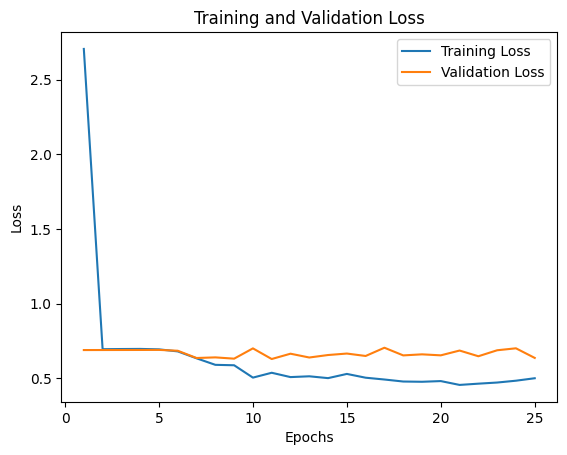

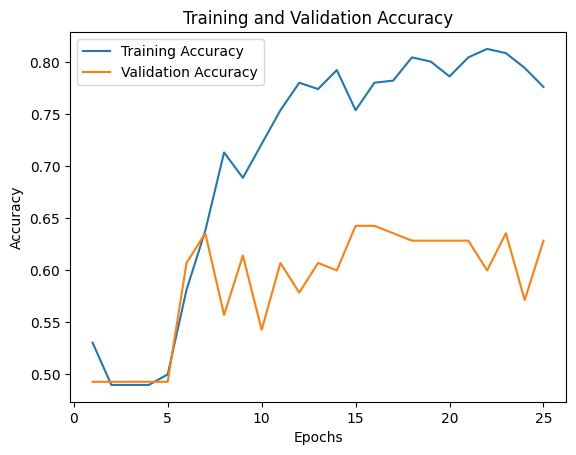

Test set accuracy: 0.56
Test set AUC: 0.64


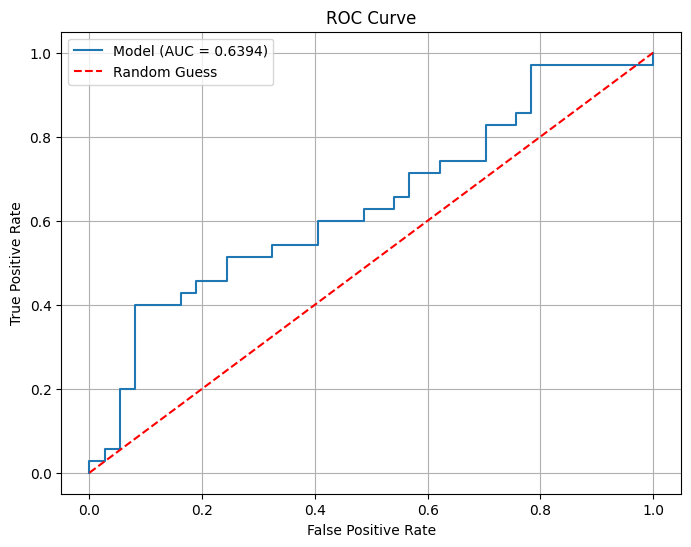

In [ ]:
class CNN(nn.Module):

  def __init__(self, n_classes = 2):
    super().__init__()

    self.layers = nn.Sequential (
        nn.Conv2d(in_channels=3, out_channels = 32, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2),
        nn.Dropout(0.25),

        nn.Conv2d(32, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.25),

        nn.Flatten(),
        nn.Linear(186624, 128),
        nn.ReLU(),
        nn.Dropout(0.25),
        nn.Linear(128, 2),
    )

  def forward(self, x):
    return self.layers(x)

model = CNN()

model_graph = draw_graph(model, input_size=(1, 3, 224, 224),
                         expand_nested=True,
                         hide_inner_tensors=True,
                         hide_module_functions=True
                         )

model_graph.visual_graph

# TRAINING
# device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# optimizer
optimizer = optim.Adam(model.parameters(), lr = 0.001)

#loss function
loss_fn = nn.CrossEntropyLoss()

# save path
save_path = './ex2_run1.pt'

history = model_train_save_optim(model, train_dl, val_dl,
             optimizer, loss_fn, save_path, epochs = 25, device = device
)

#plot
plot_results_new(history)

# total time taken for training and validation
print(f"Training time : {sum(history['Train']['Time'])}")
print(f"Validation time : {sum(history['Val']['Time'])}")

# PREDICTING
predictions, probs, labels = model_predict(save_path, test_dl, device)

### run 2 (+ rotation)

results

- train loss and acc are stable..acc peaking at 83
- both acc and auc on test set have increased as compared to only when flipping was used.. acc is 60, auc is 66

obs

- looks like it is a good idea to do both flipping and rotation. it may increase the training time though.

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torch.optim as optim

from torchvision import transforms as T
from torchvision.datasets import ImageFolder

import matplotlib.pyplot as plt

from torchview import draw_graph

transforms = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor()
])

train_td = ImageFolder(root = './train', transform = T.Compose([
    T.Resize((224, 224)),
    T.RandomHorizontalFlip(p = 0.5),
    T.RandomRotation(10),
    T.ToTensor()
]))

val_td = ImageFolder(root = './val', transform = transforms)
test_td = ImageFolder(root = './test', transform = transforms)

train_dl = DataLoader(train_td, batch_size = 32, shuffle = True)
val_dl = DataLoader(val_td, batch_size = 32)
test_dl = DataLoader(test_td, batch_size = 32)

Epoch: [1/25]	 Train Loss: 3.69	    Val Loss: 0.69	 Train Acc: 0.51	 Val Acc: 0.52    Train Time: 1.07	 Val Time: 0.5589922070503235
Epoch: [2/25]	 Train Loss: 0.69	    Val Loss: 0.69	 Train Acc: 0.57	 Val Acc: 0.46    Train Time: 0.97	 Val Time: 0.4884597937266032
Epoch: [3/25]	 Train Loss: 0.69	    Val Loss: 0.69	 Train Acc: 0.63	 Val Acc: 0.56    Train Time: 1.00	 Val Time: 0.4861236890157064
Epoch: [4/25]	 Train Loss: 0.65	    Val Loss: 0.73	 Train Acc: 0.64	 Val Acc: 0.51    Train Time: 1.06	 Val Time: 0.5719130674997965
Epoch: [5/25]	 Train Loss: 0.63	    Val Loss: 0.73	 Train Acc: 0.64	 Val Acc: 0.54    Train Time: 0.97	 Val Time: 0.5281222303708394
Epoch: [6/25]	 Train Loss: 0.56	    Val Loss: 0.88	 Train Acc: 0.68	 Val Acc: 0.56    Train Time: 1.07	 Val Time: 0.549633797009786
Epoch: [7/25]	 Train Loss: 0.51	    Val Loss: 0.79	 Train Acc: 0.76	 Val Acc: 0.56    Train Time: 1.06	 Val Time: 0.4902911464373271
Epoch: [8/25]	 Train Loss: 0.50	    Val Loss: 0.93	 Train Acc: 0.79	 V

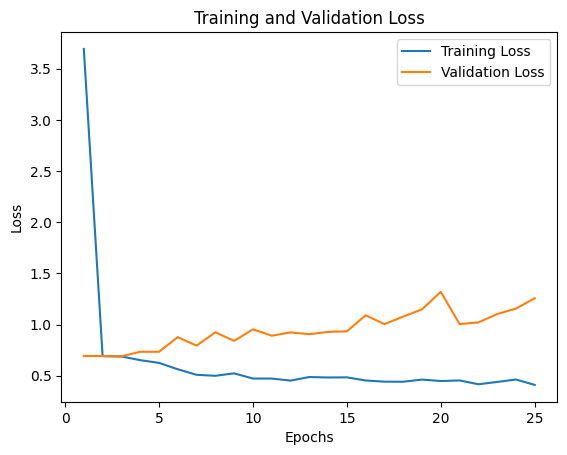

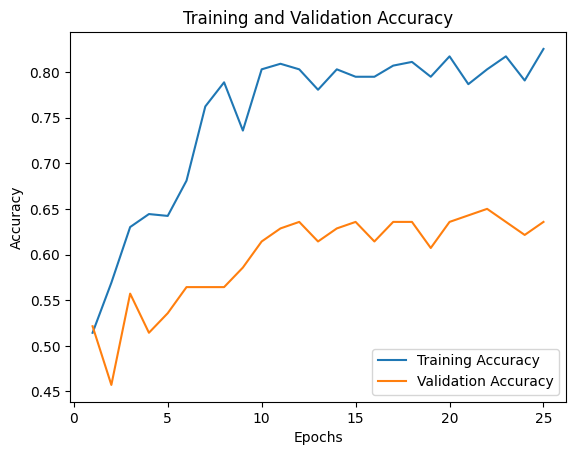

KeyError: 'Train'

In [ ]:
class CNN(nn.Module):

  def __init__(self, n_classes = 2):
    super().__init__()

    self.layers = nn.Sequential (
        nn.Conv2d(in_channels=3, out_channels = 32, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2),
        nn.Dropout(0.25),

        nn.Conv2d(32, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.25),

        nn.Flatten(),
        nn.Linear(186624, 128),
        nn.ReLU(),
        nn.Dropout(0.25),
        nn.Linear(128, 2),
    )

  def forward(self, x):
    return self.layers(x)

model = CNN()

model_graph = draw_graph(model, input_size=(1, 3, 224, 224),
                         expand_nested=True,
                         hide_inner_tensors=True,
                         hide_module_functions=True
                         )

model_graph.visual_graph

# TRAINING
# device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# optimizer
optimizer = optim.Adam(model.parameters(), lr = 0.001)

#loss function
loss_fn = nn.CrossEntropyLoss()

# save path
save_path = './ex2_run1.pt'

history = model_train_save(model, train_dl, val_dl,
             optimizer, loss_fn, save_path, epochs = 25, device = device
)

#plot
plot_results_new(history)

# total time taken for training and validation
print(f"Training time : {sum(history['Training']['Time']):.2f}")
print(f"Validation time : {sum(history['Validation']['Time']):.2f}")

# PREDICTING
predictions, probs, labels = model_predict(save_path, test_dl, device)

Training time : 25.30311440229416
Validation time : 13.14044162829717
Test set accuracy: 0.60
Test set AUC: 0.66
Time: 0.38


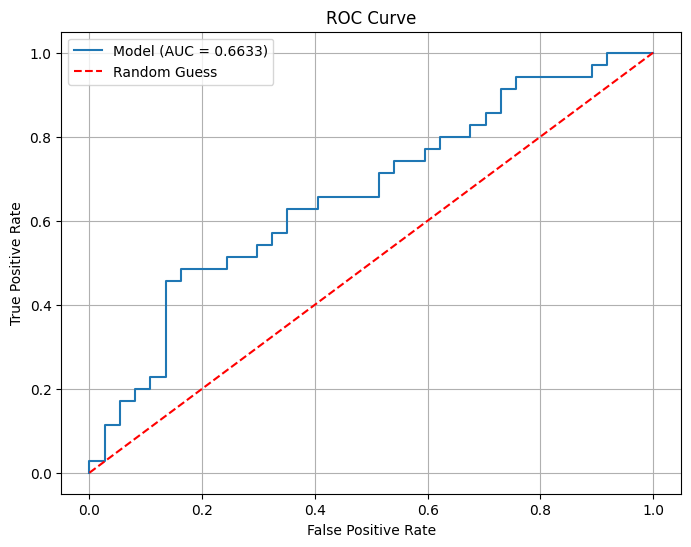

In [ ]:
# total time taken for training and validation
print(f"Training time : {sum(history['Training']['Time']):.2f}")
print(f"Validation time : {sum(history['Validation']['Time']):.2f}")

# PREDICTING
predictions, probs, labels = model_predict(save_path, test_dl, device)

### run 3 (+ model complex)

In [ ]:
path_classification = '/content/drive/MyDrive/MSc Data Science/Thesis/Codes/classification'

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torch.optim as optim

from torchvision import transforms as T
from torchvision.datasets import ImageFolder

import matplotlib.pyplot as plt

from torchview import draw_graph

transforms = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor()
])

train_td = ImageFolder(root = './train', transform = T.Compose([
    T.Resize((224, 224)),
    T.RandomHorizontalFlip(p = 0.5),
    T.RandomRotation(10),
    T.ToTensor()
]))

val_td = ImageFolder(root = './val', transform = transforms)
test_td = ImageFolder(root = './test', transform = transforms)

train_dl = DataLoader(train_td, batch_size = 32, shuffle = True)
val_dl = DataLoader(val_td, batch_size = 32)
test_dl = DataLoader(test_td, batch_size = 32)

Epoch: [1/25]	 Train Loss: 5.11	    Val Loss: 0.70	 Train Acc: 0.49	 Val Acc: 0.51    Train Time: 1.08	 Val Time: 0.50
Epoch: [2/25]	 Train Loss: 0.69	    Val Loss: 0.70	 Train Acc: 0.50	 Val Acc: 0.52    Train Time: 1.07	 Val Time: 0.51
Epoch: [3/25]	 Train Loss: 0.65	    Val Loss: 0.97	 Train Acc: 0.63	 Val Acc: 0.49    Train Time: 1.13	 Val Time: 0.50
Epoch: [4/25]	 Train Loss: 0.55	    Val Loss: 1.45	 Train Acc: 0.72	 Val Acc: 0.54    Train Time: 1.02	 Val Time: 0.51
Epoch: [5/25]	 Train Loss: 0.52	    Val Loss: 1.76	 Train Acc: 0.78	 Val Acc: 0.52    Train Time: 1.01	 Val Time: 0.51
Epoch: [6/25]	 Train Loss: 0.51	    Val Loss: 1.52	 Train Acc: 0.79	 Val Acc: 0.55    Train Time: 1.02	 Val Time: 0.50
Epoch: [7/25]	 Train Loss: 0.49	    Val Loss: 1.52	 Train Acc: 0.78	 Val Acc: 0.55    Train Time: 1.03	 Val Time: 0.49
Epoch: [8/25]	 Train Loss: 0.51	    Val Loss: 1.27	 Train Acc: 0.77	 Val Acc: 0.55    Train Time: 1.04	 Val Time: 0.51
Epoch: [9/25]	 Train Loss: 0.47	    Val Loss: 1.

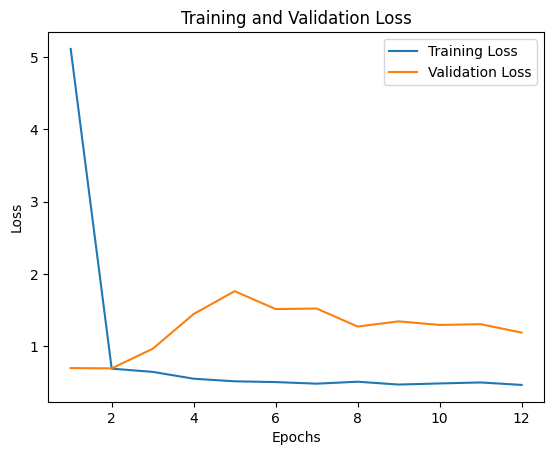

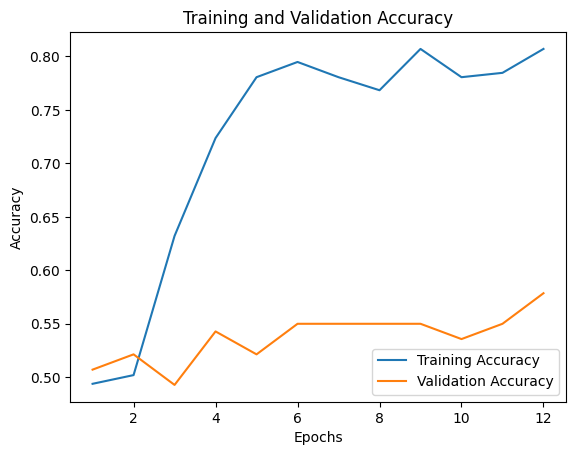

Training time : 12.53
Validation time : 6.02
Prediction Metrics
Confusion Matrix: [[37  0]
 [33  2]]
Test Accuracy: 0.54
Test f1: 0.11
Test AUC: 0.67
Time: 0.39


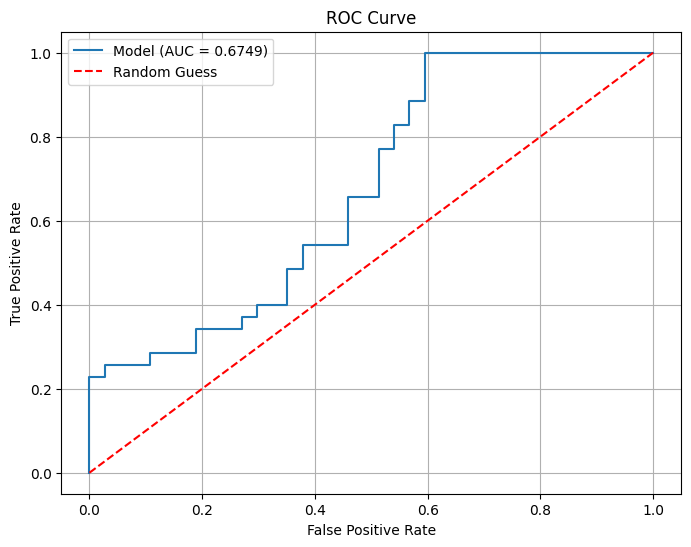

In [ ]:
class CNN(nn.Module):

  def __init__(self, n_classes = 2):
    super().__init__()

    self.layers = nn.Sequential (
        nn.Conv2d(in_channels=3, out_channels = 128, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2),
        nn.Dropout(0.2),

        nn.Conv2d(128, 256, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.1),

        nn.Flatten(),
        nn.Linear(746496, 128),
        nn.ReLU(),
        nn.Dropout(0.15),
        nn.Linear(128, 2),
    )

  def forward(self, x):
    return self.layers(x)

model = CNN()

model_graph = draw_graph(model, input_size=(1, 3, 224, 224),
                         expand_nested=True,
                         hide_inner_tensors=True,
                         hide_module_functions=True
                         )

model_graph.visual_graph

# TRAINING
# device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# optimizer
optimizer = optim.Adam(model.parameters(), lr = 0.001)

#loss function
loss_fn = nn.CrossEntropyLoss()

# save path
save_path = os.path.join(path_classification, 'ex2_run3.pt')

history = model_train_save_es(model, train_dl, val_dl,
             optimizer, loss_fn, save_path, epochs = 25, patience = 10, device = device
)

#plot
plot_results_new(history)

# total time taken for training and validation
print(f"Training time : {sum(history['Training']['Time']):.2f}")
print(f"Validation time : {sum(history['Validation']['Time']):.2f}")

# PREDICTING
predictions, probs, labels = model_predict(save_path, test_dl, device)

# EXPERIMENT 3 (Shekar Paper, 2025)

I will try to reproduce the results of this paper using this small dataset. If it fails, I will download the actual dataset and try it out

### Data Exploration

In [ ]:
## Download data

import kagglehub

# Download latest version
path_rahman = kagglehub.dataset_download("tawsifurrahman/tuberculosis-tb-chest-xray-dataset")

print("Path to dataset files:", path_rahman)

100%|██████████| 663M/663M [00:08<00:00, 84.4MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/tawsifurrahman/tuberculosis-tb-chest-xray-dataset/versions/3


In [ ]:
import os

os.listdir(path_rahman+'/TB_Chest_Radiography_Database')

['Normal.metadata.xlsx',
 'Tuberculosis',
 'README.md.txt',
 'Tuberculosis.metadata.xlsx',
 'Normal']

In [ ]:
import pandas as pd
import os

tb_meta = pd.read_excel(os.path.join(path_rahman,'TB_Chest_Radiography_Database', 'Tuberculosis.metadata.xlsx'))
normal_meta = pd.read_excel(os.path.join(path_rahman,'TB_Chest_Radiography_Database', 'Normal.metadata.xlsx'))

display (tb_meta.head())

display(normal_meta.head())

,FILE NAME,FORMAT,SIZE,URL
0,Tuberculosis-1,PNG,512*512,http://tuberculosis.by/
1,Tuberculosis-2,PNG,512*512,http://tuberculosis.by/
2,Tuberculosis-3,PNG,512*512,http://tuberculosis.by/
3,Tuberculosis-4,PNG,512*512,http://tuberculosis.by/
4,Tuberculosis-5,PNG,512*512,http://tuberculosis.by/


,FILE NAME,FORMAT,SIZE,URL
0,Normal-1,PNG,512*512,https://www.ncbi.nlm.nih.gov/pmc/articles/PMC4...
1,Normal-2,PNG,512*512,https://www.ncbi.nlm.nih.gov/pmc/articles/PMC4...
2,Normal-3,PNG,512*512,https://www.ncbi.nlm.nih.gov/pmc/articles/PMC4...
3,Normal-4,PNG,512*512,https://www.ncbi.nlm.nih.gov/pmc/articles/PMC4...
4,Normal-5,PNG,512*512,https://www.ncbi.nlm.nih.gov/pmc/articles/PMC4...


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Add label column
tb_meta['label'] = 1
normal_meta['label'] = 0

# Combine into one dataframe
all_meta = pd.concat([tb_meta, normal_meta], ignore_index=True)

# Display the count to verify
print(all_meta['label'].value_counts())
display(all_meta.head())

label
0    3500
1     700
Name: count, dtype: int64


,FILE NAME,FORMAT,SIZE,URL,label
0,Tuberculosis-1,PNG,512*512,http://tuberculosis.by/,1
1,Tuberculosis-2,PNG,512*512,http://tuberculosis.by/,1
2,Tuberculosis-3,PNG,512*512,http://tuberculosis.by/,1
3,Tuberculosis-4,PNG,512*512,http://tuberculosis.by/,1
4,Tuberculosis-5,PNG,512*512,http://tuberculosis.by/,1


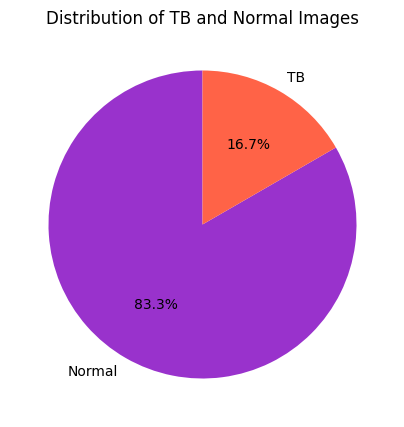

In [ ]:
# Generate pie chart
counts = all_meta['label'].value_counts()
labels = ['Normal', 'TB']

plt.figure(figsize=(5, 5))
plt.pie(counts, labels=labels, autopct='%1.1f%%', startangle=90, colors=['darkorchid', 'tomato'])
plt.title('Class Distribution for 4200 Dataset')
plt.show()

In [ ]:
tb_meta['SIZE'].unique()

array(['512*512'], dtype=object)

In [ ]:
normal_meta['SIZE'].unique()

array(['512*512'], dtype=object)

In [ ]:
normal_meta['URL'][0]

'https://www.ncbi.nlm.nih.gov/pmc/articles/PMC4256233/'

In [ ]:
normal_meta['URL'].unique()

array(['https://www.ncbi.nlm.nih.gov/pmc/articles/PMC4256233/',
       'https://www.kaggle.com/c/rsna-pneumonia-detection-challenge/data'],
      dtype=object)

In [ ]:
tb_meta['URL'].unique()

array(['http://tuberculosis.by/',
       'https://www.ncbi.nlm.nih.gov/pmc/articles/PMC4256233/'],
      dtype=object)

## 4200 DATA SETUP


# of TB images: 700
# of Normal images: 3500
Total: 4200
Train: 560 + 2800 = 3360
Validation: 70 + 350 = 420
Test: 70 + 350 = 420
Train set #: 3360
Validation set #: 420
Test set #: 420
Total: 4200
Copying images...
Successfully created Train/Val/Test Directories
Confirm the number of images is valid
train/tb: 560
train/no_tb: 2800
val/tb: 70
val/no_tb: 350
test/tb: 70
test/no_tb: 350


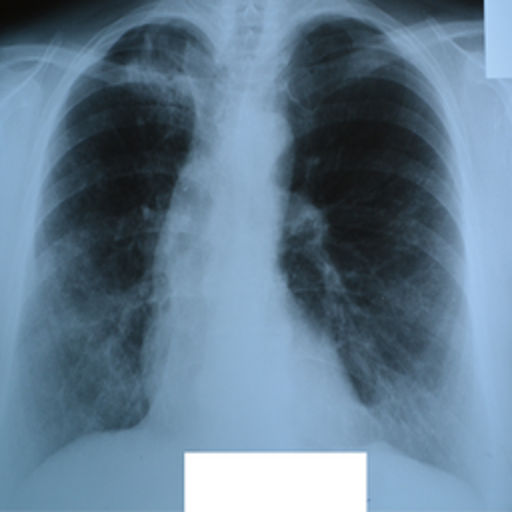

In [ ]:
import os
import pandas as pd
import PIL
import shutil

def create_images_folder_4200(path):
  '''
  This is refactored version for use in classification and not segmentation.
  '''

  tb_md = pd.read_excel(os.path.join(path,'TB_Chest_Radiography_Database', 'Tuberculosis.metadata.xlsx'))
  no_tb_md = pd.read_excel(os.path.join(path,'TB_Chest_Radiography_Database', 'Normal.metadata.xlsx'))

  # Get the ids of the images corr to TB and no-TB
  img_id1 = list(tb_md['FILE NAME'])
  img_id0 = list(no_tb_md['FILE NAME'])

  print()
  print(f'# of TB images: {len(img_id1)}')
  print(f'# of Normal images: {len(img_id0)}')
  print(f'Total: {len(img_id1) + len(img_id0)}')

  # We will split train, validation and test set using 80%, 10% and 10%.
  train_ratio = 0.8
  val_ratio = 0.1
  test_ratio = 0.1

  # Calculate counts
  train_no_1 = int(train_ratio * len(img_id1))
  train_no_0 = int(train_ratio * len(img_id0))
  print(f'Train: {train_no_1} + {train_no_0} = {train_no_1 + train_no_0}')


  val_no_1 = int(val_ratio * len(img_id1))
  val_no_0 = int(val_ratio * len(img_id0))
  print(f'Validation: {val_no_1} + {val_no_0} = {val_no_1 + val_no_0}')

  test_no_1 = int(test_ratio * len(img_id1))
  test_no_0 = int(test_ratio * len(img_id0))
  print(f'Test: {test_no_1} + {test_no_0} = {test_no_1 + test_no_0}')


  # Split the lists (Slicing)
  train_1 = img_id1[:train_no_1]
  train_0 = img_id0[:train_no_0]
  train = train_1 + train_0
  print(f'Train set #: {len(train)}')

  val_1 = img_id1[train_no_1:train_no_1 + val_no_1]
  val_0 = img_id0[train_no_0:train_no_0 + val_no_0]
  val = val_1 + val_0
  print(f'Validation set #: {len(val)}')

  test_1 = img_id1[train_no_1 + val_no_1:]
  test_0 = img_id0[train_no_0 + val_no_0:]
  test = test_1 + test_0
  print(f'Test set #: {len(test)}')

  print(f'Total: {len(train) + len(val) + len(test)}')

  ## --- REFACTOR START ---

  # 1. Update sets to create train, val, test folders
  sets = ['train', 'val', 'test']
  klases = ['tb', 'no_tb']

  current_path = os.getcwd()

  # 2. Existing loop creates the directory tree: train/tb, train/no_tb, etc.
  for s in sets:
      for klas in klases:
        target_dir = os.path.join(current_path, s, klas)
        if not os.path.exists(target_dir):
          os.makedirs(target_dir)

  path_tb_images = os.path.join(path, 'TB_Chest_Radiography_Database', 'Tuberculosis')
  path_no_tb_images = os.path.join(path, 'TB_Chest_Radiography_Database', 'Normal')

  # 3. Define tasks to map specific ID lists to their destination folder
  # Format: (List of IDs, Destination Folder, Class Name, Source Path)
  tasks = [
      (train_1, 'train', 'tb', path_tb_images),
      (val_1,   'val',   'tb', path_tb_images),
      (test_1,  'test',  'tb', path_tb_images),
      (train_0, 'train', 'no_tb', path_no_tb_images),
      (val_0,   'val',   'no_tb', path_no_tb_images),
      (test_0,  'test',  'no_tb', path_no_tb_images),
  ]

  # 4. Loop through tasks and copy images
  print("Copying images...")
  for ids, folder, klas, source_dir in tasks:
      for i in ids:
          str_i = str(i) + '.png'
          # Copy from source to current_path/folder/class/image.png
          shutil.copy(
              src=os.path.join(source_dir, str_i),
              dst=os.path.join(current_path, folder, klas, str_i)
          )

  print(f'Successfully created Train/Val/Test Directories')

  print ('Confirm the number of images is valid')
  for st in sets:
    for klas in klases:
      ls = os.listdir(os.path.join(current_path, st, klas))
      print (f'{st}/{klas}: {len(ls)}')

  ## --- REFACTOR END ---

  return img_id1, img_id0

# create
img_id1, img_id0 = create_images_folder_4200(path_rahman)

# show image
path_image = './train/tb/Tuberculosis-1.png'
PIL.Image.open(path_image)

### parameters count

In [3]:
import torch
import torch.nn as nn

class CNN(nn.Module):

  def __init__(self, n_classes = 2):
    super().__init__()

    self.layers = nn.Sequential (
        nn.Conv2d(in_channels=3, out_channels = 128, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2),
        nn.Dropout(0.3),

        nn.Conv2d(128, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.5),

        nn.Conv2d(64, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.5),

        nn.Flatten(),
        nn.Linear(43264, 16),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(16, 2),
    )

  def forward(self, x):
    return self.layers(x)

model = CNN()

# 4. Count parameters
total_params = sum(p.numel() for p in model.parameters())

print(f'Total Parameters: {total_params:,}')

Total Parameters: 806,578


### run 1 (no aug)

I have added more data for training the model. My goal is to confirm the results reported by the Shekar paper. I expect the performance will improve though not as reported by Shekar, that will be such a drastic improvement!

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torch.optim as optim


from torchvision import transforms as T
from torchvision.datasets import ImageFolder

import matplotlib.pyplot as plt

from torchview import draw_graph
# from utils import model_train_save, model_predict, plot_results_new

# TRANSFORMS

transforms = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor()
])

# TENSOR DATASETS
train_td = ImageFolder(root = './train', transform = transforms)
val_td = ImageFolder(root = './val', transform = transforms)
test_td = ImageFolder(root = './test', transform = transforms)

# print(train_td[0][0])

# TO BATCHES
train_dl = DataLoader(train_td, batch_size = 32, shuffle = True)
val_dl = DataLoader(val_td, batch_size = 32)
test_dl = DataLoader(test_td, batch_size = 32)

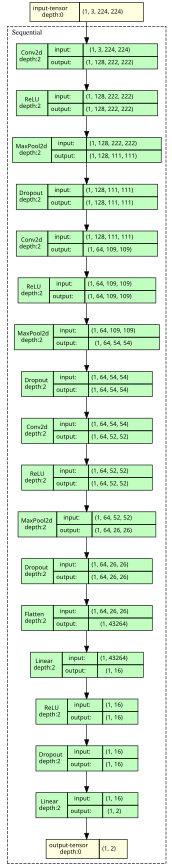

In [ ]:
class CNN(nn.Module):

  def __init__(self, n_classes = 2):
    super().__init__()

    self.layers = nn.Sequential (
        nn.Conv2d(in_channels=3, out_channels = 128, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2),
        nn.Dropout(0.3),

        nn.Conv2d(128, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.5),

        nn.Conv2d(64, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.5),

        nn.Flatten(),
        nn.Linear(43264, 16),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(16, 2),
    )

  def forward(self, x):
    return self.layers(x)

model = CNN()

model_graph = draw_graph(model, input_size=(1, 3, 224, 224),
                         expand_nested=True,
                         hide_inner_tensors=True,
                         hide_module_functions=True
                         )

model_graph.visual_graph

Epoch: [1/100]	 Train Loss: 0.31	    Val Loss: 0.34	 Train Acc: 0.83	 Val Acc: 0.83    Train Time: 0.90	 Val Time: 0.10
Epoch: [2/100]	 Train Loss: 0.25	    Val Loss: 0.30	 Train Acc: 0.83	 Val Acc: 0.83    Train Time: 0.92	 Val Time: 0.09
Epoch: [3/100]	 Train Loss: 0.22	    Val Loss: 0.25	 Train Acc: 0.88	 Val Acc: 0.95    Train Time: 0.80	 Val Time: 0.09
Epoch: [4/100]	 Train Loss: 0.19	    Val Loss: 0.26	 Train Acc: 0.94	 Val Acc: 0.96    Train Time: 0.79	 Val Time: 0.09
Epoch: [5/100]	 Train Loss: 0.18	    Val Loss: 0.20	 Train Acc: 0.95	 Val Acc: 0.97    Train Time: 0.82	 Val Time: 0.08
Epoch: [6/100]	 Train Loss: 0.18	    Val Loss: 0.18	 Train Acc: 0.96	 Val Acc: 0.96    Train Time: 0.80	 Val Time: 0.09
Epoch: [7/100]	 Train Loss: 0.16	    Val Loss: 0.21	 Train Acc: 0.96	 Val Acc: 0.94    Train Time: 0.79	 Val Time: 0.09
Epoch: [8/100]	 Train Loss: 0.14	    Val Loss: 0.18	 Train Acc: 0.96	 Val Acc: 0.95    Train Time: 0.80	 Val Time: 0.09
Epoch: [9/100]	 Train Loss: 0.13	    Val

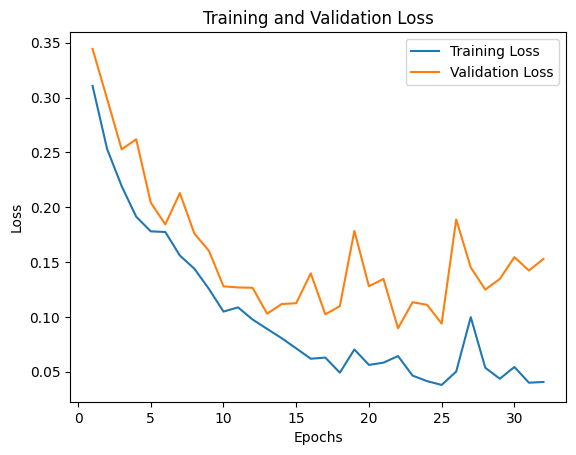

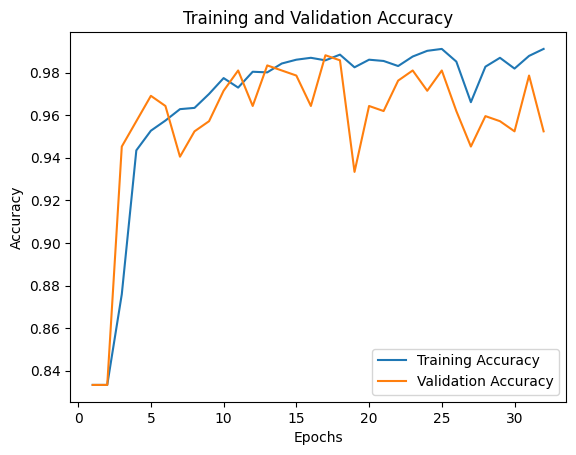

Training time : 25.72
Validation time : 2.85
Prediction Metrics
Confusion Matrix: [[342   8]
 [  2  68]]
Accuracy: 0.98
f1: 0.93
AUC: 0.99
Time: 0.08


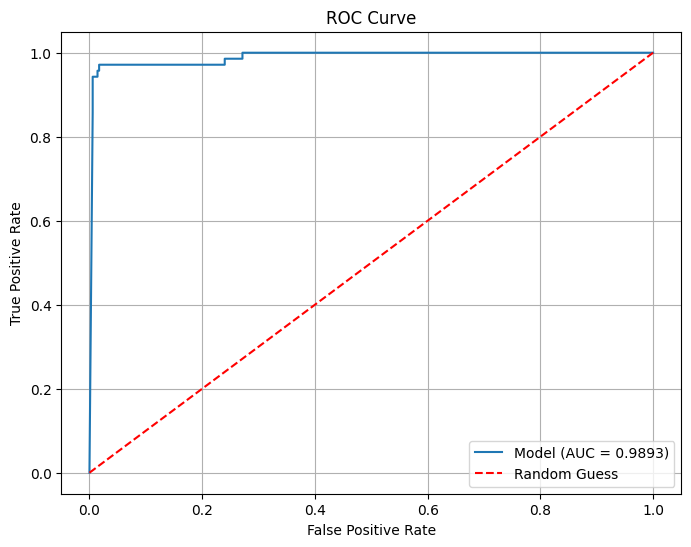

ValueError: too many values to unpack (expected 2)

In [ ]:
# device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# optimizer
optimizer = optim.Adam(model.parameters(), lr = 0.001)

#loss function
loss_fn = nn.CrossEntropyLoss()

# save path
save_path = './ex4_run1.pt'

history = model_train_save_es(model, train_dl, val_dl,
             optimizer, loss_fn, save_path, epochs = 100, patience = 10, device = device
)

#plot
plot_results_new(history)

# total time taken for training and validation
print(f"Training time : {sum(history['Training']['Time']):.2f}")
print(f"Validation time : {sum(history['Validation']['Time']):.2f}")


#predict
predictions, probs,labels = model_predict_val(save_path, val_dl, device)

Prediction Metrics
Confusion Matrix: [[342   8]
 [  2  68]]
Accuracy: 0.98
f1: 0.93
AUC: 0.99
Time: 0.10


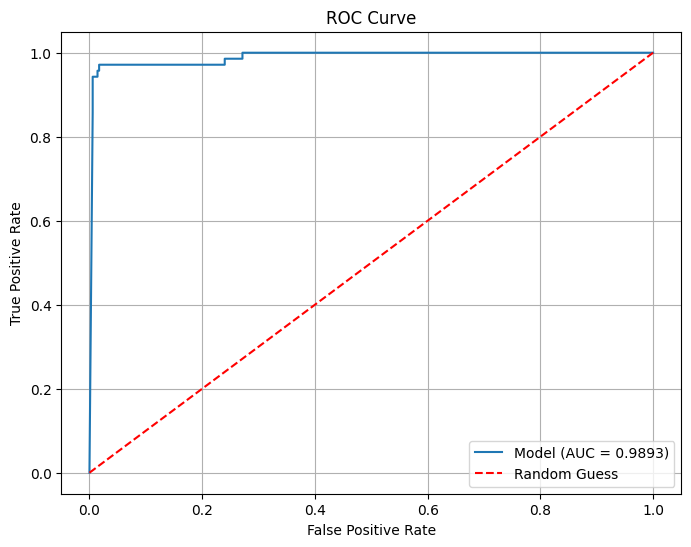

In [ ]:
predictions, probs,labels = model_predict_val(save_path, val_dl, device)

In [ ]:
PATH = '/content/drive/MyDrive/MSc Data Science/Thesis/Codes/classification/class_ex3_run1_7400.pt'

torch.save(model.state_dict(), PATH)

### load model and evaluate

Prediction Metrics
Test Accuracy: 0.9524 | f1: 0.8734 | AUC: 0.9869
Sensitivity: 0.9857 | Specificity: 0.9457
Precision: 0.7841| Test Time: 0.1641


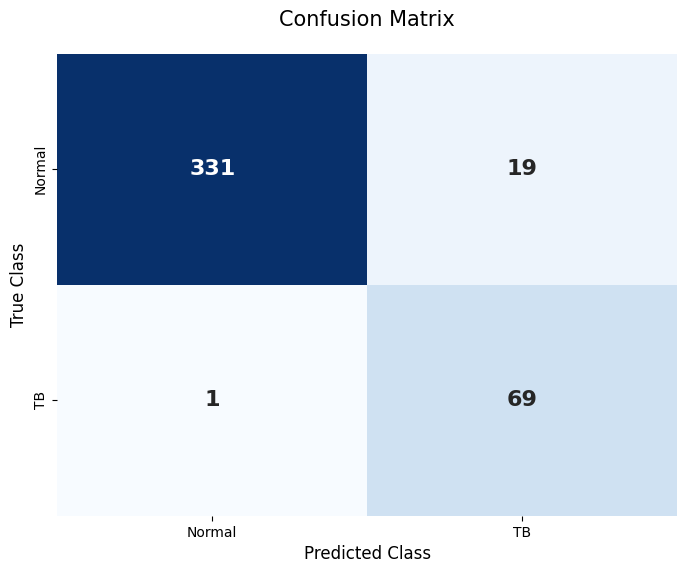

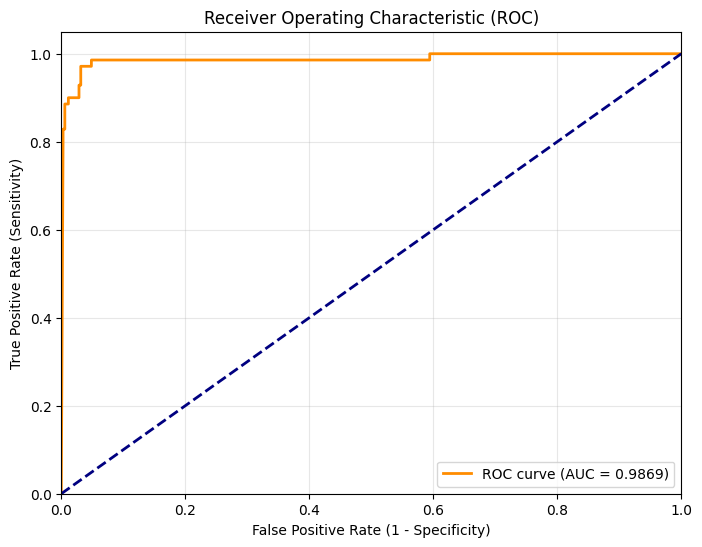

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torch.optim as optim

from torchvision import transforms as T
from torchvision.datasets import ImageFolder

import matplotlib.pyplot as plt

class CNN(nn.Module):

  def __init__(self, n_classes = 2):
    super().__init__()

    self.layers = nn.Sequential (
        nn.Conv2d(in_channels=3, out_channels = 128, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2),
        nn.Dropout(0.3),

        nn.Conv2d(128, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.5),

        nn.Conv2d(64, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.5),

        nn.Flatten(),
        nn.Linear(43264, 16),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(16, 2),
    )

  def forward(self, x):
    return self.layers(x)


# TRANSFORMS

transforms = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor()
])

# TENSOR DATASETS
test_td = ImageFolder(root = './test', transform = transforms)
test_dl = DataLoader(test_td, batch_size = 32)

PATH = '/content/drive/MyDrive/MSc Data Science/Thesis/Codes/classification/class_ex3_run1_4200.pt'

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = CNN().to(device)
state_dict = torch.load(PATH, map_location=device)
model.load_state_dict(state_dict)
model.eval()

predictions, probs, labels = model_predict_new(model, test_dl, device)

### grad-CAM

Developed with quick assistance from deep seek.

- Normalization is not implemented in the transforms.

- The model has already been loaded

Using target layer: Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
Classes: ['no_tb', 'tb']


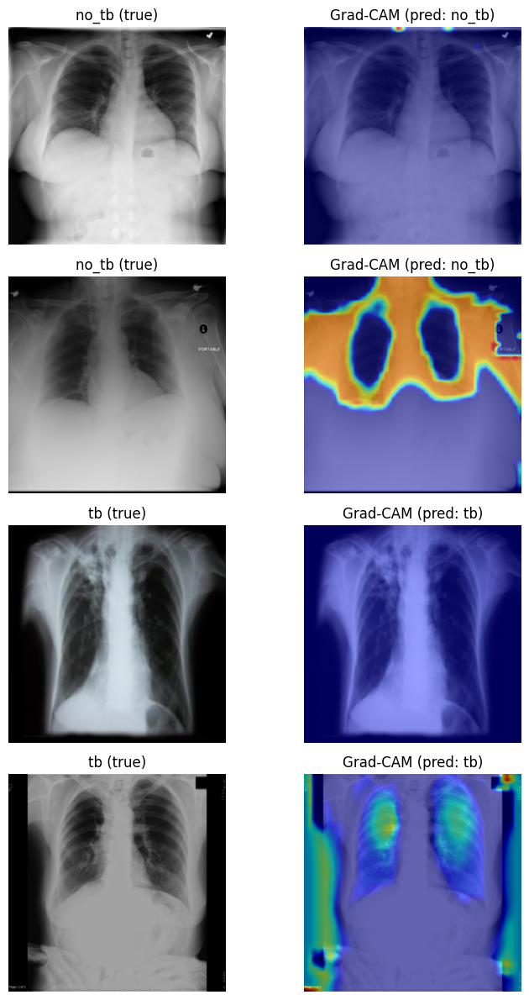

In [ ]:
import os
import random
import torch
import torch.nn as nn
from torchvision import transforms as T
from torchvision.datasets import ImageFolder
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

# Import Grad-CAM
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

# -------------------- CONFIGURATION --------------------
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model.eval()

data_dir = './test'
num_images_per_class = 2
image_size = (224, 224)

# -------------------- FIND LAST CONV LAYER --------------------
def find_last_conv_layer(model):
    last_conv = None
    for name, module in model.named_modules():
        if isinstance(module, nn.Conv2d):
            last_conv = module
    if last_conv is None:
        raise ValueError("No convolutional layer found in the model.")
    return last_conv

target_layer = find_last_conv_layer(model)
print(f"Using target layer: {target_layer}")

# -------------------- PREPARE DATA --------------------
# Use ImageFolder to get class names and paths
dataset = ImageFolder(root=data_dir, transform=None)  # no transform yet, we'll apply later
class_names = dataset.classes
print(f"Classes: {class_names}")

# Build a list of image paths per class
paths_per_class = {cls: [] for cls in class_names}
for path, label in dataset.samples:
    cls = class_names[label]
    paths_per_class[cls].append(path)

# Select the desired number of images per class
selected_images = []
for cls in class_names:
    paths = paths_per_class[cls]
    # Randomly choose num_images_per_class (or all if fewer exist)
    selected = random.sample(paths, min(num_images_per_class, len(paths)))
    selected_images.extend([(cls, p) for p in selected])

# -------------------- TRANSFORM --------------------
# Note: if you used normalization during training, include it here.
val_transforms = T.Compose([
    T.Resize(image_size),
    T.ToTensor(),
    # T.Normalize(mean=[...], std=[...])   # uncomment if needed
])

# -------------------- GRAD-CAM LOOP --------------------
cam = GradCAM(model=model, target_layers=[target_layer])

# We'll create a grid plot
fig, axes = plt.subplots(len(selected_images), 2, figsize=(8, 3*len(selected_images)))
if len(selected_images) == 1:
    axes = axes.reshape(1, -1)  # make sure axes is 2D

for i, (cls_name, img_path) in enumerate(selected_images):
    # Load and transform image
    pil_img = Image.open(img_path).convert('RGB')
    input_tensor = val_transforms(pil_img).unsqueeze(0).to(device)  # [1,3,H,W]

    # --- Determine target class ---
    # Option 1: Use the actual class index (0 or 1) if you know the mapping.
    # Here we let Grad-CAM target the predicted class (most confident).
    # Alternatively, you can set targets = [ClassifierOutputTarget(0 or 1)] manually.
    # For automatic mapping: run a forward pass to get logits, then use argmax.
    with torch.no_grad():
        logits = model(input_tensor)
        pred_class = logits.argmax(dim=1).item()
    targets = None  # None uses the predicted class (internally GradCAM will use the highest scoring category)

    # Generate Grad-CAM
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)
    grayscale_cam = grayscale_cam[0, :]  # take the first (and only) map

    # Prepare image for overlay (denormalize if needed)
    rgb_img = input_tensor.squeeze(0).permute(1, 2, 0).cpu().numpy()
    # If you normalized, you need to unnormalize here (omitted for simplicity)

    # Overlay heatmap
    cam_image = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

    # Plot
    axes[i, 0].imshow(rgb_img)
    axes[i, 0].set_title(f"{cls_name} (true)")
    axes[i, 0].axis('off')

    axes[i, 1].imshow(cam_image)
    axes[i, 1].set_title(f"Grad-CAM (pred: {class_names[pred_class]})")
    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()

### t-SNE

Also coded with the help of deep-seek

Model loaded successfully.
Classes: ['no_tb', 'tb']
Collected 420 samples, each with 16 features.
Running t‑SNE (this may take a while)...


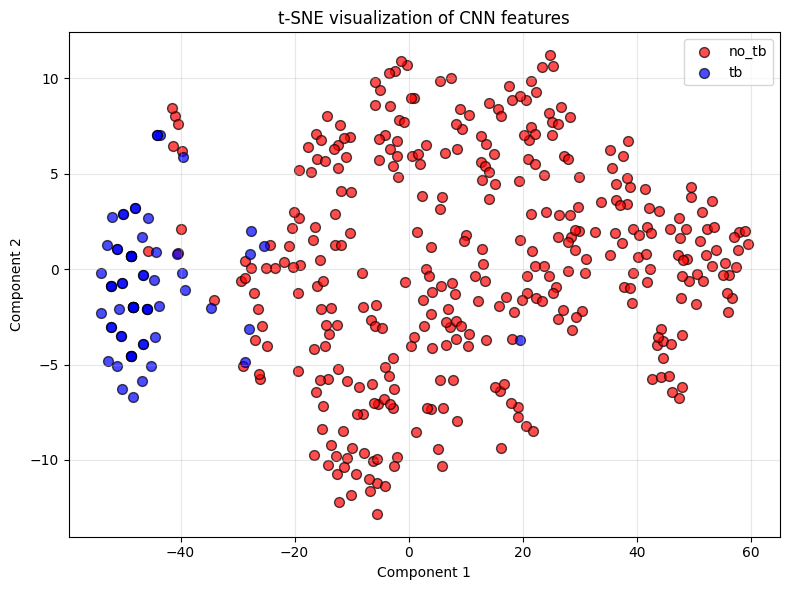

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import transforms as T
from torchvision.datasets import ImageFolder
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

# -------------------- CONFIGURATION --------------------
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model_path = '/content/drive/MyDrive/MSc Data Science/Thesis/Codes/classification/class_ex3_run1_4200.pt'

data_dir = './test'                                 # folder containing class subfolders
batch_size = 64

# -------------------- MODEL DEFINITION --------------------
class CNN(nn.Module):
    def __init__(self, n_classes=2):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(3, 128, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout(0.3),

            nn.Conv2d(128, 64, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout(0.5),

            nn.Conv2d(64, 64, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout(0.5),

            nn.Flatten(),
            nn.Linear(43264, 16),
            nn.ReLU(),               # <-- we want features after this ReLU
            nn.Dropout(0.2),
            nn.Linear(16, 2)
        )

    def forward(self, x):
        return self.layers(x)

# -------------------- LOAD MODEL WITH STATE DICT --------------------
model = CNN().to(device)
state_dict = torch.load(model_path, map_location=device)
model.load_state_dict(state_dict)
model.eval()
print("Model loaded successfully.")

# -------------------- SET UP FEATURE EXTRACTOR --------------------
# We'll register a forward hook on the ReLU layer at index 14.
# This hook will store the output of that layer whenever we run a forward pass.
features = []   # global list to collect features

def hook_fn(module, input, output):
    # output is the tensor after ReLU (shape: [batch, 16])
    features.append(output.detach().cpu())

# Find the ReLU layer (index 14) and attach the hook
target_layer = model.layers[14]   # the ReLU after the first Linear(16)
handle = target_layer.register_forward_hook(hook_fn)

# -------------------- DATA LOADING --------------------
# IMPORTANT: Use the same validation transforms you used during training.
# If you computed mean and std, include Normalize here.
val_transforms = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
])

dataset = ImageFolder(root=data_dir, transform=val_transforms)
dataloader = DataLoader(dataset, batch_size=batch_size)
class_names = dataset.classes
print(f"Classes: {class_names}")

# -------------------- COLLECT FEATURES AND LABELS --------------------
all_labels = []

with torch.no_grad():
    for images, labels in dataloader:
        images = images.to(device)
        _ = model(images)          # forward pass; hook fills the `features` list
        all_labels.extend(labels.numpy())

# Concatenate all captured features
features_tensor = torch.cat(features, dim=0)   # shape: [num_samples, 16]
feature_array = features_tensor.numpy()
label_array = np.array(all_labels)

print(f"Collected {feature_array.shape[0]} samples, each with {feature_array.shape[1]} features.")

# Remove the hook (good practice)
handle.remove()

# -------------------- t‑SNE --------------------
print("Running t‑SNE (this may take a while)...")
tsne = TSNE(n_components=2, random_state=42, perplexity=20, max_iter=1000)
features_2d = tsne.fit_transform(feature_array)

# -------------------- PLOT --------------------
plt.figure(figsize=(8, 6))
colors = ['red', 'blue']   # adjust as needed
for class_id in range(len(class_names)):
    mask = label_array == class_id
    plt.scatter(features_2d[mask, 0], features_2d[mask, 1],
                c=colors[class_id], label=class_names[class_id], alpha=0.7, edgecolors='k', s=50)
plt.title('t‑SNE visualization of CNN features')
plt.xlabel('Component 1')
plt.ylabel('Component 2')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### run 2 (transforms)


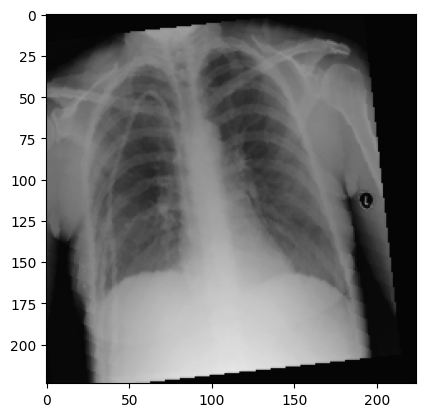

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torch.optim as optim

from torchvision import transforms as T
from torchvision.datasets import ImageFolder

import matplotlib.pyplot as plt

from torchview import draw_graph
# from utils import model_train_save, model_predict, plot_results_new

# TRANSFORMS

transforms = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor()
])

# TENSOR DATASETS
train_td = ImageFolder(root = './train', transform = T.Compose([
    T.Resize((224, 224)),
    T.RandomHorizontalFlip(p = 0.5),
    T.RandomAffine(degrees = 10, #patient is not always straight
                       translate = (0.1, 0.1), #shift it vertically and horizontally from the center
                       scale = (0.9, 1.1)), # controls the size of the lungs
    T.ColorJitter(brightness = 0.1, contrast = 0.1),
    T.ToTensor(),
])
)

val_td = ImageFolder(root = './val', transform = transforms)
test_td = ImageFolder(root = './test', transform = transforms)

# TO BATCHES
train_dl = DataLoader(train_td, batch_size = 32, shuffle = True)
val_dl = DataLoader(val_td, batch_size = 32)
test_dl = DataLoader(test_td, batch_size = 32)

plt.imshow(train_td[0][0].permute(1, 2, 0));

Epoch: [1/100]	 Train Loss: 0.34	    Val Loss: 0.36	 Train Acc: 0.86	 Val Acc: 0.87    Train Time: 0.98	 Val Time: 0.10
Epoch: [2/100]	 Train Loss: 0.24	    Val Loss: 0.26	 Train Acc: 0.92	 Val Acc: 0.93    Train Time: 1.12	 Val Time: 0.10
Epoch: [3/100]	 Train Loss: 0.23	    Val Loss: 0.24	 Train Acc: 0.91	 Val Acc: 0.95    Train Time: 0.99	 Val Time: 0.09
Epoch: [4/100]	 Train Loss: 0.20	    Val Loss: 0.25	 Train Acc: 0.93	 Val Acc: 0.95    Train Time: 0.91	 Val Time: 0.08
Epoch: [5/100]	 Train Loss: 0.20	    Val Loss: 0.26	 Train Acc: 0.93	 Val Acc: 0.95    Train Time: 0.92	 Val Time: 0.10
Epoch: [6/100]	 Train Loss: 0.22	    Val Loss: 0.25	 Train Acc: 0.93	 Val Acc: 0.95    Train Time: 0.91	 Val Time: 0.09
Epoch: [7/100]	 Train Loss: 0.20	    Val Loss: 0.24	 Train Acc: 0.93	 Val Acc: 0.94    Train Time: 0.93	 Val Time: 0.08
Epoch: [8/100]	 Train Loss: 0.19	    Val Loss: 0.26	 Train Acc: 0.94	 Val Acc: 0.95    Train Time: 0.92	 Val Time: 0.08
Epoch: [9/100]	 Train Loss: 0.20	    Val

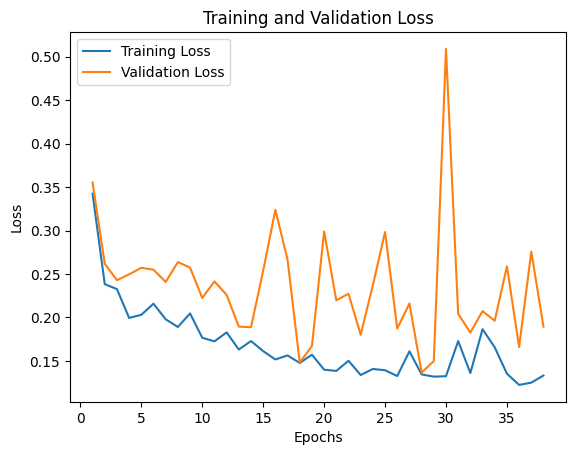

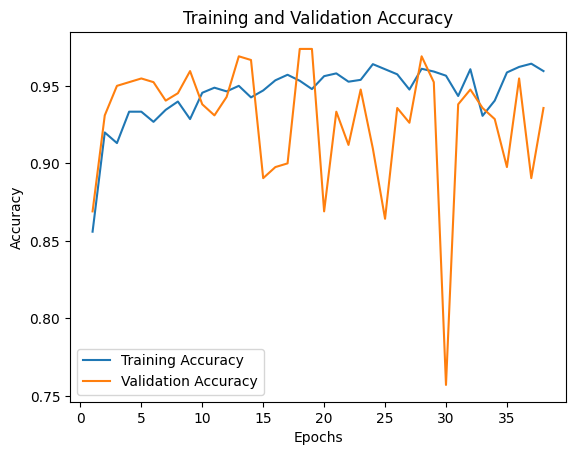

Training time : 34.89
Validation time : 3.26


In [ ]:
class CNN(nn.Module):

  def __init__(self, n_classes = 2):
    super().__init__()

    self.layers = nn.Sequential (
        nn.Conv2d(in_channels=3, out_channels = 128, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2),
        nn.Dropout(0.3),

        nn.Conv2d(128, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.5),

        nn.Conv2d(64, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.5),

        nn.Flatten(),
        nn.Linear(43264, 16),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(16, 2),
    )

  def forward(self, x):
    return self.layers(x)

model = CNN()

model_graph = draw_graph(model, input_size=(1, 3, 224, 224),
                         expand_nested=True,
                         hide_inner_tensors=True,
                         hide_module_functions=True
                         )

model_graph.visual_graph

# device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# optimizer
optimizer = optim.Adam(model.parameters(), lr = 0.001)

#loss function
loss_fn = nn.CrossEntropyLoss()

# save path
save_path = '/content/drive/MyDrive/MSc Data Science/Thesis/Codes/classification/class_ex3_run2_4200.pt'

history = model_train_save_es(model, train_dl, val_dl,
             optimizer, loss_fn, save_path, epochs = 100, patience = 10, device = device
)

#plot
plot_results_new(history)

# total time taken for training and validation
print(f"Training time : {sum(history['Training']['Time']):.2f}")
print(f"Validation time : {sum(history['Validation']['Time']):.2f}")

### load model and evaluate

Prediction Metrics
Test Accuracy: 0.9667 | f1: 0.8923 | AUC: 0.9954
Sensitivity: 0.8286 | Specificity: 0.9943
Precision: 0.9667| Test Time: 0.0826


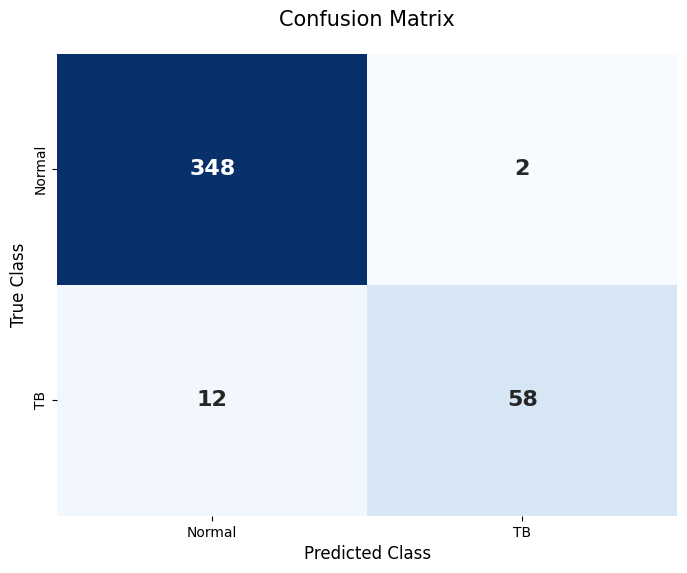

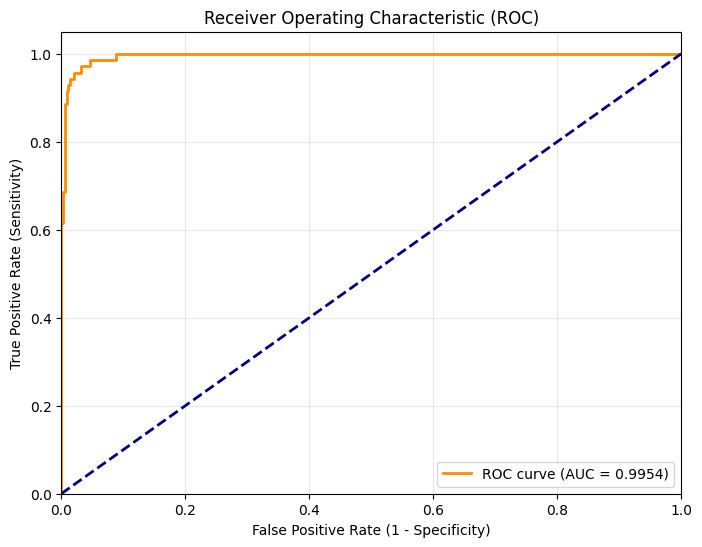

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torch.optim as optim

from torchvision import transforms as T
from torchvision.datasets import ImageFolder

import matplotlib.pyplot as plt

class CNN(nn.Module):

  def __init__(self, n_classes = 2):
    super().__init__()

    self.layers = nn.Sequential (
        nn.Conv2d(in_channels=3, out_channels = 128, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2),
        nn.Dropout(0.3),

        nn.Conv2d(128, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.5),

        nn.Conv2d(64, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.5),

        nn.Flatten(),
        nn.Linear(43264, 16),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(16, 2),
    )

  def forward(self, x):
    return self.layers(x)


# TRANSFORMS

transforms = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor()
])

# TENSOR DATASETS
test_td = ImageFolder(root = './test', transform = transforms)
test_dl = DataLoader(test_td, batch_size = 32)

PATH = '/content/drive/MyDrive/MSc Data Science/Thesis/Codes/classification/class_ex3_run2_4200.pt'

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = CNN().to(device)
state_dict = torch.load(PATH, map_location=device)
model.load_state_dict(state_dict)
model.eval()

predictions, probs, labels = model_predict_new(model, test_dl, device)

### grad-CAM

Developed with quick assistance from deep seek.

- Normalization is NOT implemented in the transforms.

- The model has already been loaded

Using target layer: Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
Classes: ['no_tb', 'tb']


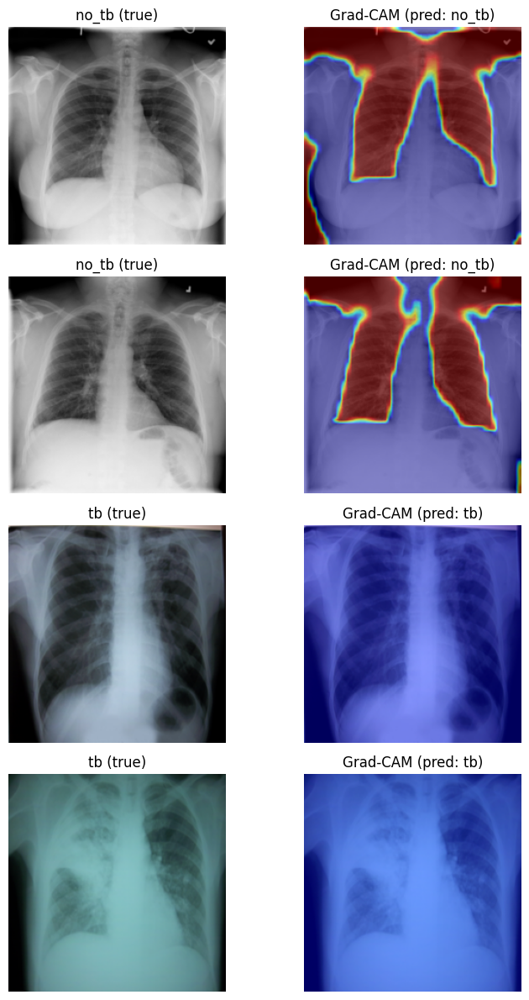

In [ ]:
import os
import random
import torch
import torch.nn as nn
from torchvision import transforms as T
from torchvision.datasets import ImageFolder
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

# Import Grad-CAM
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

# -------------------- CONFIGURATION --------------------
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model.eval()

data_dir = './test'
num_images_per_class = 2
image_size = (224, 224)

# -------------------- FIND LAST CONV LAYER --------------------
def find_last_conv_layer(model):
    last_conv = None
    for name, module in model.named_modules():
        if isinstance(module, nn.Conv2d):
            last_conv = module
    if last_conv is None:
        raise ValueError("No convolutional layer found in the model.")
    return last_conv

target_layer = find_last_conv_layer(model)
print(f"Using target layer: {target_layer}")

# -------------------- PREPARE DATA --------------------
# Use ImageFolder to get class names and paths
dataset = ImageFolder(root=data_dir, transform=None)  # no transform yet, we'll apply later
class_names = dataset.classes
print(f"Classes: {class_names}")

# Build a list of image paths per class
paths_per_class = {cls: [] for cls in class_names}
for path, label in dataset.samples:
    cls = class_names[label]
    paths_per_class[cls].append(path)

# Select the desired number of images per class
selected_images = []
for cls in class_names:
    paths = paths_per_class[cls]
    # Randomly choose num_images_per_class (or all if fewer exist)
    selected = random.sample(paths, min(num_images_per_class, len(paths)))
    selected_images.extend([(cls, p) for p in selected])

# -------------------- TRANSFORM --------------------
# Note: if you used normalization during training, include it here.
val_transforms = T.Compose([
    T.Resize(image_size),
    T.ToTensor(),
    # T.Normalize(mean=[...], std=[...])   # uncomment if needed
])

# -------------------- GRAD-CAM LOOP --------------------
cam = GradCAM(model=model, target_layers=[target_layer])

# We'll create a grid plot
fig, axes = plt.subplots(len(selected_images), 2, figsize=(8, 3*len(selected_images)))
if len(selected_images) == 1:
    axes = axes.reshape(1, -1)  # make sure axes is 2D

for i, (cls_name, img_path) in enumerate(selected_images):
    # Load and transform image
    pil_img = Image.open(img_path).convert('RGB')
    input_tensor = val_transforms(pil_img).unsqueeze(0).to(device)  # [1,3,H,W]

    # --- Determine target class ---
    # Option 1: Use the actual class index (0 or 1) if you know the mapping.
    # Here we let Grad-CAM target the predicted class (most confident).
    # Alternatively, you can set targets = [ClassifierOutputTarget(0 or 1)] manually.
    # For automatic mapping: run a forward pass to get logits, then use argmax.
    with torch.no_grad():
        logits = model(input_tensor)
        pred_class = logits.argmax(dim=1).item()
    targets = None  # None uses the predicted class (internally GradCAM will use the highest scoring category)

    # Generate Grad-CAM
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)
    grayscale_cam = grayscale_cam[0, :]  # take the first (and only) map

    # Prepare image for overlay (denormalize if needed)
    rgb_img = input_tensor.squeeze(0).permute(1, 2, 0).cpu().numpy()
    # If you normalized, you need to unnormalize here (omitted for simplicity)

    # Overlay heatmap
    cam_image = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

    # Plot
    axes[i, 0].imshow(rgb_img)
    axes[i, 0].set_title(f"{cls_name} (true)")
    axes[i, 0].axis('off')

    axes[i, 1].imshow(cam_image)
    axes[i, 1].set_title(f"Grad-CAM (pred: {class_names[pred_class]})")
    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()

Using target layer: Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
Classes: ['no_tb', 'tb']


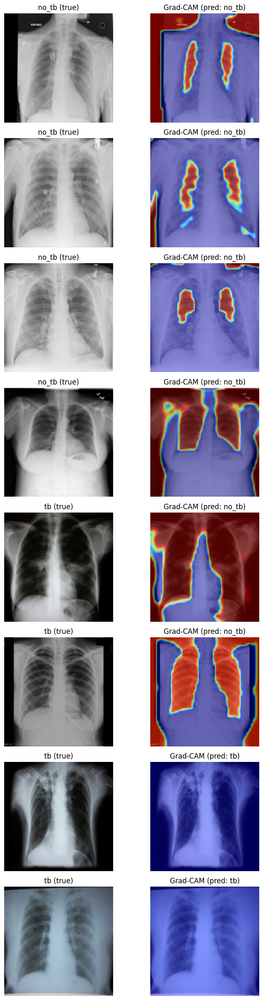

In [ ]:
import os
import random
import torch
import torch.nn as nn
from torchvision import transforms as T
from torchvision.datasets import ImageFolder
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

# Import Grad-CAM
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

# -------------------- CONFIGURATION --------------------
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model.eval()

data_dir = './test'
num_images_per_class = 4
image_size = (224, 224)

# -------------------- FIND LAST CONV LAYER --------------------
def find_last_conv_layer(model):
    last_conv = None
    for name, module in model.named_modules():
        if isinstance(module, nn.Conv2d):
            last_conv = module
    if last_conv is None:
        raise ValueError("No convolutional layer found in the model.")
    return last_conv

target_layer = find_last_conv_layer(model)
print(f"Using target layer: {target_layer}")

# -------------------- PREPARE DATA --------------------
# Use ImageFolder to get class names and paths
dataset = ImageFolder(root=data_dir, transform=None)  # no transform yet, we'll apply later
class_names = dataset.classes
print(f"Classes: {class_names}")

# Build a list of image paths per class
paths_per_class = {cls: [] for cls in class_names}
for path, label in dataset.samples:
    cls = class_names[label]
    paths_per_class[cls].append(path)

# Select the desired number of images per class
selected_images = []
for cls in class_names:
    paths = paths_per_class[cls]
    # Randomly choose num_images_per_class (or all if fewer exist)
    selected = random.sample(paths, min(num_images_per_class, len(paths)))
    selected_images.extend([(cls, p) for p in selected])

# -------------------- TRANSFORM --------------------
# Note: if you used normalization during training, include it here.
val_transforms = T.Compose([
    T.Resize(image_size),
    T.ToTensor(),
    # T.Normalize(mean=[...], std=[...])   # uncomment if needed
])

# -------------------- GRAD-CAM LOOP --------------------
cam = GradCAM(model=model, target_layers=[target_layer])

# We'll create a grid plot
fig, axes = plt.subplots(len(selected_images), 2, figsize=(8, 3*len(selected_images)))
if len(selected_images) == 1:
    axes = axes.reshape(1, -1)  # make sure axes is 2D

for i, (cls_name, img_path) in enumerate(selected_images):
    # Load and transform image
    pil_img = Image.open(img_path).convert('RGB')
    input_tensor = val_transforms(pil_img).unsqueeze(0).to(device)  # [1,3,H,W]

    # --- Determine target class ---
    # Option 1: Use the actual class index (0 or 1) if you know the mapping.
    # Here we let Grad-CAM target the predicted class (most confident).
    # Alternatively, you can set targets = [ClassifierOutputTarget(0 or 1)] manually.
    # For automatic mapping: run a forward pass to get logits, then use argmax.
    with torch.no_grad():
        logits = model(input_tensor)
        pred_class = logits.argmax(dim=1).item()
    targets = None  # None uses the predicted class (internally GradCAM will use the highest scoring category)

    # Generate Grad-CAM
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)
    grayscale_cam = grayscale_cam[0, :]  # take the first (and only) map

    # Prepare image for overlay (denormalize if needed)
    rgb_img = input_tensor.squeeze(0).permute(1, 2, 0).cpu().numpy()
    # If you normalized, you need to unnormalize here (omitted for simplicity)

    # Overlay heatmap
    cam_image = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

    # Plot
    axes[i, 0].imshow(rgb_img)
    axes[i, 0].set_title(f"{cls_name} (true)")
    axes[i, 0].axis('off')

    axes[i, 1].imshow(cam_image)
    axes[i, 1].set_title(f"Grad-CAM (pred: {class_names[pred_class]})")
    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()

### t-SNE

Also coded with the help of deep-seek

Model loaded successfully.
Classes: ['no_tb', 'tb']
Collected 420 samples, each with 16 features.
Running t‑SNE (this may take a while)...


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


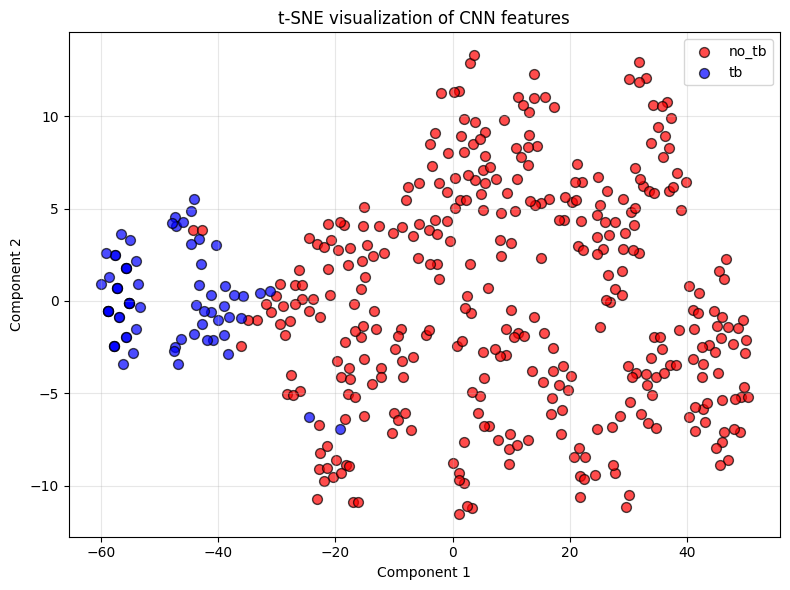

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import transforms as T
from torchvision.datasets import ImageFolder
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

# -------------------- CONFIGURATION --------------------
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model_path = '/content/drive/MyDrive/MSc Data Science/Thesis/Codes/classification/class_ex3_run2_4200.pt'

data_dir = './test'                                 # folder containing class subfolders
batch_size = 64

# -------------------- MODEL DEFINITION --------------------
class CNN(nn.Module):
    def __init__(self, n_classes=2):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(3, 128, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout(0.3),

            nn.Conv2d(128, 64, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout(0.5),

            nn.Conv2d(64, 64, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout(0.5),

            nn.Flatten(),
            nn.Linear(43264, 16),
            nn.ReLU(),               # <-- we want features after this ReLU
            nn.Dropout(0.2),
            nn.Linear(16, 2)
        )

    def forward(self, x):
        return self.layers(x)

# -------------------- LOAD MODEL WITH STATE DICT --------------------
model = CNN().to(device)
state_dict = torch.load(model_path, map_location=device)
model.load_state_dict(state_dict)
model.eval()
print("Model loaded successfully.")

# -------------------- SET UP FEATURE EXTRACTOR --------------------
# We'll register a forward hook on the ReLU layer at index 14.
# This hook will store the output of that layer whenever we run a forward pass.
features = []   # global list to collect features

def hook_fn(module, input, output):
    # output is the tensor after ReLU (shape: [batch, 16])
    features.append(output.detach().cpu())

# Find the ReLU layer (index 14) and attach the hook
target_layer = model.layers[14]   # the ReLU after the first Linear(16)
handle = target_layer.register_forward_hook(hook_fn)

# -------------------- DATA LOADING --------------------
# IMPORTANT: Use the same validation transforms you used during training.
# If you computed mean and std, include Normalize here.
val_transforms = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
])

dataset = ImageFolder(root=data_dir, transform=val_transforms)
dataloader = DataLoader(dataset, batch_size=batch_size)
class_names = dataset.classes
print(f"Classes: {class_names}")

# -------------------- COLLECT FEATURES AND LABELS --------------------
all_labels = []

with torch.no_grad():
    for images, labels in dataloader:
        images = images.to(device)
        _ = model(images)          # forward pass; hook fills the `features` list
        all_labels.extend(labels.numpy())

# Concatenate all captured features
features_tensor = torch.cat(features, dim=0)   # shape: [num_samples, 16]
feature_array = features_tensor.numpy()
label_array = np.array(all_labels)

print(f"Collected {feature_array.shape[0]} samples, each with {feature_array.shape[1]} features.")

# Remove the hook (good practice)
handle.remove()

# -------------------- t‑SNE --------------------
print("Running t‑SNE (this may take a while)...")
tsne = TSNE(n_components=2, random_state=42, perplexity=20, n_iter=1000)
features_2d = tsne.fit_transform(feature_array)

# -------------------- PLOT --------------------
plt.figure(figsize=(8, 6))
colors = ['red', 'blue']   # adjust as needed
for class_id in range(len(class_names)):
    mask = label_array == class_id
    plt.scatter(features_2d[mask, 0], features_2d[mask, 1],
                c=colors[class_id], label=class_names[class_id], alpha=0.7, edgecolors='k', s=50)
plt.title('t‑SNE visualization of CNN features')
plt.xlabel('Component 1')
plt.ylabel('Component 2')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### run 3 (normalization)

Computing mean and std from training set...
Mean: tensor([0.5030, 0.5118, 0.5146])
Std:  tensor([0.2576, 0.2577, 0.2591])


/tmp/ipykernel_3300/1217936035.py:91: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mean = torch.tensor(mean).view(3,1,1)
/tmp/ipykernel_3300/1217936035.py:92: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  std = torch.tensor(std).view(3,1,1)


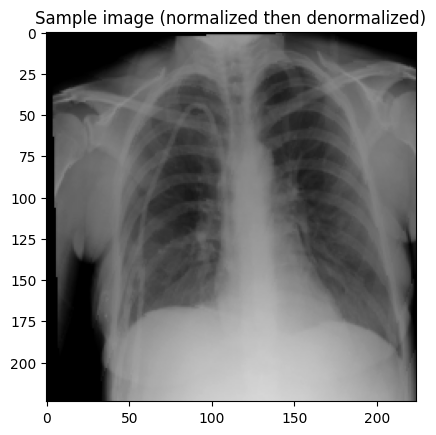

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torch.optim as optim
from torchvision import transforms as T
from torchvision.datasets import ImageFolder
import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# 1. Compute mean and std from the training set
# ------------------------------------------------------------
# We'll use a simple transform without augmentation (only resize + to tensor)
basic_transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor()
])

# Create a temporary dataset to compute statistics
temp_train_ds = ImageFolder(root='./train', transform=basic_transform)

# Function to compute mean and std
def compute_mean_std(dataset, batch_size=64, num_workers=2):
    loader = DataLoader(dataset, batch_size=batch_size, num_workers=num_workers, shuffle=False)

    mean = 0.0
    std = 0.0
    total_pixels = 0

    for images, _ in loader:
        # images shape: (batch, channels, height, width)
        batch_samples = images.size(0)
        images = images.view(batch_samples, images.size(1), -1)  # flatten spatial dims
        # accumulate mean per channel
        mean += images.mean(2).sum(0)
        total_pixels += batch_samples

    mean /= total_pixels

    # second pass for std
    for images, _ in loader:
        batch_samples = images.size(0)
        images = images.view(batch_samples, images.size(1), -1)
        var = ((images - mean.view(1, -1, 1)) ** 2).mean(2).sum(0)
        std += var

    std = torch.sqrt(std / total_pixels)

    return mean, std

print("Computing mean and std from training set...")
mean, std = compute_mean_std(temp_train_ds)
print(f"Mean: {mean}")   # e.g., tensor([0.485, 0.456, 0.406]) if RGB, but for grayscale they will be nearly identical
print(f"Std:  {std}")

# ------------------------------------------------------------
# 2. Update transforms with normalization
# ------------------------------------------------------------
# For training, we keep augmentations, then ToTensor, then Normalize
train_transform = T.Compose([
    T.Resize((224, 224)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    T.ColorJitter(brightness=0.1, contrast=0.1),
    T.ToTensor(),
    T.Normalize(mean=mean, std=std)          # <--- ADDED
])

# For validation/test, no augmentation, just resize, to tensor, normalize
val_test_transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean=mean, std=std)          # <--- ADDED
])

# ------------------------------------------------------------
# 3. Create datasets and dataloaders with new transforms
# ------------------------------------------------------------
train_td = ImageFolder(root='./train', transform=train_transform)
val_td   = ImageFolder(root='./val',   transform=val_test_transform)
test_td  = ImageFolder(root='./test',  transform=val_test_transform)

train_dl = DataLoader(train_td, batch_size=32, shuffle=True)
val_dl   = DataLoader(val_td,   batch_size=32)
test_dl  = DataLoader(test_td,  batch_size=32)

# (Optional) Visualize a normalized image – you may need to denormalize for display
def denormalize(tensor, mean, std):
    # tensor: (C, H, W) in [0,1] range after normalization? Actually after norm it's around 0.
    # We'll reverse the normalization for display.
    mean = torch.tensor(mean).view(3,1,1)
    std = torch.tensor(std).view(3,1,1)
    tensor = tensor * std + mean
    return tensor.clamp(0, 1)

sample_img, label = train_td[0]
# Denormalize for plotting
img_to_plot = denormalize(sample_img, mean, std).permute(1,2,0).numpy()
plt.imshow(img_to_plot)
plt.title(f"Sample image (normalized then denormalized)")
plt.show()

Epoch: [1/100]	 Train Loss: 0.32	    Val Loss: 0.27	 Train Acc: 0.86	 Val Acc: 0.94    Train Time: 0.98	 Val Time: 0.10
Epoch: [2/100]	 Train Loss: 0.23	    Val Loss: 0.25	 Train Acc: 0.92	 Val Acc: 0.95    Train Time: 1.01	 Val Time: 0.08
Epoch: [3/100]	 Train Loss: 0.21	    Val Loss: 0.24	 Train Acc: 0.93	 Val Acc: 0.97    Train Time: 1.13	 Val Time: 0.09
Epoch: [4/100]	 Train Loss: 0.20	    Val Loss: 0.26	 Train Acc: 0.94	 Val Acc: 0.96    Train Time: 1.09	 Val Time: 0.14
Epoch: [5/100]	 Train Loss: 0.20	    Val Loss: 0.25	 Train Acc: 0.93	 Val Acc: 0.94    Train Time: 1.10	 Val Time: 0.16
Epoch: [6/100]	 Train Loss: 0.20	    Val Loss: 0.19	 Train Acc: 0.94	 Val Acc: 0.97    Train Time: 1.00	 Val Time: 0.10
Epoch: [7/100]	 Train Loss: 0.19	    Val Loss: 0.21	 Train Acc: 0.95	 Val Acc: 0.96    Train Time: 0.91	 Val Time: 0.08
Epoch: [8/100]	 Train Loss: 0.19	    Val Loss: 0.19	 Train Acc: 0.94	 Val Acc: 0.97    Train Time: 0.92	 Val Time: 0.08
Epoch: [9/100]	 Train Loss: 0.17	    Val

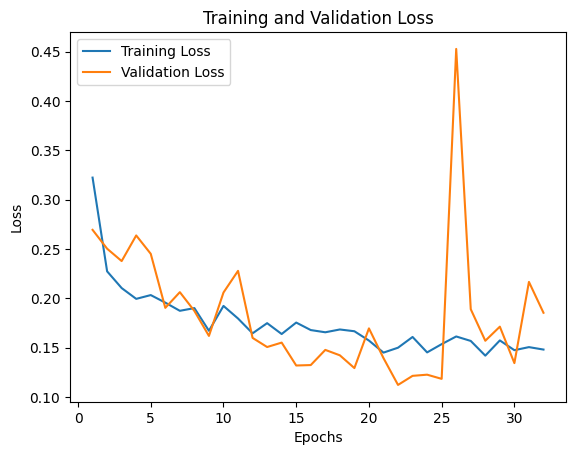

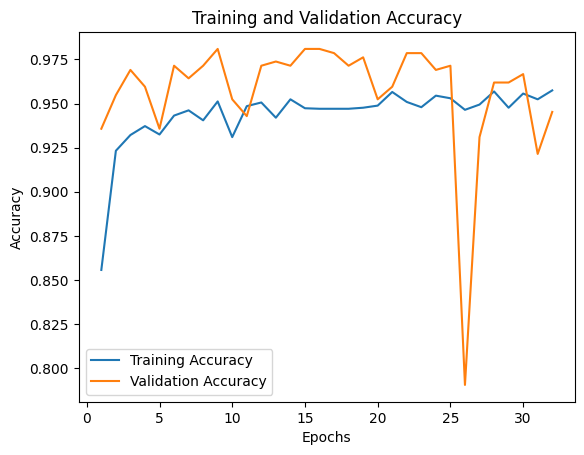

Training time : 30.49
Validation time : 3.05


In [ ]:
from torchview import draw_graph

class CNN(nn.Module):

  def __init__(self, n_classes = 2):
    super().__init__()

    self.layers = nn.Sequential (
        nn.Conv2d(in_channels=3, out_channels = 128, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2),
        nn.Dropout(0.3),

        nn.Conv2d(128, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.5),

        nn.Conv2d(64, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.5),

        nn.Flatten(),
        nn.Linear(43264, 16),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(16, 2),
    )

  def forward(self, x):
    return self.layers(x)

model = CNN()

model_graph = draw_graph(model, input_size=(1, 3, 224, 224),
                         expand_nested=True,
                         hide_inner_tensors=True,
                         hide_module_functions=True
                         )

model_graph.visual_graph

# device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# optimizer
optimizer = optim.Adam(model.parameters(), lr = 0.001)

#loss function
loss_fn = nn.CrossEntropyLoss()

# save path
save_path = '/content/drive/MyDrive/MSc Data Science/Thesis/Codes/classification/class_ex3_run3_4200.pt'

history = model_train_save_es(model, train_dl, val_dl,
             optimizer, loss_fn, save_path, epochs = 100, patience = 10, device = device
)

#plot
plot_results_new(history)

# total time taken for training and validation
print(f"Training time : {sum(history['Training']['Time']):.2f}")
print(f"Validation time : {sum(history['Validation']['Time']):.2f}")

### Load Model and Predict

Prediction Metrics
Test Accuracy: 0.96 | f1: 0.86 | AUC: 1.00
Sensitivity: 0.76 | Specificity: 1.00 | Precision: 1.00


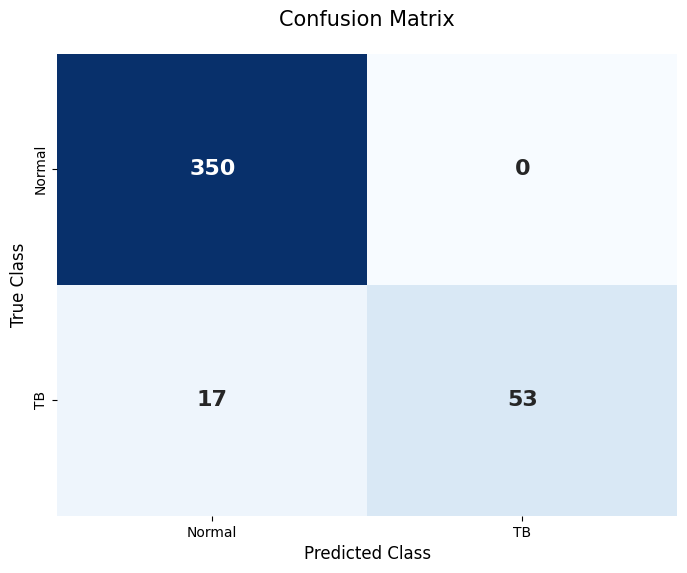

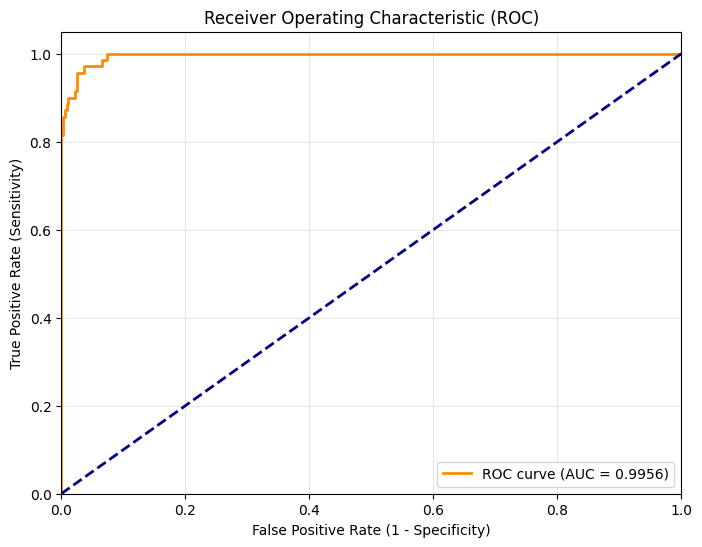

In [ ]:
class CNN(nn.Module):

  def __init__(self, n_classes = 2):
    super().__init__()

    self.layers = nn.Sequential (
        nn.Conv2d(in_channels=3, out_channels = 128, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2),
        nn.Dropout(0.3),

        nn.Conv2d(128, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.5),

        nn.Conv2d(64, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.5),

        nn.Flatten(),
        nn.Linear(43264, 16),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(16, 2),
    )

  def forward(self, x):
    return self.layers(x)

PATH = '/content/drive/MyDrive/MSc Data Science/Thesis/Codes/classification/class_ex3_run3_4200.pt'

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = CNN().to(device)
state_dict = torch.load(PATH, map_location=device)
model.load_state_dict(state_dict)
model.eval()

predictions, probs, labels = model_predict_new(model, test_dl, device)

### grad-CAM

Developed with quick assistance from deep seek.

- Normalization and denormalization is implemented

Using target layer: Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
Classes: ['no_tb', 'tb']


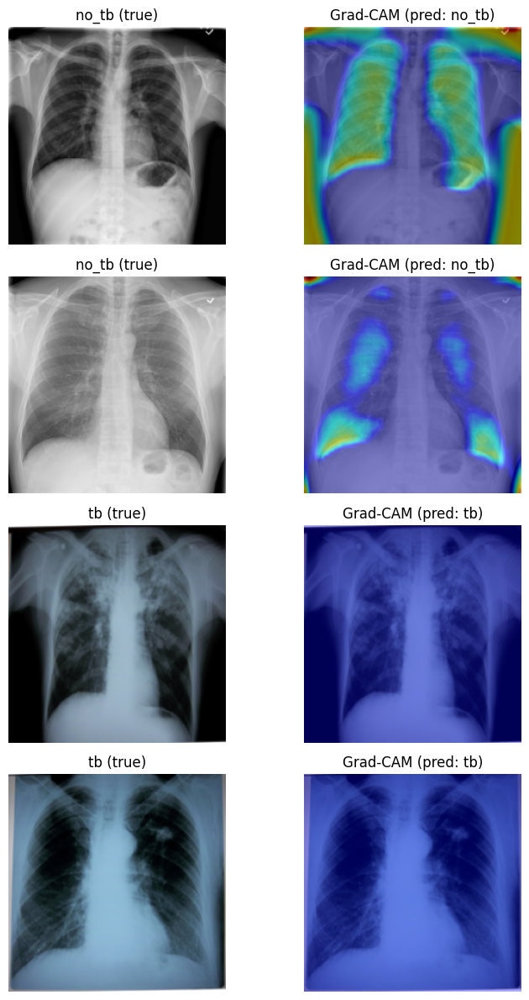

In [ ]:
import os
import random
import torch
import torch.nn as nn
from torchvision import transforms as T
from torchvision.datasets import ImageFolder
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

# -------------------- CONFIGURATION --------------------
class CNN(nn.Module):
    def __init__(self, n_classes=2):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(3, 128, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout(0.3),

            nn.Conv2d(128, 64, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout(0.5),

            nn.Conv2d(64, 64, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout(0.5),

            nn.Flatten(),
            nn.Linear(43264, 16),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(16, 2),
        )

    def forward(self, x):
        return self.layers(x)

PATH = '/content/drive/MyDrive/MSc Data Science/Thesis/Codes/classification/class_ex3_run3_4200.pt'

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = CNN().to(device)
state_dict = torch.load(PATH, map_location=device)
model.load_state_dict(state_dict)
model.eval()

data_dir = './test'
num_images_per_class = 2
image_size = (224, 224)

# -------------------- NORMALIZATION PARAMETERS --------------------
mean = [0.5030, 0.5118, 0.5146]
std  = [0.2576, 0.2577, 0.2591]

# -------------------- FIND LAST CONV LAYER --------------------
def find_last_conv_layer(model):
    last_conv = None
    for name, module in model.named_modules():
        if isinstance(module, nn.Conv2d):
            last_conv = module
    if last_conv is None:
        raise ValueError("No convolutional layer found in the model.")
    return last_conv

target_layer = find_last_conv_layer(model)
print(f"Using target layer: {target_layer}")

# -------------------- PREPARE DATA --------------------
dataset = ImageFolder(root=data_dir, transform=None)
class_names = dataset.classes
print(f"Classes: {class_names}")

paths_per_class = {cls: [] for cls in class_names}
for path, label in dataset.samples:
    cls = class_names[label]
    paths_per_class[cls].append(path)

selected_images = []
for cls in class_names:
    paths = paths_per_class[cls]
    selected = random.sample(paths, min(num_images_per_class, len(paths)))
    selected_images.extend([(cls, p) for p in selected])

# -------------------- TRANSFORM (WITH NORMALIZATION) --------------------
val_transforms = T.Compose([
    T.Resize(image_size),
    T.ToTensor(),
    T.Normalize(mean=mean, std=std)      # <--- normalization added
])

# -------------------- GRAD-CAM LOOP --------------------
cam = GradCAM(model=model, target_layers=[target_layer])

fig, axes = plt.subplots(len(selected_images), 2, figsize=(8, 3*len(selected_images)))
if len(selected_images) == 1:
    axes = axes.reshape(1, -1)

for i, (cls_name, img_path) in enumerate(selected_images):
    pil_img = Image.open(img_path).convert('RGB')
    input_tensor = val_transforms(pil_img).unsqueeze(0).to(device)

    # Get prediction
    with torch.no_grad():
        logits = model(input_tensor)
        pred_class = logits.argmax(dim=1).item()
    targets = None   # uses predicted class

    # Generate Grad-CAM
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)
    grayscale_cam = grayscale_cam[0, :]

    # --- Denormalize the image for display ---
    # Convert to numpy and undo normalization: img_denorm = img * std + mean
    img_tensor = input_tensor.squeeze(0).cpu()          # (C, H, W)
    mean_tensor = torch.tensor(mean).view(3,1,1)
    std_tensor = torch.tensor(std).view(3,1,1)
    img_denorm = img_tensor * std_tensor + mean_tensor
    img_denorm = img_denorm.clamp(0, 1)                 # ensure [0,1]
    rgb_img = img_denorm.permute(1, 2, 0).numpy()

    # Overlay heatmap
    cam_image = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

    # Plot
    axes[i, 0].imshow(rgb_img)
    axes[i, 0].set_title(f"{cls_name} (true)")
    axes[i, 0].axis('off')

    axes[i, 1].imshow(cam_image)
    axes[i, 1].set_title(f"Grad-CAM (pred: {class_names[pred_class]})")
    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()

### run 4 (oversampling)

Labels distribution after sampler
(tensor([0, 1]), tensor([18, 14]))
(tensor([0, 1]), tensor([19, 13]))
(tensor([0, 1]), tensor([16, 16]))
(tensor([0, 1]), tensor([16, 16]))
(tensor([0, 1]), tensor([14, 18]))


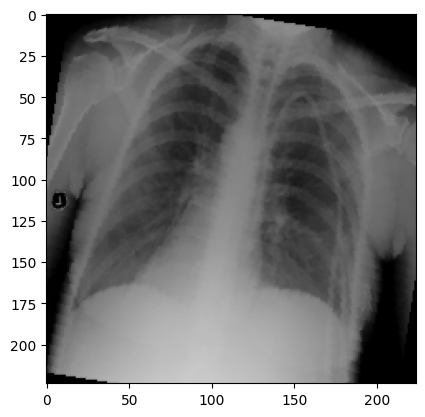

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torch.utils.data import WeightedRandomSampler

import torch.optim as optim

from torchvision import transforms as T
from torchvision.datasets import ImageFolder

import matplotlib.pyplot as plt
import numpy as np

# from torchview import draw_graph
# from utils import model_train_save, model_predict, plot_results_new

# TRANSFORMS

transforms = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor()
])

# TENSOR DATASETS
train_td = ImageFolder(root = './train', transform = T.Compose([
    T.Resize((224, 224)),
    T.RandomHorizontalFlip(p = 0.5),
    T.RandomAffine(degrees = 10, #patient is not always straight
                       translate = (0.1, 0.1), #shift it vertically and horizontally from the center
                       scale = (0.9, 1.1)), # controls the size of the lungs
    T.ColorJitter(brightness = 0.1, contrast = 0.1),
    T.ToTensor(),
])
)

val_td = ImageFolder(root = './val', transform = transforms)
test_td = ImageFolder(root = './test', transform = transforms)

# Get all labels from the training dataset
train_labels = [label for _, label in train_td.samples]

# Compute class weights (inverse frequency)
class_counts = np.bincount(train_labels)          # e.g. [3500, 700]
class_weights = 1.0 / class_counts                 # e.g. [0.0002857, 0.0014286]

# Assign weight to each sample based on its class
sample_weights = [class_weights[label] for label in train_labels]

# Create sampler – replacement=True enables oversampling of minority class
sampler = WeightedRandomSampler(weights=sample_weights,
                                num_samples=len(sample_weights),
                                replacement=True)

# TO BATCHES
train_dl = DataLoader(train_td, batch_size = 32, sampler = sampler)
val_dl = DataLoader(val_td, batch_size = 32)
test_dl = DataLoader(test_td, batch_size = 32)

# sanity check for weighted sampler in data loader

print ('Labels distribution after sampler')
i = 0
for batch, labels in train_dl:
  if i < 5:
    print(labels.unique(return_counts=True))
    i += 1

plt.imshow(train_td[0][0].permute(1, 2, 0));

Epoch: [1/100]	 Train Loss: 0.44	    Val Loss: 0.28	 Train Acc: 0.79	 Val Acc: 0.94    Train Time: 0.92	 Val Time: 0.08
Epoch: [2/100]	 Train Loss: 0.29	    Val Loss: 0.21	 Train Acc: 0.89	 Val Acc: 0.94    Train Time: 0.96	 Val Time: 0.08
Epoch: [3/100]	 Train Loss: 0.31	    Val Loss: 0.24	 Train Acc: 0.88	 Val Acc: 0.92    Train Time: 0.90	 Val Time: 0.08
Epoch: [4/100]	 Train Loss: 0.25	    Val Loss: 0.37	 Train Acc: 0.92	 Val Acc: 0.83    Train Time: 0.92	 Val Time: 0.09
Epoch: [5/100]	 Train Loss: 0.26	    Val Loss: 0.24	 Train Acc: 0.90	 Val Acc: 0.90    Train Time: 0.98	 Val Time: 0.08
Epoch: [6/100]	 Train Loss: 0.26	    Val Loss: 0.17	 Train Acc: 0.91	 Val Acc: 0.93    Train Time: 0.90	 Val Time: 0.08
Epoch: [7/100]	 Train Loss: 0.23	    Val Loss: 0.16	 Train Acc: 0.93	 Val Acc: 0.95    Train Time: 0.91	 Val Time: 0.08
Epoch: [8/100]	 Train Loss: 0.23	    Val Loss: 0.15	 Train Acc: 0.92	 Val Acc: 0.96    Train Time: 0.90	 Val Time: 0.10
Epoch: [9/100]	 Train Loss: 0.23	    Val

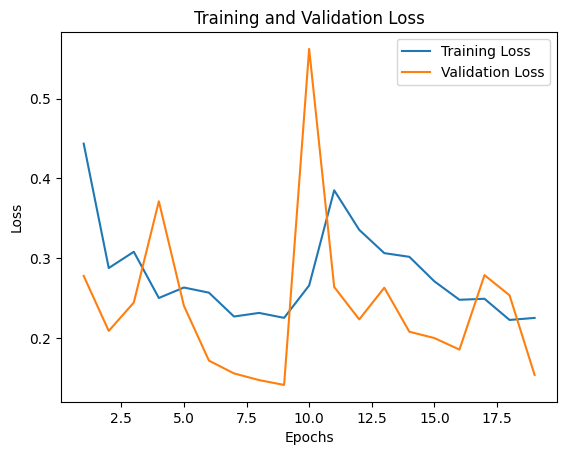

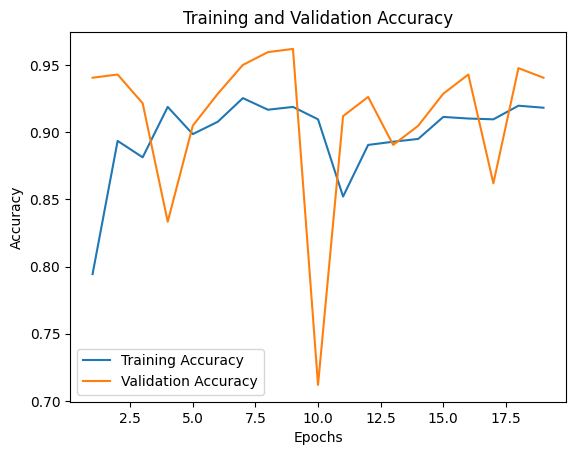

Training time : 17.92
Validation time : 1.82


In [ ]:
class CNN(nn.Module):

  def __init__(self, n_classes = 2):
    super().__init__()

    self.layers = nn.Sequential (
        nn.Conv2d(in_channels=3, out_channels = 128, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2),
        nn.Dropout(0.3),

        nn.Conv2d(128, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.5),

        nn.Conv2d(64, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.5),

        nn.Flatten(),
        nn.Linear(43264, 16),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(16, 2),
    )

  def forward(self, x):
    return self.layers(x)

model = CNN()

# model_graph = draw_graph(model, input_size=(1, 3, 224, 224),
#                          expand_nested=True,
#                          hide_inner_tensors=True,
#                          hide_module_functions=True
#                          )

# model_graph.visual_graph

# device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# optimizer
optimizer = optim.Adam(model.parameters(), lr = 0.001)

#loss function
loss_fn = nn.CrossEntropyLoss()

# save path
save_path = '/content/drive/MyDrive/MSc Data Science/Thesis/Codes/classification/class_ex3_run4_4200.pt'

history = model_train_save_es(model, train_dl, val_dl,
             optimizer, loss_fn, save_path, epochs = 100, patience = 10, device = device
)

#plot
plot_results_new(history)

# total time taken for training and validation
print(f"Training time : {sum(history['Training']['Time']):.2f}")
print(f"Validation time : {sum(history['Validation']['Time']):.2f}")

### Load Model and Predict

Prediction Metrics
Test Accuracy: 0.9833 | f1: 0.9496 | AUC: 0.9964
Sensitivity: 0.9429 | Specificity: 0.9914
Precision: 0.9565| Test Time: 0.0836


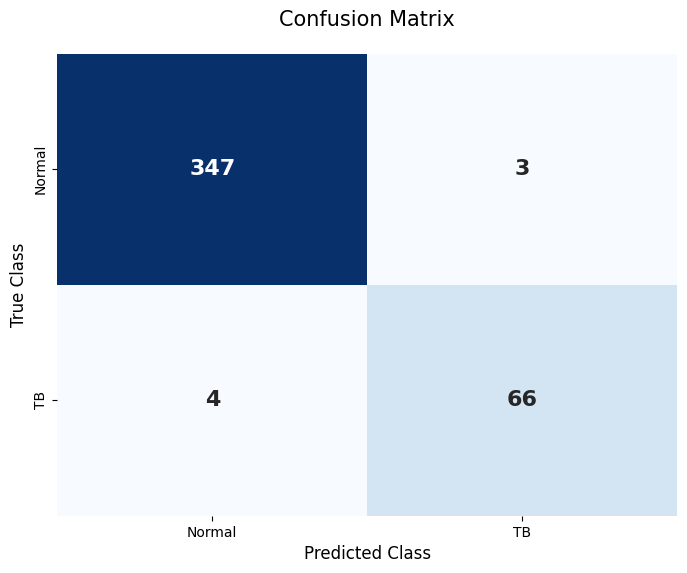

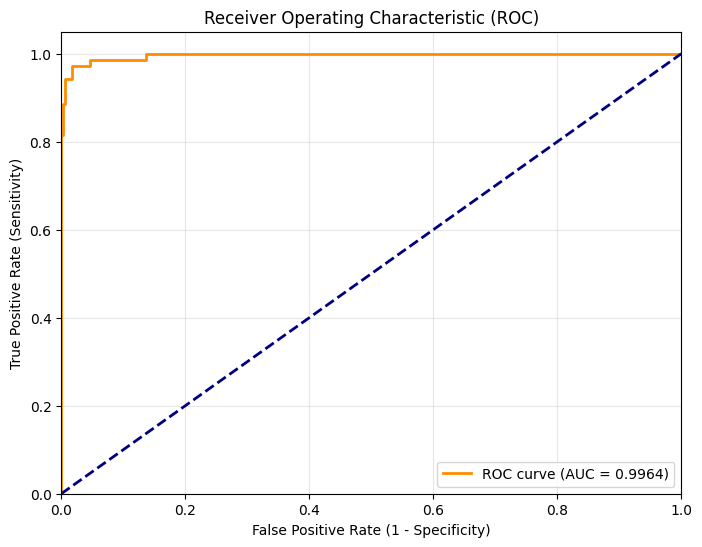

In [ ]:
class CNN(nn.Module):

  def __init__(self, n_classes = 2):
    super().__init__()

    self.layers = nn.Sequential (
        nn.Conv2d(in_channels=3, out_channels = 128, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2),
        nn.Dropout(0.3),

        nn.Conv2d(128, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.5),

        nn.Conv2d(64, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.5),

        nn.Flatten(),
        nn.Linear(43264, 16),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(16, 2),
    )

  def forward(self, x):
    return self.layers(x)

PATH = '/content/drive/MyDrive/MSc Data Science/Thesis/Codes/classification/class_ex3_run4_4200.pt'

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = CNN().to(device)
state_dict = torch.load(PATH, map_location=device)
model.load_state_dict(state_dict)
model.eval()

predictions, probs, labels = model_predict_new(model, test_dl, device)

### Load Model and Predict (704)

Prediction Metrics
Test Accuracy: 0.5528 | f1: 0.2617 | AUC: 0.6807
Sensitivity: 0.1618 | Specificity: 0.9283
Precision: 0.6842| Test Time: 1.1160


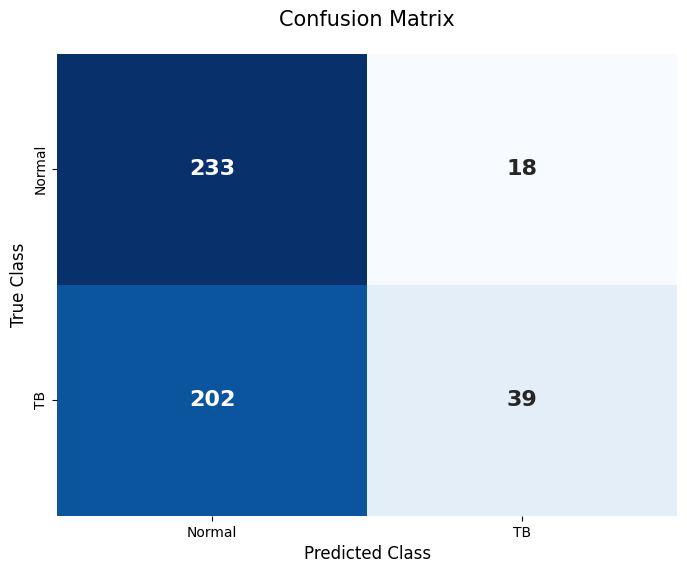

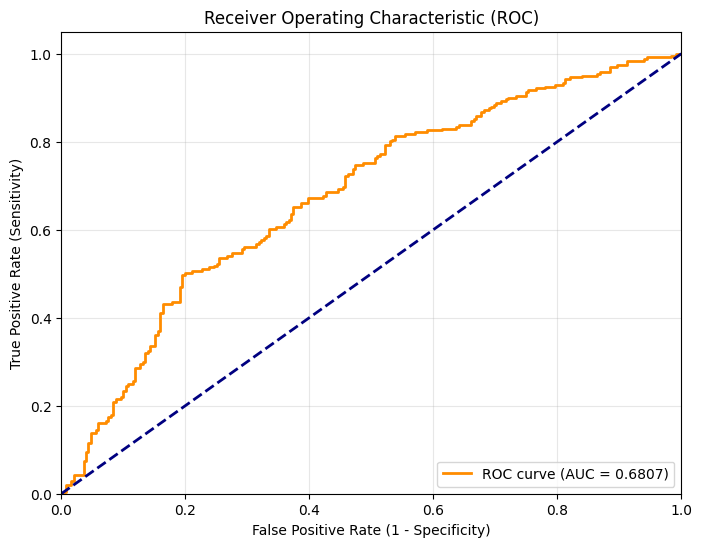

In [6]:
import os
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

from torchvision import transforms as T
from torchvision.datasets import ImageFolder

class CNN(nn.Module):

  def __init__(self, n_classes = 2):
    super().__init__()

    self.layers = nn.Sequential (
        nn.Conv2d(in_channels=3, out_channels = 128, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2),
        nn.Dropout(0.3),

        nn.Conv2d(128, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.5),

        nn.Conv2d(64, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.5),

        nn.Flatten(),
        nn.Linear(43264, 16),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(16, 2),
    )

  def forward(self, x):
    return self.layers(x)

transforms = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor()
])

# use train set from 704 as test set
test_td = ImageFolder(root = './train', transform = transforms)
test_dl = DataLoader(test_td, batch_size = 32)

PATH = '/content/drive/MyDrive/MSc Data Science/Thesis/Codes/classification/class_ex3_run4_4200.pt'

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = CNN().to(device)
state_dict = torch.load(PATH, map_location=device)
model.load_state_dict(state_dict)
model.eval()

predictions, probs, labels = model_predict_new(model, test_dl, device)

## 704 DATA

### run 0 (no aug)

Shekar Architecture

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torch.optim as optim
from torchvision import transforms as T
from torchvision.datasets import ImageFolder
import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# 1. Compute mean and std from the training set
# ------------------------------------------------------------
# We'll use a simple transform without augmentation (only resize + to tensor)
basic_transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor()
])

# Create a temporary dataset to compute statistics
temp_train_ds = ImageFolder(root='./train', transform=basic_transform)

# Function to compute mean and std
def compute_mean_std(dataset, batch_size=64, num_workers=2):
    loader = DataLoader(dataset, batch_size=batch_size, num_workers=num_workers, shuffle=False)

    mean = 0.0
    std = 0.0
    total_pixels = 0

    for images, _ in loader:
        # images shape: (batch, channels, height, width)
        batch_samples = images.size(0)
        images = images.view(batch_samples, images.size(1), -1)  # flatten spatial dims
        # accumulate mean per channel
        mean += images.mean(2).sum(0)
        total_pixels += batch_samples

    mean /= total_pixels

    # second pass for std
    for images, _ in loader:
        batch_samples = images.size(0)
        images = images.view(batch_samples, images.size(1), -1)
        var = ((images - mean.view(1, -1, 1)) ** 2).mean(2).sum(0)
        std += var

    std = torch.sqrt(std / total_pixels)

    return mean, std

print("Computing mean and std from training set...")
mean, std = compute_mean_std(temp_train_ds)
print(f"Mean: {mean}")   # e.g., tensor([0.485, 0.456, 0.406]) if RGB, but for grayscale they will be nearly identical
print(f"Std:  {std}")

# ------------------------------------------------------------
# 2. Update transforms with normalization
# ------------------------------------------------------------
# For training, we keep augmentations, then ToTensor, then Normalize
train_transform = T.Compose([
    T.Resize((224, 224)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    T.ColorJitter(brightness=0.1, contrast=0.1),
    T.ToTensor(),
    T.Normalize(mean=mean, std=std)          # <--- ADDED
])

# For validation/test, no augmentation, just resize, to tensor, normalize
val_test_transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean=mean, std=std)          # <--- ADDED
])

# ------------------------------------------------------------
# 3. Create datasets and dataloaders with new transforms
# ------------------------------------------------------------
train_td = ImageFolder(root='./train', transform=train_transform)
val_td   = ImageFolder(root='./val',   transform=val_test_transform)
test_td  = ImageFolder(root='./test',  transform=val_test_transform)

train_dl = DataLoader(train_td, batch_size=32, shuffle=True)
val_dl   = DataLoader(val_td,   batch_size=32)
test_dl  = DataLoader(test_td,  batch_size=32)

# (Optional) Visualize a normalized image – you may need to denormalize for display
def denormalize(tensor, mean, std):
    # tensor: (C, H, W) in [0,1] range after normalization? Actually after norm it's around 0.
    # We'll reverse the normalization for display.
    mean = torch.tensor(mean).view(3,1,1)
    std = torch.tensor(std).view(3,1,1)
    tensor = tensor * std + mean
    return tensor.clamp(0, 1)

sample_img, label = train_td[0]
# Denormalize for plotting
img_to_plot = denormalize(sample_img, mean, std).permute(1,2,0).numpy()
plt.imshow(img_to_plot)
plt.title(f"Sample image (normalized then denormalized)")
plt.show()

Computing mean and std from training set...
Mean: tensor([0.6146, 0.6146, 0.6146])
Std:  tensor([0.2556, 0.2556, 0.2556])


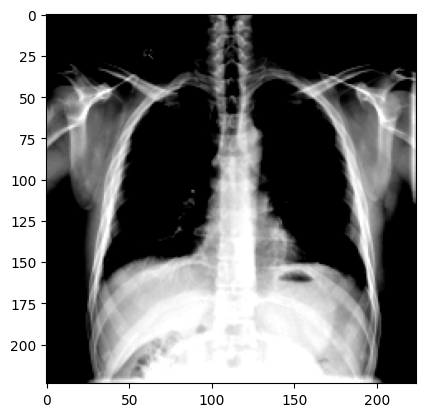

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torch.optim as optim

from torchvision import transforms as T
from torchvision.datasets import ImageFolder

import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# 1. Compute mean and std from the training set
# ------------------------------------------------------------
# We'll use a simple transform without augmentation (only resize + to tensor)
basic_transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor()
])

# Create a temporary dataset to compute statistics
temp_train_ds = ImageFolder(root='./train', transform=basic_transform)

# Function to compute mean and std
def compute_mean_std(dataset, batch_size=64, num_workers=2):
    loader = DataLoader(dataset, batch_size=batch_size, num_workers=num_workers, shuffle=False)

    mean = 0.0
    std = 0.0
    total_pixels = 0

    for images, _ in loader:
        # images shape: (batch, channels, height, width)
        batch_samples = images.size(0)
        images = images.view(batch_samples, images.size(1), -1)  # flatten spatial dims
        # accumulate mean per channel
        mean += images.mean(2).sum(0)
        total_pixels += batch_samples

    mean /= total_pixels

    # second pass for std
    for images, _ in loader:
        batch_samples = images.size(0)
        images = images.view(batch_samples, images.size(1), -1)
        var = ((images - mean.view(1, -1, 1)) ** 2).mean(2).sum(0)
        std += var

    std = torch.sqrt(std / total_pixels)

    return mean, std

print("Computing mean and std from training set...")
mean, std = compute_mean_std(temp_train_ds)
print(f"Mean: {mean}")   # e.g., tensor([0.485, 0.456, 0.406]) if RGB, but for grayscale they will be nearly identical
print(f"Std:  {std}")

# TRANSFORMS

transforms = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean=mean, std=std)      # <--- normalization added
])

# TENSOR DATASETS
train_td = ImageFolder(root = './train', transform = transforms)
val_td = ImageFolder(root = './val', transform = transforms)
test_td = ImageFolder(root = './test', transform = transforms)


# TO BATCHES
train_dl = DataLoader(train_td, batch_size = 32, shuffle = True)
val_dl = DataLoader(val_td, batch_size = 32)
test_dl = DataLoader(test_td, batch_size = 32)

plt.imshow(train_td[0][0].permute(1, 2, 0));

Best model saved at epoch 1
Epoch: [1/50]	 Train Loss: 0.85	    Val Loss: 0.69	 Train Acc: 0.54	 Val Acc: 0.49    Train Time: 4.85	 Val Time: 0.96
Epoch: [2/50]	 Train Loss: 0.63	    Val Loss: 0.99	 Train Acc: 0.67	 Val Acc: 0.56    Train Time: 4.34	 Val Time: 0.96
Epoch: [3/50]	 Train Loss: 0.57	    Val Loss: 0.87	 Train Acc: 0.73	 Val Acc: 0.56    Train Time: 4.16	 Val Time: 0.93
Epoch: [4/50]	 Train Loss: 0.52	    Val Loss: 0.94	 Train Acc: 0.77	 Val Acc: 0.55    Train Time: 4.45	 Val Time: 0.95
Epoch: [5/50]	 Train Loss: 0.49	    Val Loss: 1.31	 Train Acc: 0.79	 Val Acc: 0.57    Train Time: 4.17	 Val Time: 0.96
Epoch: [6/50]	 Train Loss: 0.52	    Val Loss: 0.89	 Train Acc: 0.77	 Val Acc: 0.57    Train Time: 4.43	 Val Time: 0.98
Epoch: [7/50]	 Train Loss: 0.48	    Val Loss: 1.21	 Train Acc: 0.80	 Val Acc: 0.54    Train Time: 4.17	 Val Time: 1.06
Epoch: [8/50]	 Train Loss: 0.46	    Val Loss: 1.23	 Train Acc: 0.80	 Val Acc: 0.56    Train Time: 4.32	 Val Time: 0.95
Epoch: [9/50]	 Train

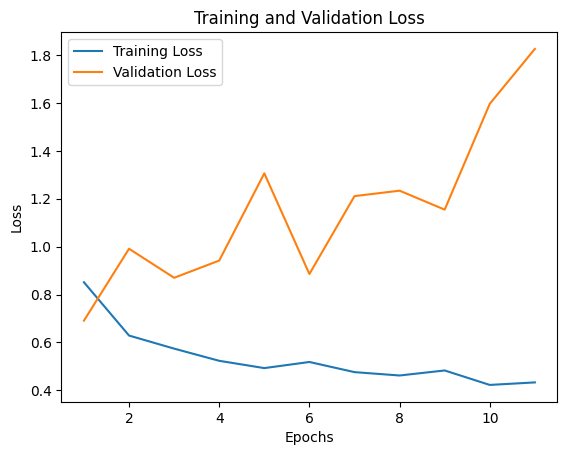

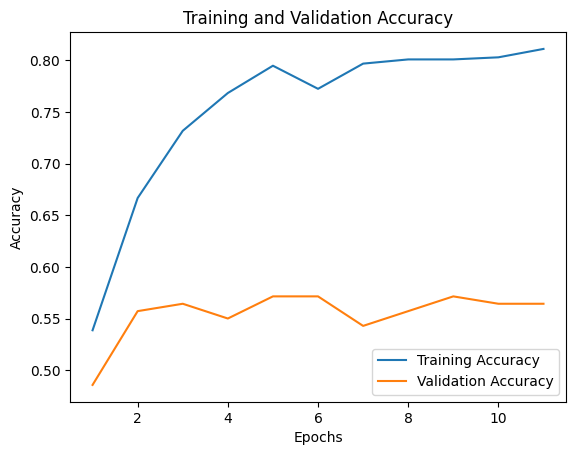

Training time : 47.67
Validation time : 10.67


In [ ]:
# MODEL

class CNN(nn.Module):

  def __init__(self, n_classes = 2):
    super().__init__()

    self.layers = nn.Sequential (
        nn.Conv2d(in_channels=3, out_channels = 128, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2),
        nn.Dropout(0.3),

        nn.Conv2d(128, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.5),

        nn.Conv2d(64, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.5),

        nn.Flatten(),
        nn.Linear(43264, 16),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(16, 2),
    )

  def forward(self, x):
    return self.layers(x)

model = CNN()


# TRAINING

# device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# optimizer
optimizer = optim.Adam(model.parameters(), lr = 0.001)

#loss function
loss_fn = nn.CrossEntropyLoss()

# save path
path_classification = '/content/drive/MyDrive/MSc Data Science/Thesis/Codes/classification'
save_path = os.path.join(path_classification, 'custom_run0_noaug.pt')

history = model_train_save_es(model, train_dl, val_dl,
             optimizer, loss_fn, save_path, epochs = 50, patience = 10, device = device
)

#plot
plot_results_new(history)

# total time taken for training and validation
print(f"Training time : {sum(history['Training']['Time']):.2f}")
print(f"Validation time : {sum(history['Validation']['Time']):.2f}")

### Load and Predict

Prediction Metrics
Test Accuracy: 0.4722 | f1: 0.6415 | AUC: 0.6309
Sensitivity: 0.9714 | Specificity: 0.0000
Precision: 0.4789| Test Time: 0.7505


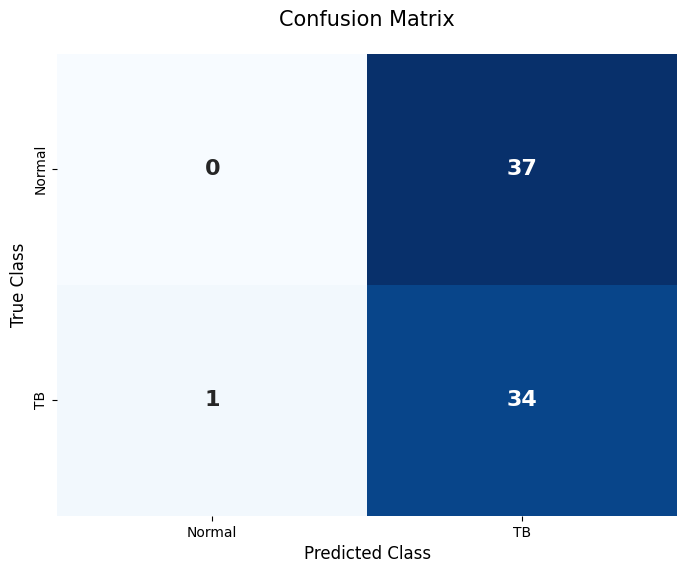

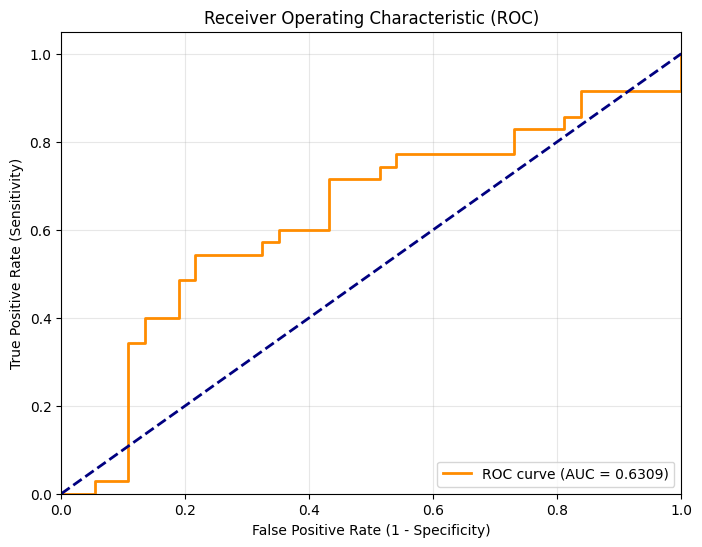

In [ ]:
## DATASET

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torch.optim as optim

from torchvision import transforms as T
from torchvision.datasets import ImageFolder

import matplotlib.pyplot as plt

mean = [0.6146, 0.6146, 0.6146]
std = [0.2556, 0.2556, 0.2556]

transforms = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean=mean, std=std)
])

test_td = ImageFolder(root = './test', transform = transforms)
test_dl = DataLoader(test_td, batch_size = 32)


path_classification = '/content/drive/MyDrive/MSc Data Science/Thesis/Codes/classification'
PATH = os.path.join(path_classification, 'custom_run0_noaug.pt')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = torch.load(PATH, weights_only=False)

predictions, probs, labels = model_predict_new(model, test_dl, device)

### run 1 (aug)

Shekar Architecture

Computing mean and std from training set...


Mean: tensor([0.6146, 0.6146, 0.6146])
Std:  tensor([0.2556, 0.2556, 0.2556])


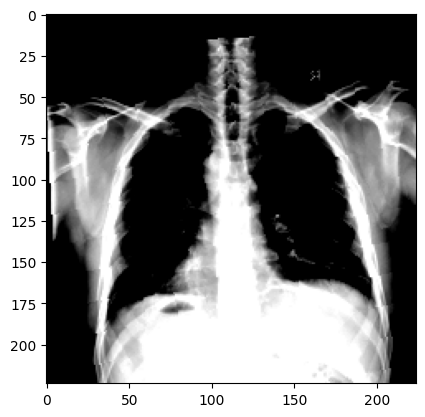

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torch.optim as optim
from torchvision import transforms as T
from torchvision.datasets import ImageFolder
import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# 1. Compute mean and std from the training set
# ------------------------------------------------------------
# We'll use a simple transform without augmentation (only resize + to tensor)
basic_transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor()
])

# Create a temporary dataset to compute statistics
temp_train_ds = ImageFolder(root='./train', transform=basic_transform)

# Function to compute mean and std
def compute_mean_std(dataset, batch_size=64, num_workers=2):
    loader = DataLoader(dataset, batch_size=batch_size, num_workers=num_workers, shuffle=False)

    mean = 0.0
    std = 0.0
    total_pixels = 0

    for images, _ in loader:
        # images shape: (batch, channels, height, width)
        batch_samples = images.size(0)
        images = images.view(batch_samples, images.size(1), -1)  # flatten spatial dims
        # accumulate mean per channel
        mean += images.mean(2).sum(0)
        total_pixels += batch_samples

    mean /= total_pixels

    # second pass for std
    for images, _ in loader:
        batch_samples = images.size(0)
        images = images.view(batch_samples, images.size(1), -1)
        var = ((images - mean.view(1, -1, 1)) ** 2).mean(2).sum(0)
        std += var

    std = torch.sqrt(std / total_pixels)

    return mean, std

print("Computing mean and std from training set...")
mean, std = compute_mean_std(temp_train_ds)
print(f"Mean: {mean}")   # e.g., tensor([0.485, 0.456, 0.406]) if RGB, but for grayscale they will be nearly identical
print(f"Std:  {std}")


# TRANSFORMS

transforms = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean=mean, std=std)      # <--- normalization added
])

# TENSOR DATASETS
train_td = ImageFolder(root = './train', transform = T.Compose([
    T.Resize((224, 224)),
    T.RandomHorizontalFlip(p = 0.5),
    T.RandomAffine(degrees = 10, #patient is not always straight
                       translate = (0.1, 0.1), #shift it vertically and horizontally from the center
                       scale = (0.9, 1.1)), # controls the size of the lungs
    T.ColorJitter(brightness = 0.1, contrast = 0.1),
    T.ToTensor(),
    T.Normalize(mean=mean, std=std)      # <--- normalization added
])
)

val_td = ImageFolder(root = './val', transform = transforms)
test_td = ImageFolder(root = './test', transform = transforms)

# TO BATCHES
train_dl = DataLoader(train_td, batch_size = 32, shuffle = True)
val_dl = DataLoader(val_td, batch_size = 32)
test_dl = DataLoader(test_td, batch_size = 32)

plt.imshow(train_td[0][0].permute(1, 2, 0));

Best model saved at epoch 1
Epoch: [1/50]	 Train Loss: 0.88	    Val Loss: 0.69	 Train Acc: 0.53	 Val Acc: 0.49    Train Time: 4.50	 Val Time: 0.97
Epoch: [2/50]	 Train Loss: 0.66	    Val Loss: 0.70	 Train Acc: 0.63	 Val Acc: 0.51    Train Time: 4.85	 Val Time: 1.02
Epoch: [3/50]	 Train Loss: 0.61	    Val Loss: 0.74	 Train Acc: 0.70	 Val Acc: 0.54    Train Time: 4.52	 Val Time: 0.97
Epoch: [4/50]	 Train Loss: 0.63	    Val Loss: 0.80	 Train Acc: 0.71	 Val Acc: 0.54    Train Time: 4.90	 Val Time: 0.98
Epoch: [5/50]	 Train Loss: 0.56	    Val Loss: 0.92	 Train Acc: 0.72	 Val Acc: 0.54    Train Time: 4.49	 Val Time: 1.01
Epoch: [6/50]	 Train Loss: 0.60	    Val Loss: 0.78	 Train Acc: 0.71	 Val Acc: 0.55    Train Time: 5.22	 Val Time: 1.03
Epoch: [7/50]	 Train Loss: 0.58	    Val Loss: 0.86	 Train Acc: 0.71	 Val Acc: 0.55    Train Time: 4.36	 Val Time: 1.26
Epoch: [8/50]	 Train Loss: 0.58	    Val Loss: 0.86	 Train Acc: 0.74	 Val Acc: 0.56    Train Time: 4.61	 Val Time: 0.97
Epoch: [9/50]	 Train

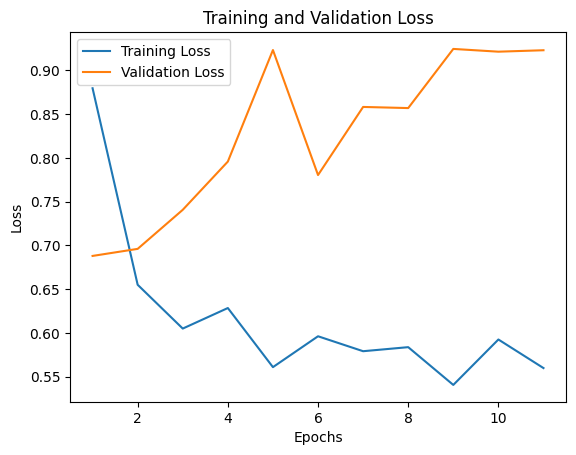

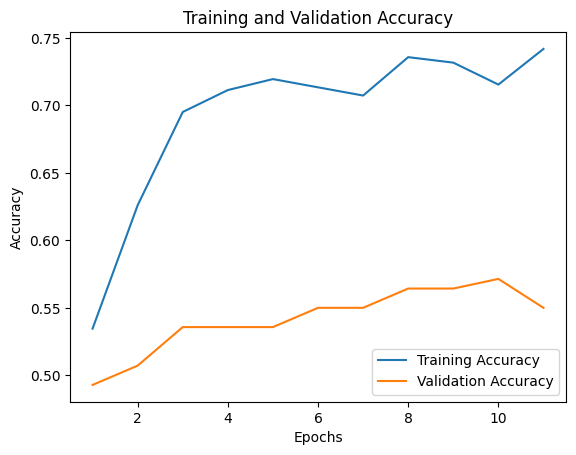

Training time : 51.41
Validation time : 11.22


In [ ]:
# MODEL

class CNN(nn.Module):

  def __init__(self, n_classes = 2):
    super().__init__()

    self.layers = nn.Sequential (
        nn.Conv2d(in_channels=3, out_channels = 128, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2),
        nn.Dropout(0.3),

        nn.Conv2d(128, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.5),

        nn.Conv2d(64, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.5),

        nn.Flatten(),
        nn.Linear(43264, 16),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(16, 2),
    )

  def forward(self, x):
    return self.layers(x)

model = CNN()


# TRAINING

# device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# optimizer
optimizer = optim.Adam(model.parameters(), lr = 0.001)

#loss function
loss_fn = nn.CrossEntropyLoss()

# save path
path_classification = '/content/drive/MyDrive/MSc Data Science/Thesis/Codes/classification'
save_path = os.path.join(path_classification, 'custom_run1_aug.pt')

history = model_train_save_es(model, train_dl, val_dl,
             optimizer, loss_fn, save_path, epochs = 50, patience = 10, device = device
)

#plot
plot_results_new(history)

# total time taken for training and validation
print(f"Training time : {sum(history['Training']['Time']):.2f}")
print(f"Validation time : {sum(history['Validation']['Time']):.2f}")

### Load and Predict

Prediction Metrics
Test Accuracy: 0.4861 | f1: 0.6542 | AUC: 0.5645
Sensitivity: 1.0000 | Specificity: 0.0000
Precision: 0.4861| Test Time: 0.6983


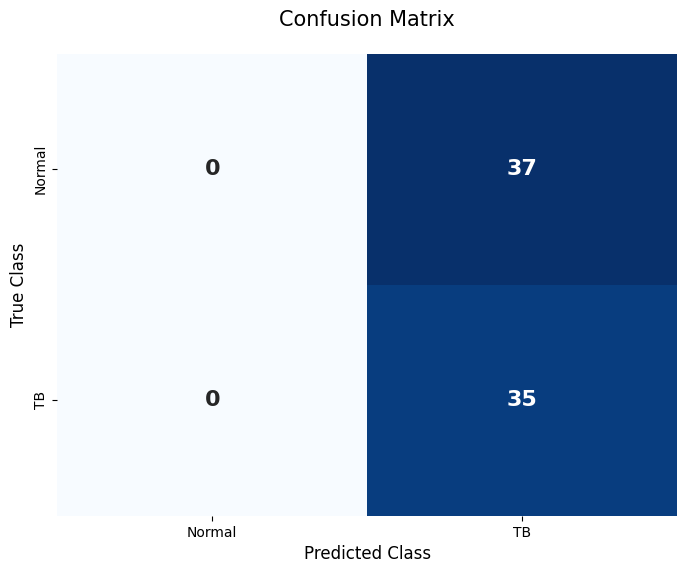

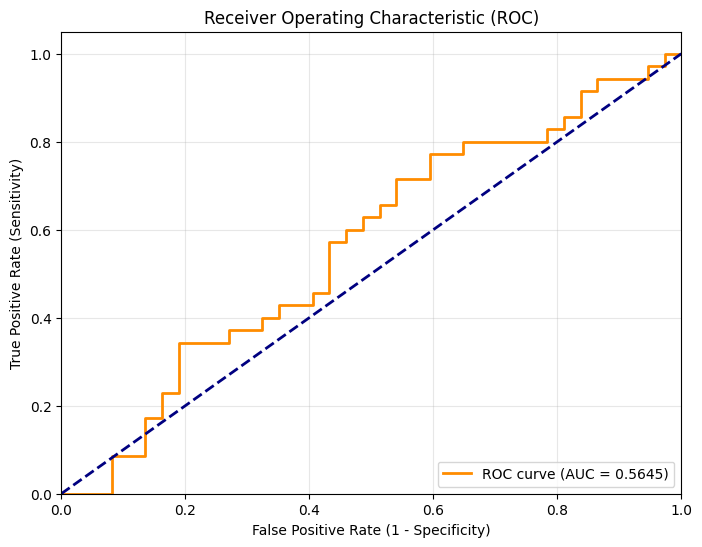

In [ ]:
## DATASET

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torch.optim as optim

from torchvision import transforms as T
from torchvision.datasets import ImageFolder

import matplotlib.pyplot as plt

mean = [0.485, 0.456, 0.406]
std = [0.2556, 0.2556, 0.2556]

transforms = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean=mean, std=std)      # <--- normalization added
])

test_td = ImageFolder(root = './test', transform = transforms)
test_dl = DataLoader(test_td, batch_size = 32)

path_classification = '/content/drive/MyDrive/MSc Data Science/Thesis/Codes/classification'
PATH = os.path.join(path_classification, 'custom_run1_aug.pt')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = torch.load(PATH, weights_only=False)

predictions, probs, labels = model_predict_new(model, test_dl, device)

### run 2 (more features)

We added more filters so that the model may learn more features and possibly overfit, so that we may use data augmentation for regularization and help solve the issue.

Learning more features did not help here. The model performed worse than it did in the previous set-up

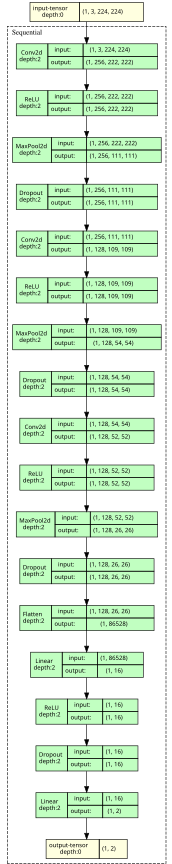

In [ ]:
class CNN(nn.Module):

  def __init__(self, n_classes = 2):
    super().__init__()

    self.layers = nn.Sequential (
        nn.Conv2d(in_channels=3, out_channels = 256, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2),
        nn.Dropout(0.3),

        nn.Conv2d(256, 128, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.5),

        nn.Conv2d(128, 128, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.5),

        nn.Flatten(),
        nn.Linear(86528, 16),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(16, 2),
    )

  def forward(self, x):
    return self.layers(x)

model = CNN()

model_graph = draw_graph(model, input_size=(1, 3, 224, 224),
                         expand_nested=True,
                         hide_inner_tensors=True,
                         hide_module_functions=True
                         )

model_graph.visual_graph

In [ ]:
# device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# optimizer
optimizer = optim.Adam(model.parameters(), lr = 0.001)

#loss function
loss_fn = nn.CrossEntropyLoss()

# save path
save_path = './ex4_run1.pt'

history = model_train_save_es(model, train_dl, val_dl,
             optimizer, loss_fn, save_path, epochs = 100, patience = 10, device = device
)

#plot
plot_results_new(history)

# total time taken for training and validation
print(f"Training time : {sum(history['Training']['Time']):.2f}")
print(f"Validation time : {sum(history['Validation']['Time']):.2f}")

#predict
predictions, labels = model_predict(save_path, test_dl, device)

Epoch: [1/100]	 Train Loss: 0.80	    Val Loss: 0.69	 Train Acc: 0.48	 Val Acc: 0.49    Train Time: 1.05	 Val Time: 0.53
Epoch: [2/100]	 Train Loss: 0.69	    Val Loss: 0.70	 Train Acc: 0.52	 Val Acc: 0.49    Train Time: 1.08	 Val Time: 0.50
Epoch: [3/100]	 Train Loss: 0.69	    Val Loss: 0.69	 Train Acc: 0.51	 Val Acc: 0.49    Train Time: 1.04	 Val Time: 0.50
Epoch: [4/100]	 Train Loss: 0.69	    Val Loss: 0.70	 Train Acc: 0.54	 Val Acc: 0.47    Train Time: 1.03	 Val Time: 0.51
Epoch: [5/100]	 Train Loss: 0.67	    Val Loss: 0.68	 Train Acc: 0.57	 Val Acc: 0.59    Train Time: 1.04	 Val Time: 0.51
Epoch: [6/100]	 Train Loss: 0.63	    Val Loss: 0.68	 Train Acc: 0.67	 Val Acc: 0.60    Train Time: 1.04	 Val Time: 0.52
Epoch: [7/100]	 Train Loss: 0.64	    Val Loss: 0.68	 Train Acc: 0.71	 Val Acc: 0.62    Train Time: 1.03	 Val Time: 0.51
Epoch: [8/100]	 Train Loss: 0.60	    Val Loss: 0.69	 Train Acc: 0.72	 Val Acc: 0.60    Train Time: 1.05	 Val Time: 0.51
Epoch: [9/100]	 Train Loss: 0.64	    Val

NameError: name 'plot_results_new' is not defined

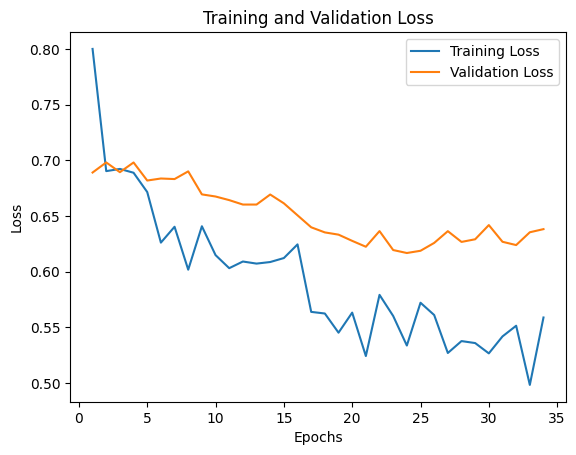

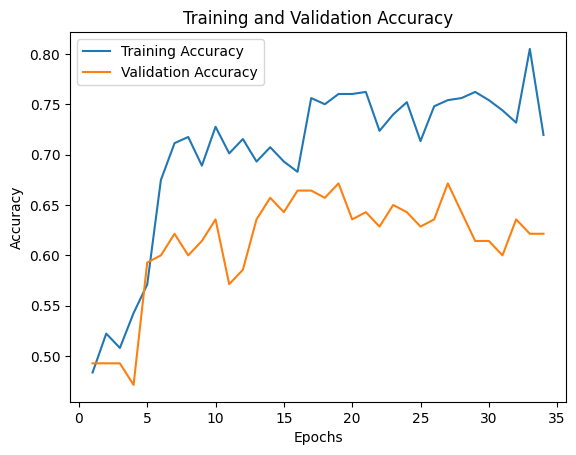

Training time : 35.64
Validation time : 17.59
Prediction Metrics
Confusion Matrix: [[15 22]
 [ 7 28]]
Test Accuracy: 0.60
Test f1: 0.66
Test AUC: 0.64
Time: 0.45


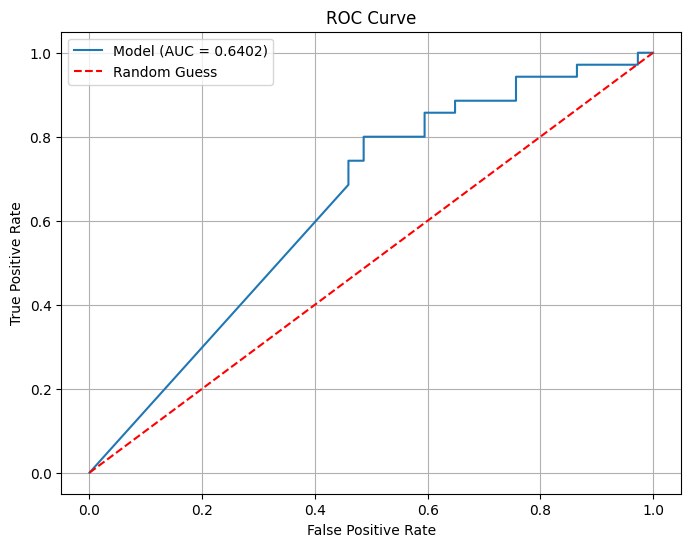

In [ ]:
plot_results_new(history)

# total time taken for training and validation
print(f"Training time : {sum(history['Training']['Time']):.2f}")
print(f"Validation time : {sum(history['Validation']['Time']):.2f}")


#predict
predictions, probs, labels = model_predict(save_path, test_dl, device)

### run 3 (augmentations)

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torch.optim as optim

from torchvision import transforms as T
from torchvision.datasets import ImageFolder

import matplotlib.pyplot as plt

from torchview import draw_graph
# from utils import model_train_save, model_predict, plot_results_new

# TRANSFORMS

transforms = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor()
])

# TENSOR DATASETS
train_td = ImageFolder(root = './train', transform = T.Compose([
    T.Resize((224, 224)),
    T.RandomHorizontalFlip(p = 0.5),
    T.RandomAffine(degrees = 10, #patient is not always straight
                       translate = (0.1, 0.1), #shift it vertically and horizontally from the center
                       scale = (0.9, 1.1)), # controls the size of the lungs
    T.ColorJitter(brightness = 0.1, contrast = 0.1),
    T.RandomApply([T.ElasticTransform(alpha=30.0, sigma=5.0)], p=0.3),
    T.ToTensor(),
])
)

val_td = ImageFolder(root = './val', transform = transforms)
test_td = ImageFolder(root = './test', transform = transforms)

# TO BATCHES
train_dl = DataLoader(train_td, batch_size = 32, shuffle = True)
val_dl = DataLoader(val_td, batch_size = 32)
test_dl = DataLoader(test_td, batch_size = 32)

plt.imshow(train_td[0][0].permute(1, 2, 0));

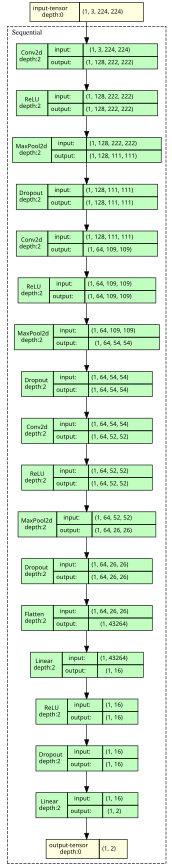

In [ ]:
class CNN(nn.Module):

  def __init__(self, n_classes = 2):
    super().__init__()

    self.layers = nn.Sequential (
        nn.Conv2d(in_channels=3, out_channels = 128, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2),
        nn.Dropout(0.3),

        nn.Conv2d(128, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.5),

        nn.Conv2d(64, 64, kernel_size = 3),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),
        nn.Dropout(0.5),

        nn.Flatten(),
        nn.Linear(43264, 16),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(16, 2),
    )

  def forward(self, x):
    return self.layers(x)

model = CNN()

model_graph = draw_graph(model, input_size=(1, 3, 224, 224),
                         expand_nested=True,
                         hide_inner_tensors=True,
                         hide_module_functions=True
                         )

model_graph.visual_graph

In [ ]:
# device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# optimizer
optimizer = optim.Adam(model.parameters(), lr = 0.001)

#loss function
loss_fn = nn.CrossEntropyLoss()

# save path
save_path = './run3.pt'

history = model_train_save_es(model, train_dl, val_dl,
             optimizer, loss_fn, save_path, epochs = 100, patience = 10, device = device
)

#plot
plot_results_new(history)

# total time taken for training and validation
print(f"Training time : {sum(history['Training']['Time']):.2f}")
print(f"Validation time : {sum(history['Validation']['Time']):.2f}")


#predict
predictions, probs, labels = model_predict(save_path, test_dl, device)

Epoch: [1/100]	 Train Loss: 0.96	    Val Loss: 0.74	 Train Acc: 0.46	 Val Acc: 0.51    Train Time: 1.23	 Val Time: 0.53
Epoch: [2/100]	 Train Loss: 0.69	    Val Loss: 0.73	 Train Acc: 0.48	 Val Acc: 0.51    Train Time: 1.22	 Val Time: 0.50
Epoch: [3/100]	 Train Loss: 0.70	    Val Loss: 0.73	 Train Acc: 0.50	 Val Acc: 0.51    Train Time: 1.16	 Val Time: 0.56
Epoch: [4/100]	 Train Loss: 0.70	    Val Loss: 0.73	 Train Acc: 0.52	 Val Acc: 0.51    Train Time: 1.27	 Val Time: 0.50
Epoch: [5/100]	 Train Loss: 0.70	    Val Loss: 0.73	 Train Acc: 0.49	 Val Acc: 0.51    Train Time: 1.17	 Val Time: 0.50
Epoch: [6/100]	 Train Loss: 0.70	    Val Loss: 0.73	 Train Acc: 0.49	 Val Acc: 0.51    Train Time: 1.13	 Val Time: 0.49
Epoch: [7/100]	 Train Loss: 0.70	    Val Loss: 0.72	 Train Acc: 0.51	 Val Acc: 0.51    Train Time: 1.14	 Val Time: 0.50
Epoch: [8/100]	 Train Loss: 0.69	    Val Loss: 0.73	 Train Acc: 0.55	 Val Acc: 0.51    Train Time: 1.14	 Val Time: 0.49
Epoch: [9/100]	 Train Loss: 0.70	    Val

KeyboardInterrupt: 

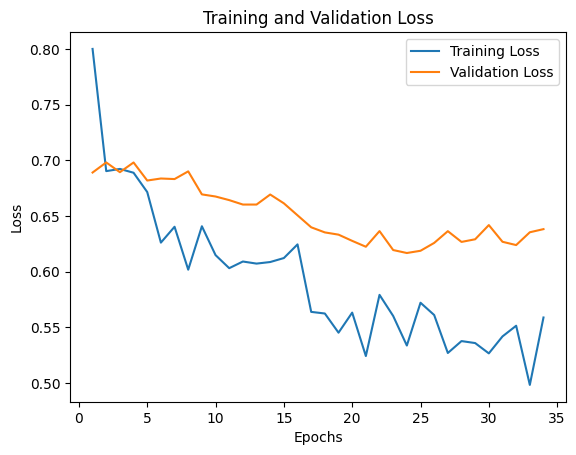

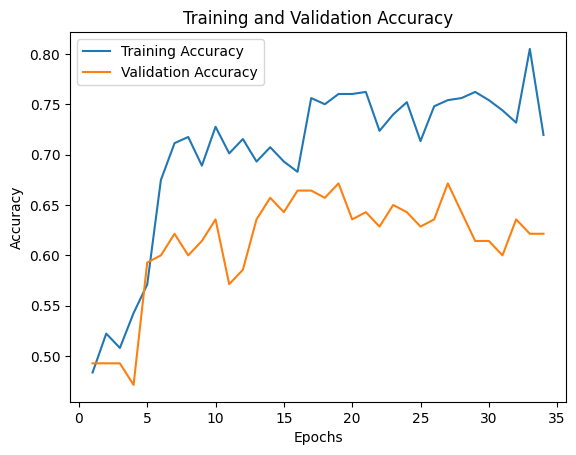

Training time : 35.64
Validation time : 17.59
Prediction Metrics
Confusion Matrix: [[37  0]
 [35  0]]
Test Accuracy: 0.51
Test f1: 0.00
Test AUC: 0.50
Time: 0.46


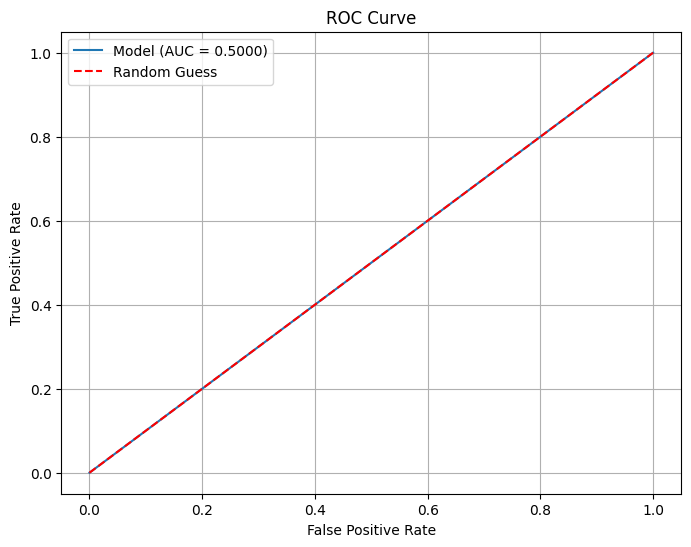

In [ ]:
#plot
plot_results_new(history)

# total time taken for training and validation
print(f"Training time : {sum(history['Training']['Time']):.2f}")
print(f"Validation time : {sum(history['Validation']['Time']):.2f}")

#predict
predictions, probs, labels = model_predict(save_path, test_dl, device)

### grad-CAM

Loading model...
Loading and processing image...
Running Grad-CAM...
Visualizing results...


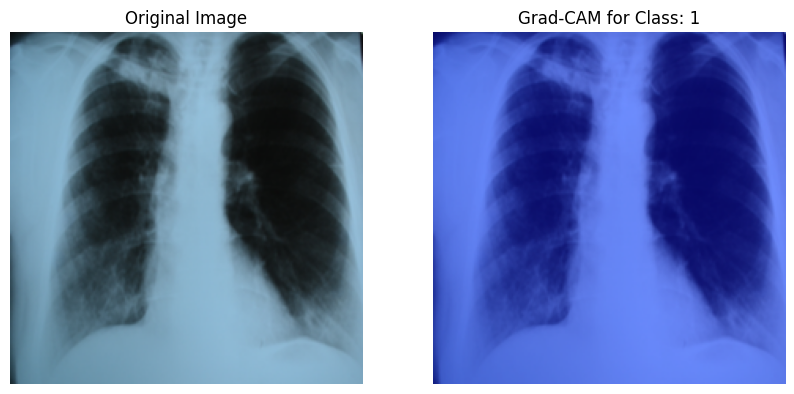

In [ ]:
import torch
import torch.nn as nn
from torchvision import models, transforms as T
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Import the Grad-CAM library
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

# Load model
print("Loading model...")
device = 'cuda' if torch.cuda.is_available() else 'cpu'
save_path = ''

model = torch.load(save_path)
model = model.to(device)
model.eval()

# Identify the Target Layer (Last Conv Layer)
target_layer = model.layers[8]

# Load Images
img_path = ''
img_pil = Image.open(IMAGE_PATH).convert('RGB')

# Transform the images

val_transforms = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
])


input_tensor = val_transforms(img_pil).unsqueeze(0).to(device) # [1, 3, 224, 224]

# Grad-CAM

cam = GradCAM(model=model,
              target_layers=[target_layer],
              )

TARGET_CLASS = 1
targets = [ClassifierOutputTarget(TARGET_CLASS)]

#Generate the CAM
# This runs the model, gets gradients and activations, and computes the map
grayscale_cam = cam(input_tensor=input_tensor, targets=targets)

# D. Get the first (and only) map from the batch.. this is the combo of all maps
grayscale_cam = grayscale_cam[0, :]

# Visualize the Results
# Get the permuted image for plotting
rgb_img_for_plot = input_tensor.squeeze(0).permute(1, 2, 0).cpu().numpy()

# Overlay the CAM heatmap on the original image
cam_image = show_cam_on_image(rgb_img_for_plot, grayscale_cam, use_rgb=True)

# Plot
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(rgb_img_for_plot)
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cam_image)
plt.title(f"Grad-CAM for Class: {TARGET_CLASS}")
plt.axis('off')

plt.show()

In [ ]:
import os
import random
import torch
import torch.nn as nn
from torchvision import transforms as T
from torchvision.datasets import ImageFolder
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

# Import Grad-CAM
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

# -------------------- CONFIGURATION --------------------
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model_path = 'path/to/your/model.pth'          # update this
data_dir = 'path/to/test'                      # or 'val' folder containing class subfolders
num_images_per_class = 2                        # how many images to visualize per class
image_size = (224, 224)                         # match your model's expected input size

# Define the model architecture (must match the saved model)
class CNN(nn.Module):
    def __init__(self, n_classes=2):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(3, 128, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout(0.3),

            nn.Conv2d(128, 64, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout(0.5),

            nn.Conv2d(64, 64, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout(0.5),

            nn.Flatten(),
            nn.Linear(43264, 16),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(16, 2)
        )

    def forward(self, x):
        return self.layers(x)

# -------------------- LOAD MODEL --------------------
def load_model(model_path, device):
    # Try loading full model first
    try:
        model = torch.load(model_path, map_location=device)
        print("Loaded full model.")
    except Exception as e:
        # If that fails, assume it's a state dict
        print("Full model load failed, trying state dict...")
        model = CNN().to(device)
        state_dict = torch.load(model_path, map_location=device)
        model.load_state_dict(state_dict)
        print("Loaded state dict.")
    model.eval()
    return model

model = load_model(model_path, device)

# -------------------- FIND LAST CONV LAYER --------------------
def find_last_conv_layer(model):
    last_conv = None
    for name, module in model.named_modules():
        if isinstance(module, nn.Conv2d):
            last_conv = module
    if last_conv is None:
        raise ValueError("No convolutional layer found in the model.")
    return last_conv

target_layer = find_last_conv_layer(model)
print(f"Using target layer: {target_layer}")

# -------------------- PREPARE DATA --------------------
# Use ImageFolder to get class names and paths
dataset = ImageFolder(root=data_dir, transform=None)  # no transform yet, we'll apply later
class_names = dataset.classes
print(f"Classes: {class_names}")

# Build a list of image paths per class
paths_per_class = {cls: [] for cls in class_names}
for path, label in dataset.samples:
    cls = class_names[label]
    paths_per_class[cls].append(path)

# Select the desired number of images per class
selected_images = []
for cls in class_names:
    paths = paths_per_class[cls]
    # Randomly choose num_images_per_class (or all if fewer exist)
    selected = random.sample(paths, min(num_images_per_class, len(paths)))
    selected_images.extend([(cls, p) for p in selected])

# -------------------- TRANSFORM --------------------
# Note: if you used normalization during training, include it here.
val_transforms = T.Compose([
    T.Resize(image_size),
    T.ToTensor(),
    # T.Normalize(mean=[...], std=[...])   # uncomment if needed
])

# -------------------- GRAD-CAM LOOP --------------------
cam = GradCAM(model=model, target_layers=[target_layer])

# We'll create a grid plot
fig, axes = plt.subplots(len(selected_images), 2, figsize=(8, 3*len(selected_images)))
if len(selected_images) == 1:
    axes = axes.reshape(1, -1)  # make sure axes is 2D

for i, (cls_name, img_path) in enumerate(selected_images):
    # Load and transform image
    pil_img = Image.open(img_path).convert('RGB')
    input_tensor = val_transforms(pil_img).unsqueeze(0).to(device)  # [1,3,H,W]

    # --- Determine target class ---
    # Option 1: Use the actual class index (0 or 1) if you know the mapping.
    # Here we let Grad-CAM target the predicted class (most confident).
    # Alternatively, you can set targets = [ClassifierOutputTarget(0 or 1)] manually.
    # For automatic mapping: run a forward pass to get logits, then use argmax.
    with torch.no_grad():
        logits = model(input_tensor)
        pred_class = logits.argmax(dim=1).item()
    targets = None  # None uses the predicted class (internally GradCAM will use the highest scoring category)

    # Generate Grad-CAM
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)
    grayscale_cam = grayscale_cam[0, :]  # take the first (and only) map

    # Prepare image for overlay (denormalize if needed)
    rgb_img = input_tensor.squeeze(0).permute(1, 2, 0).cpu().numpy()
    # If you normalized, you need to unnormalize here (omitted for simplicity)

    # Overlay heatmap
    cam_image = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

    # Plot
    axes[i, 0].imshow(rgb_img)
    axes[i, 0].set_title(f"{cls_name} (true)")
    axes[i, 0].axis('off')

    axes[i, 1].imshow(cam_image)
    axes[i, 1].set_title(f"Grad-CAM (pred: {class_names[pred_class]})")
    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()